# Kidney Perturbation Analysis

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 28.01.2026
- Date of Last Modification: 01.02.2026 (by Sebastian Birk; sb75@sanger.ac.uk)

# 1. Setup

## 1.1 Load Libraries

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scanpy as sc
import scipy.sparse as sp
import torch
from datasets import load_from_disk

#from app.count_decoder import apply_count_decoder
from app.infer import embed_dataset, harmonize_tokenize_embed_pipeline, perturb_dataset
from nichejepa.preprocessors import construct_neighbor_graph

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


## 1.2 Define Config/Params

In [3]:
# Define paths
#model_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11012026_190057_836' # cross-tissue model
model_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614' # benchmarking model
gene_ensembl_map_file_path = '/nfs/team361/sb75/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl'
kidney_perturbation_folder_path = '/nfs/team361/sb75/DATASETS/gold/cell-graph-tokenizer/kidney_perturbation'
cache_directory_path = f'{kidney_perturbation_folder_path}/cache'
results_directory_path = f'{kidney_perturbation_folder_path}/results'
tokenized_data_directory_path = f'{kidney_perturbation_folder_path}/tokenized_data'

In [143]:
cell_type_key = "scANVI_pred"
niche_key = "NEMO_neighborhood_annotation"
batch_key = 'Study_slice_id'

emb_layer = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None
top_k = None

## 1.3 Run Notebook Setup

In [5]:
torch.set_printoptions(threshold=float('inf'))

In [6]:
os.makedirs(tokenized_data_directory_path, exist_ok=True)
os.makedirs(f'{results_directory_path}/figures', exist_ok=True)

In [7]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [8]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [9]:
sc.settings.figdir = f'{results_directory_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(6, 4),
    facecolor='white',
    fontsize=10
)

## 1.4 Define Functions

In [139]:
def cosine_sim_per_row(A, B, eps=1e-12):
    """
    Row-wise cosine similarity between A and B (shape: [n, d]).
    Handles zero-norm rows safely via eps.
    """
    A = np.asarray(A)
    B = np.asarray(B)

    A_norm = np.linalg.norm(A, axis=1, keepdims=True)
    B_norm = np.linalg.norm(B, axis=1, keepdims=True)

    A_unit = A / np.maximum(A_norm, eps)
    B_unit = B / np.maximum(B_norm, eps)

    return np.sum(A_unit * B_unit, axis=1)

In [140]:
def analyze_embedding_cos_sims(
    adata,
    pairs=None,
    bins=50,
    show=True,
    save_dir=None,
    prefix="",
    eps=1e-12,
):
    """
    Compute row-wise cosine similarities for multiple (A_key, B_key) pairs in adata.obsm,
    print mean/min, and optionally plot + save histograms.

    Returns
    -------
    results : dict[str, np.ndarray]
        Mapping from name -> cosine similarity vector (length n_obs).
    summary : dict[str, dict[str, float]]
        Mapping from name -> {"mean": ..., "min": ...}
    """
    if pairs is None:
        pairs = [
            ("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
            ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
            ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb"),
        ]

    results = {}
    summary = {}

    for A_key, B_key, name in pairs:
        A = adata.obsm[A_key]
        B = adata.obsm[B_key]

        sims = cosine_sim_per_row(A, B, eps=eps)

        mean_v = float(np.mean(sims))
        min_v = float(np.min(sims))

        results[name] = sims
        summary[name] = {"mean": mean_v, "min": min_v}

        print(f"{name}: mean={mean_v:.6f}  min={min_v:.6f}")

        plt.figure()
        plt.hist(sims, bins=bins)
        plt.title(f"{prefix}{name} cosine similarity")
        plt.xlabel("cosine similarity")
        plt.ylabel("count")
        plt.tight_layout()

        if save_dir is not None:
            fname = f"{prefix}{name}_cos_sim_hist.png" if prefix else f"{name}_cos_sim_hist.png"
            plt.savefig(f"{save_dir.rstrip('/')}/{fname}", dpi=200)

        if show:
            plt.show()
        else:
            plt.close()

    return results, summary

In [147]:
def summarize_cosine_sim_by_label(
    adata,
    label_key,
    labels=None,
    pairs=None,
    agg="mean",
    sort_by=None,
    ascending=True,
    eps=1e-12,
):
    """
    Compute cosine similarity (row-wise) between embedding pairs in adata.obsm,
    aggregate per label in adata.obs[label_key], and return a sorted DataFrame.

    Parameters
    ----------
    adata : AnnData
        AnnData containing obs[label_key] and obsm embeddings.
    label_key : str
        Column in adata.obs defining the grouping label (e.g. cell type, cluster, condition).
    labels : list[str] | None
        Labels to evaluate. If None, uses sorted unique values from obs[label_key].
    pairs : list[tuple[str, str, str]] | None
        List of (A_key, B_key, out_col) where A_key/B_key are obsm keys.
    agg : {"min","mean","median"} or callable
        Aggregation over cells within each label.
    sort_by : str | None
        Column to sort by. If None, no sorting is applied.
    ascending : bool
        Sort order.
    eps : float
        Numerical stability for normalization.

    Returns
    -------
    df : pd.DataFrame
        One row per label with aggregated cosine similarity columns.
    """
    if pairs is None:
        pairs = [
            ("cell_emb", "cell_emb_perturb_case1", "cell_emb_cos_sim"),
            ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb_cos_sim"),
            ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb_cos_sim"),
        ]

    if labels is None:
        labels = sorted(pd.unique(adata.obs[label_key]))

    if isinstance(agg, str):
        agg_name = agg.lower()
        if agg_name == "min":
            agg_fn = np.min
        elif agg_name == "mean":
            agg_fn = np.mean
        elif agg_name == "median":
            agg_fn = np.median
        else:
            raise ValueError("agg must be 'min', 'mean', 'median', or a callable")
    elif callable(agg):
        agg_fn = agg
    else:
        raise ValueError("agg must be 'min', 'mean', 'median', or a callable")

    rows = []
    for label in labels:
        adata_sub = adata[adata.obs[label_key] == label]

        row = {
            "label": label,
            "n_cells": int(adata_sub.n_obs),
        }

        for A_key, B_key, out_col in pairs:
            sims = cosine_sim_per_row(
                adata_sub.obsm[A_key],
                adata_sub.obsm[B_key],
                eps=eps,
            )
            row[out_col] = float(agg_fn(sims))

        rows.append(row)

    df = pd.DataFrame(rows)

    if sort_by is not None:
        df = df.sort_values(by=sort_by, ascending=ascending).reset_index(drop=True)

    return df

# 2. Analysis

## 2.1 Load Data

In [ ]:
# Load original raw data
adata = sc.read_h5ad(
    "/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/NEMO_UpdatedTokenisationandEmbedding_November22nd25/Labeltransfer/forshare/nemokidneyxeniumatlas_annotated.h5ad")
adata

In [ ]:
# Check columns
adata.obs.head(1)

In [ ]:
# List samples
# CV*** -> pre-treatment
# DI*** -> post-treatment
adata.obs[['Study_slice_id', 'Data_source']].drop_duplicates()

In [ ]:
# Compute sample-wise neighbor graph, concatenate, and store in adata.obsp['spatial_connectivities']
adata = construct_neighbor_graph(
    adata,
    n_neighs=10,
    radius=None,
    delaunay=False,
    include_self_loop=False,
    compute_neighbor_counts=False,
    batch_key=batch_key
)

# Compute raw neighborhood counts
adata.layers['counts_neighborhood'] = (
    adata.obsp['spatial_connectivities'].T @ adata.layers['counts'])
print(adata.layers['counts_neighborhood'][:30].toarray())
adata.layers['counts_neighborhood'] += adata.layers['counts'] # add counts from the index cell
print(adata.layers['counts_neighborhood'][:30].toarray())

# Compute lognorm neighborhood counts (performing same normalization as on raw counts)
adata.X = adata.layers["counts_neighborhood"].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.layers["lognorm_neighborhood"] = adata.X.copy()
adata.X = adata.layers["lognorm"].copy()

In [ ]:
# Validate that everything is ok
print(adata.obsp['spatial_connectivities'].sum(1))
n = 30
print(adata.layers['counts_neighborhood'][:30].toarray())
print(adata.layers['lognorm_neighborhood'][:30].toarray())
print(adata.layers['counts'][:30].toarray())
print(adata.layers['lognorm'][:30].toarray())
print(adata.X[:30].toarray())

In [ ]:
# Add ensembl IDs to AnnData object
with open(gene_ensembl_map_file_path, "rb") as f:
    gene_ensembl_map_dict = pickle.load(f)

gene_names = [gene_name for gene_name in adata.var_names.tolist()]
adata.var.index = gene_names

harmonized_gene_names = []
matching_ensembl_ids = []
for gene_name in gene_names:
    if gene_name in gene_ensembl_map_dict.keys():
        harmonized_gene_names.append(gene_name)
        matching_ensembl_ids.append(gene_ensembl_map_dict[gene_name])

adata.var['ensembl_id'] = matching_ensembl_ids
adata.var

In [ ]:
# Write AnnData to disk
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

## 2.2 Compute Differential Genes Between Pre- and Post-treatment Conditions

Check https://docs.google.com/spreadsheets/d/1i6p3QRTE5Lh32AejWE6Xg2Sye6p3yP7vDdrCMDbLj_I/edit?gid=1921994032#gid=1921994032 for perturbation cases to be tested.

In [16]:
# Load processed AnnData
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

### 2.2.1 Perturbation Case 1

In [17]:
sid = adata.obs["Study_slice_id"].astype(str)

adata.obs["DI12_vs_CV"] = np.nan
adata.obs.loc[sid.eq("DI12-KID-0-FT-4"), "DI12_vs_CV"] = "DI12"
adata.obs.loc[sid.str.startswith("CV"), "DI12_vs_CV"] = "CV"

adata.obs["DI12_vs_CV"] = adata.obs["DI12_vs_CV"].astype("category")
adata.obs["DI12_vs_CV"].value_counts(dropna=False)

/tmp/ipykernel_675275/1722265279.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'DI12' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  adata.obs.loc[sid.eq("DI12-KID-0-FT-4"), "DI12_vs_CV"] = "DI12"


DI12_vs_CV
CV      1081189
NaN      384726
DI12      51979
Name: count, dtype: int64

In [ ]:
# Compute differential genes for cell counts (across all cells -> global)
sc.tl.rank_genes_groups(
    adata,
    groupby="DI12_vs_CV",
    groups=["DI12"],
    reference="CV",
    method="wilcoxon",
    pts=True,
    use_raw=False,
    key_added="rank_genes_groups_case1_global_pre_post_cell_counts",
)

# Retrieve differential genes for cell counts
n = 50
diff_genes_df = sc.get.rank_genes_groups_df(adata, group="DI12", key="rank_genes_groups_case1_global_pre_post_cell_counts")
diff_genes_df_top = diff_genes_df.head(n)
diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
display(diff_genes_df_top)
diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case1_global_pre_post_cell_counts.csv")

In [ ]:
# Compute differential genes for cell counts (across each niche)
# Loop over niches and run DE within each
min_cells_per_group = 20

summary_rows = []

# Get categories (handles categorical + non-categorical)
cats = adata.obs[niche_key].astype("category").cat.categories

for cat in cats:
    # Cells in this niche AND in either DI12 or CV
    mask = (adata.obs[niche_key] == cat) & (adata.obs["DI12_vs_CV"].isin(["DI12", "CV"]))
    n_total = int(mask.sum())
    if n_total == 0:
        summary_rows.append({"niche": str(cat), "status": "skipped (no DI12/CV cells)", "n_DI12": 0, "n_CV": 0})
        continue

    sub = adata[mask].copy() # copy so we can compute safely without view warnings

    counts = sub.obs["DI12_vs_CV"].value_counts()
    n_di12 = int(counts.get("DI12", 0))
    n_cv   = int(counts.get("CV", 0))

    if n_di12 < min_cells_per_group or n_cv < min_cells_per_group:
        summary_rows.append({
            "niche": str(cat),
            "status": f"skipped (too few cells; min={min_cells_per_group})",
            "n_DI12": n_di12,
            "n_CV": n_cv
        })
        continue

    key = f"rank_genes_groups_case1_niche={cat}_pre_post_cell_counts"

    sc.tl.rank_genes_groups(
        sub,
        groupby="DI12_vs_CV",
        groups=["DI12"],
        reference="CV",
        method="wilcoxon",
        pts=True,
        use_raw=False,
        key_added=key,
    )

    # Retrieve differential genes for cell counts
    n = 50
    diff_genes_df = sc.get.rank_genes_groups_df(sub, group="DI12", key=key)
    diff_genes_df_top = diff_genes_df.head(n)
    diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
    display(diff_genes_df_top)
    diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case1_niche_{cat}_pre_post_cell_counts.csv")
    
    # Store results on the original adata
    adata.uns[key] = sub.uns[key]

    summary_rows.append({
        "niche": str(cat),
        "status": "ok",
        "n_DI12": n_di12,
        "n_CV": n_cv,
        "uns_key": key
    })

# Store a summary table on the AnnData for bookkeeping
adata.uns["DE_case1_pre_post_cell_counts_summary_by_niche"] = pd.DataFrame(summary_rows)
adata.uns["DE_case1_pre_post_cell_counts_summary_by_niche"]

In [ ]:
# Compute differential genes for neighborhood counts
adata.X = adata.layers['lognorm_neighborhood'].copy()
sc.tl.rank_genes_groups(
    adata,
    groupby="DI12_vs_CV",
    groups=["DI12"],
    reference="CV",
    method="wilcoxon",
    pts=True,
    use_raw=False,
    key_added="rank_genes_groups_case1_global_pre_post_neighborhood_counts",
)

# Retrieve differential genes for neighborhood counts
n = 50
diff_genes_df = sc.get.rank_genes_groups_df(adata, group="DI12", key="rank_genes_groups_case1_global_pre_post_neighborhood_counts")
diff_genes_df_top = diff_genes_df.head(n)
diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
display(diff_genes_df_top)
diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case1_pre_post_neighborhood_counts.csv")

In [ ]:
# Compute differential genes for neighborhood counts (across each niche)
# Loop over niches and run DE within each
min_cells_per_group = 20

summary_rows = []

# Get categories (handles categorical + non-categorical)
cats = adata.obs[niche_key].astype("category").cat.categories

for cat in cats:
    # Cells in this niche AND in either DI12 or CV
    mask = (adata.obs[niche_key] == cat) & (adata.obs["DI12_vs_CV"].isin(["DI12", "CV"]))
    n_total = int(mask.sum())
    if n_total == 0:
        summary_rows.append({"niche": str(cat), "status": "skipped (no DI12/CV cells)", "n_DI12": 0, "n_CV": 0})
        continue

    sub = adata[mask].copy() # copy so we can compute safely without view warnings

    counts = sub.obs["DI12_vs_CV"].value_counts()
    n_di12 = int(counts.get("DI12", 0))
    n_cv   = int(counts.get("CV", 0))

    if n_di12 < min_cells_per_group or n_cv < min_cells_per_group:
        summary_rows.append({
            "niche": str(cat),
            "status": f"skipped (too few cells; min={min_cells_per_group})",
            "n_DI12": n_di12,
            "n_CV": n_cv
        })
        continue

    key = f"rank_genes_groups_case1_niche={cat}_pre_post_neighborhood_counts"

    sc.tl.rank_genes_groups(
        sub,
        groupby="DI12_vs_CV",
        groups=["DI12"],
        reference="CV",
        method="wilcoxon",
        pts=True,
        use_raw=False,
        key_added=key,
    )

    # Retrieve differential genes for cell counts
    n = 50
    diff_genes_df = sc.get.rank_genes_groups_df(sub, group="DI12", key=key)
    diff_genes_df_top = diff_genes_df.head(n)
    diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
    display(diff_genes_df_top)
    diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case1_niche_{cat}_pre_post_neighborhood_counts.csv")
    
    # Store results on the original adata
    adata.uns[key] = sub.uns[key]

    summary_rows.append({
        "niche": str(cat),
        "status": "ok",
        "n_DI12": n_di12,
        "n_CV": n_cv,
        "uns_key": key
    })

# Store a summary table on the AnnData for bookkeeping
adata.uns["DE_case1_pre_post_neighborhood_counts_summary_by_niche"] = pd.DataFrame(summary_rows)
adata.uns["DE_case1_pre_post_neighborhood_counts_summary_by_niche"]

In [ ]:
adata.X = adata.layers['lognorm'].copy()

In [ ]:
# Write AnnData to disk
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

### 2.2.2 Perturbation Case 2

In [ ]:
# Load processed AnnData
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

In [ ]:
sid = adata.obs["Study_slice_id"].astype(str)

adata.obs["DI10_vs_CV"] = np.nan
adata.obs.loc[sid.eq("DI10-KID-0-FT-5"), "DI10_vs_CV"] = "DI10"
adata.obs.loc[sid.str.startswith("CV"), "DI10_vs_CV"] = "CV"

adata.obs["DI10_vs_CV"] = adata.obs["DI10_vs_CV"].astype("category")
adata.obs["DI10_vs_CV"].value_counts(dropna=False)

In [ ]:
# Compute differential genes for cell counts (across all cells -> global)
sc.tl.rank_genes_groups(
    adata,
    groupby="DI10_vs_CV",
    groups=["DI10"],
    reference="CV",
    method="wilcoxon",
    pts=True,
    use_raw=False,
    key_added="rank_genes_groups_case2_global_pre_post_cell_counts",
)

# Retrieve differential genes for cell counts
n = 50
diff_genes_df = sc.get.rank_genes_groups_df(adata, group="DI10", key="rank_genes_groups_case2_global_pre_post_cell_counts")
diff_genes_df_top = diff_genes_df.head(n)
diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
display(diff_genes_df_top)
diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case2_global_pre_post_cell_counts.csv")

In [ ]:
# Compute differential genes for cell counts (across each niche)
# Loop over niches and run DE within each
min_cells_per_group = 20

summary_rows = []

# Get categories (handles categorical + non-categorical)
cats = adata.obs[niche_key].astype("category").cat.categories

for cat in cats:
    # Cells in this niche AND in either DI10 or CV
    mask = (adata.obs[niche_key] == cat) & (adata.obs["DI10_vs_CV"].isin(["DI10", "CV"]))
    n_total = int(mask.sum())
    if n_total == 0:
        summary_rows.append({"niche": str(cat), "status": "skipped (no DI10/CV cells)", "n_DI10": 0, "n_CV": 0})
        continue

    sub = adata[mask].copy() # copy so we can compute safely without view warnings

    counts = sub.obs["DI10_vs_CV"].value_counts()
    n_di10 = int(counts.get("DI10", 0))
    n_cv   = int(counts.get("CV", 0))

    if n_di10 < min_cells_per_group or n_cv < min_cells_per_group:
        summary_rows.append({
            "niche": str(cat),
            "status": f"skipped (too few cells; min={min_cells_per_group})",
            "n_DI10": n_di10,
            "n_CV": n_cv
        })
        continue

    key = f"rank_genes_groups_case2_niche={cat}_pre_post_cell_counts"

    sc.tl.rank_genes_groups(
        sub,
        groupby="DI10_vs_CV",
        groups=["DI10"],
        reference="CV",
        method="wilcoxon",
        pts=True,
        use_raw=False,
        key_added=key,
    )

    # Retrieve differential genes for cell counts
    n = 50
    diff_genes_df = sc.get.rank_genes_groups_df(sub, group="DI10", key=key)
    diff_genes_df_top = diff_genes_df.head(n)
    diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
    display(diff_genes_df_top)
    diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case2_niche_{cat}_pre_post_cell_counts.csv")
    
    # Store results on the original adata
    adata.uns[key] = sub.uns[key]

    summary_rows.append({
        "niche": str(cat),
        "status": "ok",
        "n_DI10": n_di10,
        "n_CV": n_cv,
        "uns_key": key
    })

# Store a summary table on the AnnData for bookkeeping
adata.uns["DE_case2_pre_post_cell_counts_summary_by_niche"] = pd.DataFrame(summary_rows)
adata.uns["DE_case2_pre_post_cell_counts_summary_by_niche"]

In [ ]:
# Compute differential genes for neighborhood counts (across all cells -> global)
adata.X = adata.layers['lognorm_neighborhood'].copy()
sc.tl.rank_genes_groups(
    adata,
    groupby="DI10_vs_CV",
    groups=["DI10"],
    reference="CV",
    method="wilcoxon",
    pts=True,
    use_raw=False,
    key_added="rank_genes_groups_case2_global_pre_post_neighborhood_counts",
)

# Retrieve differential genes for neighborhood counts
n = 50
diff_genes_df = sc.get.rank_genes_groups_df(adata, group="DI10", key="rank_genes_groups_case2_global_pre_post_neighborhood_counts")
diff_genes_df_top = diff_genes_df.head(n)
diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
display(diff_genes_df_top)
diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case2_global_pre_post_neighborhood_counts.csv")

In [ ]:
# Compute differential genes for neighborhood counts (across each niche)
# Loop over niches and run DE within each
min_cells_per_group = 20

summary_rows = []

# Get categories (handles categorical + non-categorical)
cats = adata.obs[niche_key].astype("category").cat.categories

for cat in cats:
    # Cells in this niche AND in either DI10 or CV
    mask = (adata.obs[niche_key] == cat) & (adata.obs["DI10_vs_CV"].isin(["DI10", "CV"]))
    n_total = int(mask.sum())
    if n_total == 0:
        summary_rows.append({"niche": str(cat), "status": "skipped (no DI10/CV cells)", "n_DI10": 0, "n_CV": 0})
        continue

    sub = adata[mask].copy() # copy so we can compute safely without view warnings

    counts = sub.obs["DI10_vs_CV"].value_counts()
    n_di10 = int(counts.get("DI10", 0))
    n_cv   = int(counts.get("CV", 0))

    if n_di10 < min_cells_per_group or n_cv < min_cells_per_group:
        summary_rows.append({
            "niche": str(cat),
            "status": f"skipped (too few cells; min={min_cells_per_group})",
            "n_DI10": n_di10,
            "n_CV": n_cv
        })
        continue

    key = f"rank_genes_groups_case2_niche={cat}_pre_post_neighborhood_counts"

    sc.tl.rank_genes_groups(
        sub,
        groupby="DI10_vs_CV",
        groups=["DI10"],
        reference="CV",
        method="wilcoxon",
        pts=True,
        use_raw=False,
        key_added=key,
    )

    # Retrieve differential genes for neighborhood counts
    n = 50
    diff_genes_df = sc.get.rank_genes_groups_df(sub, group="DI10", key=key)
    diff_genes_df_top = diff_genes_df.head(n)
    diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
    display(diff_genes_df_top)
    diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case2_niche_{cat}_pre_post_neighborhood_counts.csv")
    
    # Store results on the original adata
    adata.uns[key] = sub.uns[key]

    summary_rows.append({
        "niche": str(cat),
        "status": "ok",
        "n_DI10": n_di10,
        "n_CV": n_cv,
        "uns_key": key
    })

# Store a summary table on the AnnData for bookkeeping
adata.uns["DE_case2_pre_post_neighborhood_counts_summary_by_niche"] = pd.DataFrame(summary_rows)
adata.uns["DE_case2_pre_post_neighborhood_counts_summary_by_niche"]

In [ ]:
adata.X = adata.layers['lognorm'].copy()

In [ ]:
# Write AnnData to disk
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

### 2.2.3 Perturbation Case 3

Same as in perturbation case 2.

### 2.2.4 Perturbation Case 4

Available groups: ['DI12']


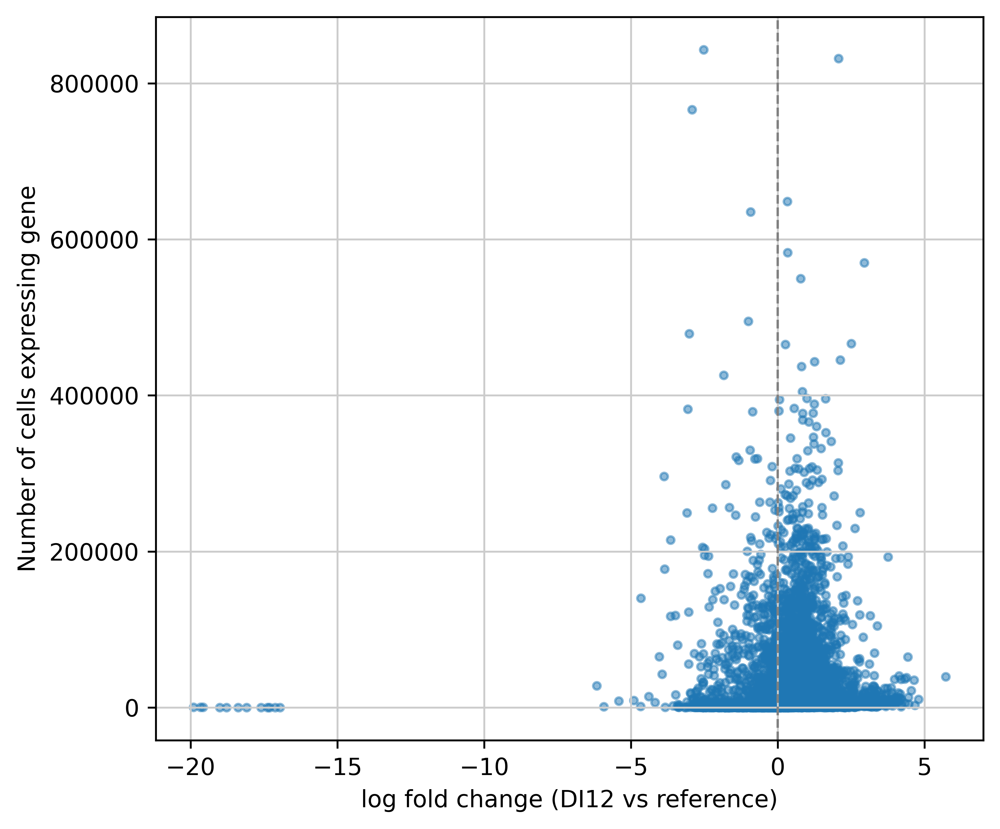

In [56]:
uns_key = "rank_genes_groups_case1_global_pre_post_cell_counts"

# 1) Figure out what groups exist in that DE result (so you pick the right one)
groups = list(adata.uns[uns_key]["names"].dtype.names)
print("Available groups:", groups)

# pick one (edit as needed)
group = groups[0]   # e.g. "pre" or "post"

# 2) Load DE table from that uns key
de = sc.get.rank_genes_groups_df(adata, group=group, key=uns_key)
# expected cols include: names, logfoldchanges, pvals, pvals_adj, scores (depends on how you ran it)

# 3) Compute #cells expressing each gene (expression > 0)
expr = adata.X > 0
n_cells_expressing = np.asarray(expr.sum(axis=0)).ravel()

cell_counts = pd.Series(n_cells_expressing, index=adata.var_names, name="n_cells_expressing")
de["n_cells_expressing"] = de["names"].map(cell_counts)

# 4) Plot: logFC vs number of expressing cells
plt.figure(figsize=(6, 5))
plt.scatter(de["logfoldchanges"], de["n_cells_expressing"], s=10, alpha=0.5)
plt.axvline(0, color="grey", linestyle="--", linewidth=1)

plt.xlabel(f"log fold change ({group} vs reference)")
plt.ylabel("Number of cells expressing gene")
plt.tight_layout()
plt.show()

In [57]:
n_cells = 100000
de[de['n_cells_expressing'] > n_cells][:50]

,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,n_cells_expressing
0,MYH9,160.084213,2.944067,0.0,0.0,0.726717,569838
1,CXCR4,132.442032,3.754869,0.0,0.0,0.418938,192965
2,NR4A1,117.614861,2.496380,0.0,0.0,0.569211,466469
3,THBS1,112.347115,2.797747,0.0,0.0,0.417419,249930
4,PLEC,109.240433,2.128896,0.0,0.0,0.544008,445552
5,EEF1G,107.036507,2.071732,0.0,0.0,0.806999,831716
6,TUBB,105.404610,2.625622,0.0,0.0,0.386368,229735
7,SEPTIN9,95.903107,2.058684,0.0,0.0,0.434214,313740
8,SMAP2,93.913750,3.387367,0.0,0.0,0.291060,104666
9,YWHAZ,93.393776,2.048456,0.0,0.0,0.416611,303631


## 2.3 Tokenize Data & Retrieve Embeddings

In [10]:
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

In [11]:
# Check that indices are unique
assert len(np.unique(list(adata.obs_names))) == len(adata)

In [12]:
# Overwrite cell IDs with unique indices
adata.obs['cell_id'] = adata.obs_names

In [13]:
# Make sure raw counts are stored in adata.X
adata.X = adata.layers['counts'].copy()

In [ ]:
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=batch_key,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    gene_perturb_df=None,               
    nproc=4,
    processing_mode='parallel',
    save_dataset_path=f"{tokenized_data_directory_path}/nemokidneyxeniumatlas",
    num_shards=32,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    use_generator=True,
    add_neigh_cell_ids=True,
    min_cells_per_gene=0,
    ignore_spc_tokens=True)

Start processing sample: CV9-KID-0-FT-5-S4...
Harmonizing sample CV9-KID-0-FT-5-S4...
STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from gene_mapping_dict with file path `/lustre/scratch126/cellgen/lotfollahi/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl`...


/nfs/team361/sb75/nichejepa/src/app/infer.py:771: ImplicitModificationWarning: Trying to modify index of attribute `.var` of view, initializing view as actual.
  adata.var.index = adata_gene_names


Number of genes with matching ensembl IDs: 4949.
Number of genes skipped due to non-matching ensembl IDs: 0.
Filtering genes that have not occurred enough during pretraining...
Number of genes skipped due to not enough pretraining occurrences: 0.
STEP 3: BASIC QUALITY CONTROL...
Filtering cells with less than 10 genes.
Filtering genes expressed in less than 0 cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11012026_190057_836/token_dictionary.pkl.


STEP 4: ADDING SPECIAL VALUES...
Harmonized sample CV9-KID-0-FT-5-S4.
Tokenizing sample CV9-KID-0-FT-5-S4...
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:663: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


... (62 outputs left out)

STEP 4: ADDING SPECIAL VALUES...
Harmonized sample CV5-KID-0-FT-5.
Tokenizing sample CV5-KID-0-FT-5...
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:663: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Ranking gene tokens based on normalized counts.
Retrieving tokens for neighborhood cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:nichejepa.tokenizers.cell_tokenizers:Using generator for dataset creation.


In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

## 2.4 Perform Perturbations

In [79]:
# Load AnnData with embeddings from model
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

In [80]:
# Load tokenized data
dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas")

In [81]:
# Filter dataset for perturbation (only keep pre-treatment cells)
pre_treatment_cell_ids = adata[adata.obs['Data_source'] == 'DIAMOND'].obs['cell_id']
pre_treatment_cell_ids_set = set(pre_treatment_cell_ids)
pretreatment_dataset = dataset.filter(
    lambda x: x["cell_id"] in pre_treatment_cell_ids_set
)
pretreatment_dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens'],
    num_rows: 1081189
})

In [82]:
pretreatment_adata = adata[adata.obs_names.isin(pre_treatment_cell_ids)]
pretreatment_adata

View of AnnData object with n_obs × n_vars = 1081189 × 4949
    obs: 'cell_id', 'Study_slice_id', 'NEMO_K_SLICE_ID', 'NEMO_K_PATIENT_ID', 'Corpus_ID', 'Study_patient_id', 'Data_source', 'Platform', 'Tissue_subregion', 'Status', 'Diagnosis', 'Type', 'Age', 'Age_grouping', 'Sex', 'eGFR', 'eGFR_group', 'BMI', 'Obesity_status', 'eGFR baseline', 'eGFR change', 'RCC_Treatment', 'batch', 'NEMO_cell_label', 'NEMO_neighborhood_label', 'tech', 'scANVI_pred', 'scANVI_confidence', 'slice', 'NEMO_neighborhood_annotation', 'leiden', 'highlight_neigh', 'DI12_vs_CV', 'DI10_vs_CV'
    var: 'ensembl_id'
    uns: 'DE_case1_pre_post_cell_counts_summary_by_niche', 'DE_case1_pre_post_neighborhood_counts_summary_by_niche', 'DE_case2_pre_post_cell_counts_summary_by_niche', 'DE_case2_pre_post_neighborhood_counts_summary_by_niche', 'Data_source_colors', 'NEMO_K_PATIENT_ID_colors', 'NEMO_cell_label_colors', 'NEMO_neighborhood_annotation_colors', 'NEMO_neighborhood_label_colors', 'Obesity_status_colors', 'Sex_col

### 2.4.1 Perturbation Case 1

Knockout Perturbation:
- Cell & Neighborhood
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI12-KID-0-FT-4

In [30]:
# Retrieve gene ensembl IDs
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDCD1'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'CTLA4'])

            ensembl_id
PDCD1  ENSG00000188389
            ensembl_id
CTLA4  ENSG00000163599


In [31]:
# Define perturbation
perturbed_cell_id = ['all', 'all', 'all', 'all']
perturbed_ensembl_id = ['ENSG00000163599', 'ENSG00000163599', 'ENSG00000188389', 'ENSG00000188389'] # ['all'] * len(perturbed_cell_id)
perturbation_target = ['cell', 'neighborhood', 'cell', 'neighborhood'] # ['neighborhood'] * len(perturbed_cell_id)
perturbation_type = ['knockout', 'knockout', 'knockout', 'knockout'] # ['knockout'] * len(perturbed_cell_id)
foldchange = [np.nan, np.nan, np.nan, np.nan] # [np.nan] * len(perturbed_cell_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

,perturbed_cell_id,perturbed_ensembl_id,perturbation_target,perturbation_type,foldchange
0,all,ENSG00000163599,cell,knockout,NaN
1,all,ENSG00000163599,neighborhood,knockout,NaN
2,all,ENSG00000188389,cell,knockout,NaN
3,all,ENSG00000188389,neighborhood,knockout,NaN


In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [26]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(pretreatment_dataset)} cells are impacted by perturbation {idx}.")

2493/1081189 cells are impacted by perturbation 0.
22237/1081189 cells are impacted by perturbation 1.
1009/1081189 cells are impacted by perturbation 2.
9796/1081189 cells are impacted by perturbation 3.


In [33]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

2875/1081189 express CTLA4 for perturbation 0.
27863/1081189 express CTLA4 for perturbation 1.
1222/1081189 express PDCD1 for perturbation 2.
12798/1081189 express PDCD1 for perturbation 3.


In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case1")

In [32]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case1")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case1'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case1"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.2 Perturbation Case 2

Knockout Perturbation:
- Cell & Neighborhood
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)
    - KDR (ENSG00000128052)
    - FLT4 (ENSG00000037280)
    - PDGFRA (ENSG00000134853)
    - PDGFRB (ENSG00000113721)
    - KIT (ENSG00000157404)
    - CSF3R (ENSG00000119535)
    - FLT3 (ENSG00000122025)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [ ]:
# Retrieve gene ensembl IDs
print(pretreatment_adata.var[pretreatment_adata.var_names == 'CTLA4'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDCD1'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'KDR'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'FLT4'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDGFRA'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDGFRB'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'KIT'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'CSF3R'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'FLT3'])

In [20]:
# Define perturbation
perturbed_cell_id = ['all'] * 18
perturbed_ensembl_id = [
    'ENSG00000163599',
    'ENSG00000163599',
    'ENSG00000188389',
    'ENSG00000188389',
    'ENSG00000128052',
    'ENSG00000128052',
    'ENSG00000037280',
    'ENSG00000037280',
    'ENSG00000134853',
    'ENSG00000134853',
    'ENSG00000113721',
    'ENSG00000113721',
    'ENSG00000157404',
    'ENSG00000157404',
    'ENSG00000119535',
    'ENSG00000119535',
    'ENSG00000122025',
    'ENSG00000122025',]
perturbation_target = ['cell', 'neighborhood'] * 9
perturbation_type = ['knockout'] * 18
foldchange = [np.nan] * 18

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

,perturbed_cell_id,perturbed_ensembl_id,perturbation_target,perturbation_type,foldchange
0,all,ENSG00000163599,cell,knockout,NaN
1,all,ENSG00000163599,neighborhood,knockout,NaN
2,all,ENSG00000188389,cell,knockout,NaN
3,all,ENSG00000188389,neighborhood,knockout,NaN
4,all,ENSG00000128052,cell,knockout,NaN
5,all,ENSG00000128052,neighborhood,knockout,NaN
6,all,ENSG00000037280,cell,knockout,NaN
7,all,ENSG00000037280,neighborhood,knockout,NaN
8,all,ENSG00000134853,cell,knockout,NaN
9,all,ENSG00000134853,neighborhood,knockout,NaN


In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(pretreatment_dataset)} cells are impacted by perturbation {idx}.")

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case2")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case2")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case2'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case2"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.3 Perturbation Case 3

- Cell & Neighborhood
    - KDR (ENSG00000128052)
    - FLT4 (ENSG00000037280)
    - PDGFRA (ENSG00000134853)
    - PDGFRB (ENSG00000113721)
    - KIT (ENSG00000157404)
    - CSF3R (ENSG00000119535)
    - FLT3 (ENSG00000122025)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [ ]:
# Retrieve gene ensembl IDs
print(pretreatment_adata.var[pretreatment_adata.var_names == 'KDR'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'FLT4'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDGFRA'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDGFRB'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'KIT'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'CSF3R'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'FLT3'])

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * 14
perturbed_ensembl_id = [
    'ENSG00000128052',
    'ENSG00000128052',
    'ENSG00000037280',
    'ENSG00000037280',
    'ENSG00000134853',
    'ENSG00000134853',
    'ENSG00000113721',
    'ENSG00000113721',
    'ENSG00000157404',
    'ENSG00000157404',
    'ENSG00000119535',
    'ENSG00000119535',
    'ENSG00000122025',
    'ENSG00000122025',]
perturbation_target = ['cell', 'neighborhood'] * 7
perturbation_type = ['knockout'] * 14
foldchange = [np.nan] * 14

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(pretreatment_dataset)} cells are impacted by perturbation {idx}.")

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case3")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case3")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case3'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case3"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.4 Perturbation Case 4 (Highly & Differentially Expressed Genes)

In [75]:
de['names'][:10]

0       MYH9
1      CXCR4
2      NR4A1
3      THBS1
4       PLEC
5      EEF1G
6       TUBB
7    SEPTIN9
8      SMAP2
9      YWHAZ
Name: names, dtype: object

In [76]:
# Retrieve gene ensembl IDs
for gene in de['names'][:10].tolist():
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])

           ensembl_id
MYH9  ENSG00000100345
            ensembl_id
CXCR4  ENSG00000121966
            ensembl_id
NR4A1  ENSG00000123358
            ensembl_id
THBS1  ENSG00000137801
           ensembl_id
PLEC  ENSG00000178209
            ensembl_id
EEF1G  ENSG00000254772
           ensembl_id
TUBB  ENSG00000196230
              ensembl_id
SEPTIN9  ENSG00000184640
            ensembl_id
SMAP2  ENSG00000084070
            ensembl_id
YWHAZ  ENSG00000164924


Knockout Perturbation:
- Cell & Neighborhood
    - Highly Differential Genes from Pert 1 Case
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [77]:
# Define perturbation
perturbed_cell_id = ['all'] * 20
perturbed_ensembl_id = [
    'ENSG00000100345',
    'ENSG00000100345',
    'ENSG00000121966',
    'ENSG00000121966',
    'ENSG00000123358',
    'ENSG00000123358',
    'ENSG00000137801',
    'ENSG00000137801',
    'ENSG00000178209',
    'ENSG00000178209',
    'ENSG00000254772',
    'ENSG00000254772',
    'ENSG00000196230',
    'ENSG00000196230',
    'ENSG00000184640',
    'ENSG00000184640',
    'ENSG00000084070',
    'ENSG00000084070',
    'ENSG00000164924',
    'ENSG00000164924',
]
perturbation_target = ['cell', 'neighborhood'] * 10 
perturbation_type = ['knockout'] * 20 
foldchange = [np.nan] * 20

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

,perturbed_cell_id,perturbed_ensembl_id,perturbation_target,perturbation_type,foldchange
0,all,ENSG00000100345,cell,knockout,NaN
1,all,ENSG00000100345,neighborhood,knockout,NaN
2,all,ENSG00000121966,cell,knockout,NaN
3,all,ENSG00000121966,neighborhood,knockout,NaN
4,all,ENSG00000123358,cell,knockout,NaN
5,all,ENSG00000123358,neighborhood,knockout,NaN
6,all,ENSG00000137801,cell,knockout,NaN
7,all,ENSG00000137801,neighborhood,knockout,NaN
8,all,ENSG00000178209,cell,knockout,NaN
9,all,ENSG00000178209,neighborhood,knockout,NaN


In [79]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

Applying perturbations using dataframe:
   perturbed_cell_id perturbed_ensembl_id perturbation_target  \
0                all      ENSG00000100345                cell   
1                all      ENSG00000100345        neighborhood   
2                all      ENSG00000121966                cell   
3                all      ENSG00000121966        neighborhood   
4                all      ENSG00000123358                cell   
5                all      ENSG00000123358        neighborhood   
6                all      ENSG00000137801                cell   
7                all      ENSG00000137801        neighborhood   
8                all      ENSG00000178209                cell   
9                all      ENSG00000178209        neighborhood   
10               all      ENSG00000254772                cell   
11               all      ENSG00000254772        neighborhood   
12               all      ENSG00000196230                cell   
13               all      ENSG00000196230        n

Map: 2162378 examples [04:05, 4411.55 examples/s]            
Filter: 2162378 examples [01:56, 9307.59 examples/s]            


Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens', 'pert_flag_idx_0', 'pert_flag_idx_1', 'pert_flag_idx_2', 'pert_flag_idx_3', 'pert_flag_idx_4', 'pert_flag_idx_5', 'pert_flag_idx_6', 'pert_flag_idx_7', 'pert_flag_idx_8', 'pert_flag_idx_9', 'pert_flag_idx_10', 'pert_flag_idx_11', 'pert_flag_idx_12', 'pert_flag_idx_13', 'pert_flag_idx_14', 'pert_flag_idx_15', 'pert_flag_idx_16', 'pert_flag_idx_17', 'pert_flag_idx_18', 'pert_flag_idx_19'],
    num_rows: 1079667
})

In [80]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(pretreatment_dataset)} cells are impacted by perturbation {idx}.")

354963/1081189 cells are impacted by perturbation 0.
905166/1081189 cells are impacted by perturbation 1.
73940/1081189 cells are impacted by perturbation 2.
425395/1081189 cells are impacted by perturbation 3.
251367/1081189 cells are impacted by perturbation 4.
871495/1081189 cells are impacted by perturbation 5.


KeyboardInterrupt: 

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case4")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case4")

In [64]:
# Filter for quick check
#perturbed_dataset = perturbed_dataset.select(range(10000))

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case4'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case4"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.5 Perturbation Case 5 (Housekeeping Genes)

In [14]:
# ChatGPT 5.2 
# "[...] Out of this list of genes from a Xenium spatial transcriptomics dataset for healthy kidney, can you provide me 10 housekeeping genes as a list?"
print(str(adata.var.index.tolist()[:]))

['IL9R', 'DDX28', 'FASLG', 'SACS', 'PGAM5', 'COMT', 'SRSF1', 'CACNA1C', 'WASHC4', 'CD34', 'SENP1', 'JAM3', 'FLII', 'BMP7', 'DPT', 'CTCFL', 'MAPK10', 'UGT1A9', 'KLRC1', 'NRAS', 'GLUD1', 'TIGIT', 'PPFIA3', 'SPON2', 'ALYREF', 'CCN4', 'ABCB6', 'IL1R1', 'TFAP2B', 'LIG3', 'GREM2', 'SETD4', 'CCL8', 'ZSCAN1', 'CYP2A6', 'CKAP5', 'TPH2', 'ISOC2', 'CDAN1', 'LATS1', 'DDX25', 'CAMK2D', 'BCAR1', 'ATL3', 'P4HA3', 'TAFA5', 'TBR1', 'CELSR2', 'KCNH2', 'GRIN2C', 'IL1RL2', 'TEFM', 'GREB1L', 'RBM15', 'ANKK1', 'CNIH4', 'UHRF1', 'ATOH1', 'SHLD1', 'PAX5', 'CRYGC', 'CRK', 'EMC4', 'CAMK1', 'NR4A3', 'PPP1R16B', 'MYCL', 'PROX1', 'PCDHA2', 'PRPS2', 'ZBTB3', 'NGF', 'NUSAP1', 'KLF17', 'HOXD9', 'PRNP', 'CBLN3', 'SEPTIN6', 'SLC6A3', 'TRPM6', 'CCDC57', 'CTSK', 'FOXB1', 'HSPA4', 'TCF21', 'GLCCI1', 'PIMREG', 'ITIH1', 'PRDM15', 'PBLD', 'BAAT', 'CGB3', 'DDX3Y', 'EMC1', 'VPS35', 'FLI1', 'WDHD1', 'NTN4', 'MPPED2', 'PTGFRN', 'GIPC1', 'NOP2', 'TNFRSF6B', 'NKRF', 'CDA', 'PRRT2', 'CST4', 'KCNQ4', 'PRODH', 'MRFAP1L1', 'PKD2L1', '

In [15]:
housekeeping_genes = [
    "HPRT1",
    "PGK1",
    "TBP",
    "NONO",
    "UBE2I",
    "YWHAZ",
    "SOD1",
    "GUSB",
    "RAN",
    "ATP5F1A",
]

In [16]:
# Retrieve gene ensembl IDs
for gene in housekeeping_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])

            ensembl_id
HPRT1  ENSG00000165704
           ensembl_id
PGK1  ENSG00000102144
          ensembl_id
TBP  ENSG00000112592
           ensembl_id
NONO  ENSG00000147140
            ensembl_id
UBE2I  ENSG00000103275
            ensembl_id
YWHAZ  ENSG00000164924
           ensembl_id
SOD1  ENSG00000142168
           ensembl_id
GUSB  ENSG00000169919
          ensembl_id
RAN  ENSG00000132341
              ensembl_id
ATP5F1A  ENSG00000152234


In [17]:
# Define perturbation
perturbed_cell_id = ['all'] * 20
perturbed_ensembl_id = [
    'ENSG00000165704',
    'ENSG00000165704',
    'ENSG00000102144',
    'ENSG00000102144',
    'ENSG00000112592',
    'ENSG00000112592',
    'ENSG00000147140',
    'ENSG00000147140',
    'ENSG00000103275',
    'ENSG00000103275',
    'ENSG00000164924',
    'ENSG00000164924',
    'ENSG00000142168',
    'ENSG00000142168',
    'ENSG00000169919',
    'ENSG00000169919',
    'ENSG00000132341',
    'ENSG00000132341',
    'ENSG00000152234',
    'ENSG00000152234',
]
perturbation_target = ['cell', 'neighborhood'] * 10 
perturbation_type = ['knockout'] * 20 
foldchange = [np.nan] * 20

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

,perturbed_cell_id,perturbed_ensembl_id,perturbation_target,perturbation_type,foldchange
0,all,ENSG00000165704,cell,knockout,NaN
1,all,ENSG00000165704,neighborhood,knockout,NaN
2,all,ENSG00000102144,cell,knockout,NaN
3,all,ENSG00000102144,neighborhood,knockout,NaN
4,all,ENSG00000112592,cell,knockout,NaN
5,all,ENSG00000112592,neighborhood,knockout,NaN
6,all,ENSG00000147140,cell,knockout,NaN
7,all,ENSG00000147140,neighborhood,knockout,NaN
8,all,ENSG00000103275,cell,knockout,NaN
9,all,ENSG00000103275,neighborhood,knockout,NaN


In [18]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

Applying perturbations using dataframe:
   perturbed_cell_id perturbed_ensembl_id perturbation_target  \
0                all      ENSG00000165704                cell   
1                all      ENSG00000165704        neighborhood   
2                all      ENSG00000102144                cell   
3                all      ENSG00000102144        neighborhood   
4                all      ENSG00000112592                cell   
5                all      ENSG00000112592        neighborhood   
6                all      ENSG00000147140                cell   
7                all      ENSG00000147140        neighborhood   
8                all      ENSG00000103275                cell   
9                all      ENSG00000103275        neighborhood   
10               all      ENSG00000164924                cell   
11               all      ENSG00000164924        neighborhood   
12               all      ENSG00000142168                cell   
13               all      ENSG00000142168        n

Map: 2162378 examples [04:23, 4104.15 examples/s]                                          
Filter: 2162378 examples [02:50, 6333.10 examples/s]                                       


Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens', 'pert_flag_idx_0', 'pert_flag_idx_1', 'pert_flag_idx_2', 'pert_flag_idx_3', 'pert_flag_idx_4', 'pert_flag_idx_5', 'pert_flag_idx_6', 'pert_flag_idx_7', 'pert_flag_idx_8', 'pert_flag_idx_9', 'pert_flag_idx_10', 'pert_flag_idx_11', 'pert_flag_idx_12', 'pert_flag_idx_13', 'pert_flag_idx_14', 'pert_flag_idx_15', 'pert_flag_idx_16', 'pert_flag_idx_17', 'pert_flag_idx_18', 'pert_flag_idx_19'],
    num_rows: 1071987
})

In [20]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(pretreatment_dataset)} cells are impacted by perturbation {idx}.")

6793/1081189 cells are impacted by perturbation 0.
65760/1081189 cells are impacted by perturbation 1.
141938/1081189 cells are impacted by perturbation 2.
728955/1081189 cells are impacted by perturbation 3.
9467/1081189 cells are impacted by perturbation 4.
90759/1081189 cells are impacted by perturbation 5.
123588/1081189 cells are impacted by perturbation 6.
643477/1081189 cells are impacted by perturbation 7.
60527/1081189 cells are impacted by perturbation 8.
378352/1081189 cells are impacted by perturbation 9.
158941/1081189 cells are impacted by perturbation 10.
733458/1081189 cells are impacted by perturbation 11.
189136/1081189 cells are impacted by perturbation 12.


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x1485404908b0>>
Traceback (most recent call last):
  File "/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


KeyboardInterrupt: 

In [21]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

7646/1081189 express HPRT1 for perturbation 0.
75733/1081189 express HPRT1 for perturbation 1.
166809/1081189 express PGK1 for perturbation 2.
761545/1081189 express PGK1 for perturbation 3.
13240/1081189 express TBP for perturbation 4.


KeyboardInterrupt: 

In [22]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case5")

Saving the dataset (98/98 shards): 100%|█| 1071987/1071987 [03:17<00:00, 5433.96 examples/s


In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case5")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case5'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case5"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

## 2.5 Analyze Perturbations

In [83]:
# Load AnnData with embeddings from model (including perturbation embeddings)
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

In [84]:
# Compute highly variable genes
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=500,
    flavor="seurat_v3",
    layer="counts" # important: HVGs from raw counts
)

# Subset to HVGs (optional)
# adata_hvg = adata[:, adata.var["highly_variable"]].copy()

### 2.5.1 Perturbation Case 1

Knockout Perturbation:
- Cell & Neighborhood
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI12-KID-0-FT-4

In [323]:
pert_genes = [
    'CTLA4',
    'PDCD1']

In [324]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

            ensembl_id  highly_variable  highly_variable_rank     means  \
CTLA4  ENSG00000163599             True                 359.0  0.005836   

       variances  variances_norm  
CTLA4   0.007755         1.22414  
            ensembl_id  highly_variable  highly_variable_rank     means  \
PDCD1  ENSG00000188389            False                   NaN  0.002927   

       variances  variances_norm  
PDCD1   0.003121        0.986409  


In [325]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case1")

#### 2.5.1.1 Individual Perturbations

In [326]:
pert_idx = 0 # 0.9975, 0.9998, 1.0000
# pert_idx = 1 # 0.9999, 0.9999, 0.9999
# pert_idx = 2 # 0.9988, 0.9998, 0.9999
# pert_idx = 3 # 0.9999, 0.9999, 0.9999

ind_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: x[f"pert_flag_idx_{pert_idx}"])

In [327]:
ind_pert_cell_ids = list(ind_pert_filtered_dataset['cell_id'])
print(len(ind_pert_cell_ids))

2493


In [328]:
adata_sub_ind_pert = adata[adata.obs_names.isin(ind_pert_cell_ids)]

cell_emb: mean=0.997574  min=0.955204


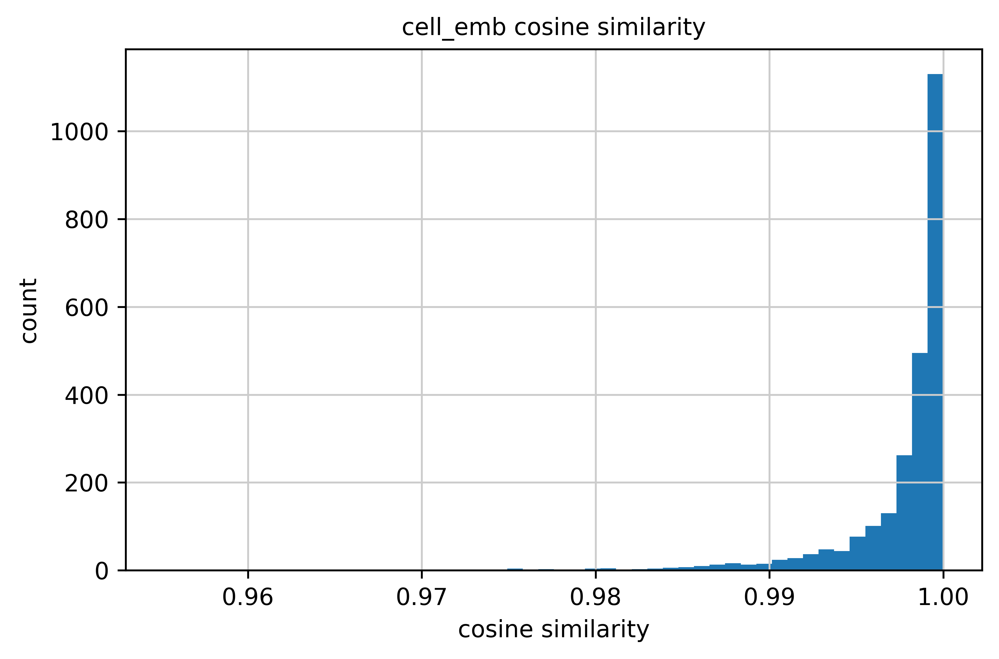

spatial_cell_emb: mean=0.999843  min=0.993725


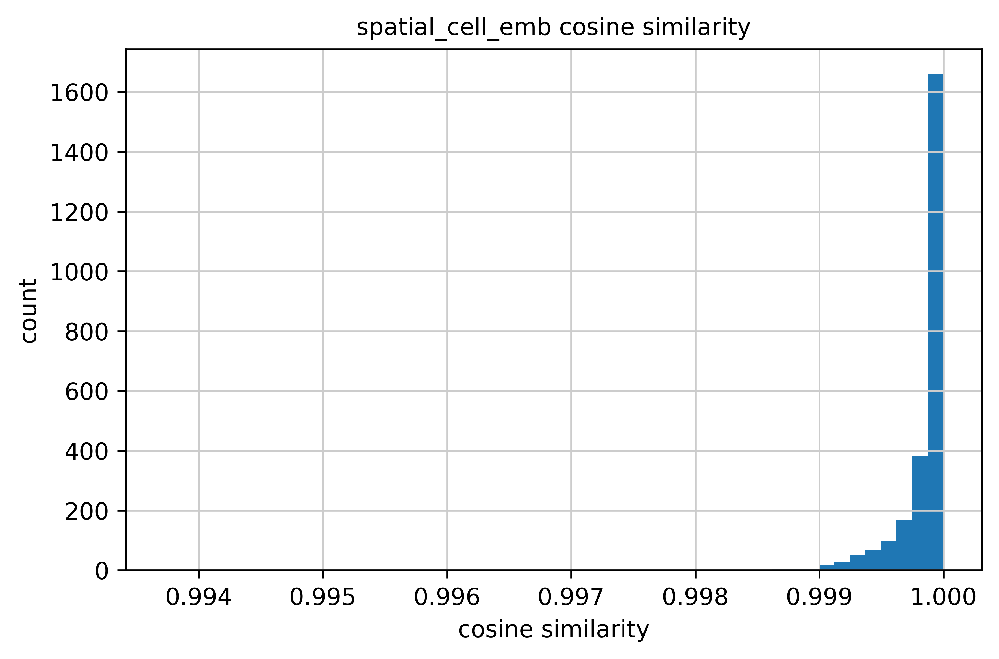

neighborhood_emb: mean=0.999968  min=0.992637


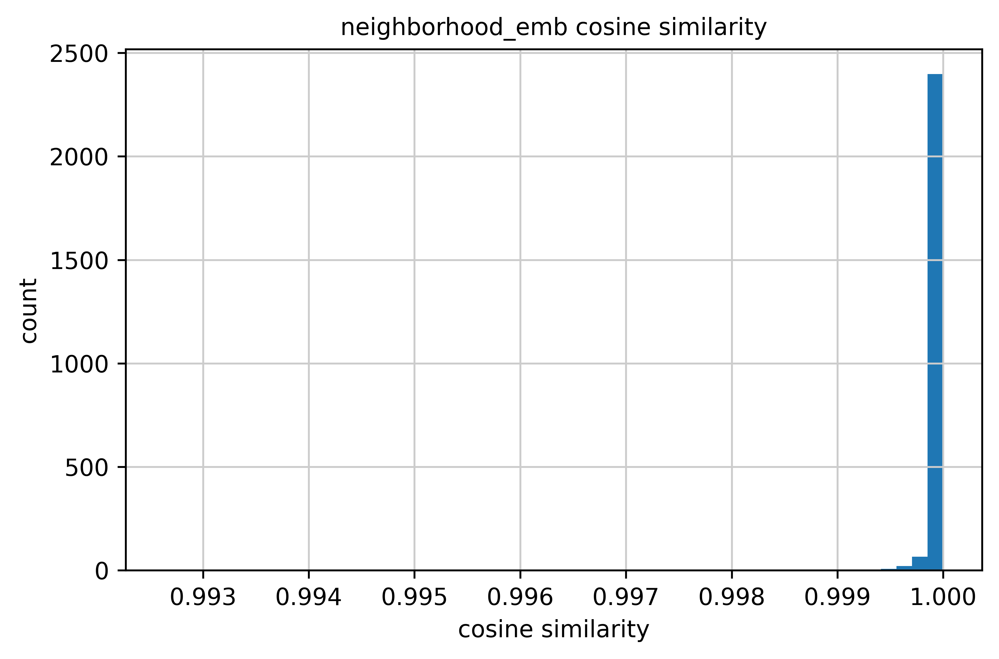

In [329]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_ind_pert,
    pairs=[("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
           ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
           ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb")]
)

In [330]:
df_cos_sim_sorted = summarize_cosine_sim_by_label(
    adata_sub_ind_pert,
    pairs=[("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
           ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
           ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Natural killer cell,1,0.985295,0.999641,0.999975
1,CD14+ monocyte,1,0.987691,0.999685,0.999990
2,Ascending thin limb,2,0.992032,0.999778,0.999993
3,Descending thin limb,10,0.992814,0.999385,0.999961
4,Memory B cell,23,0.993119,0.999547,0.999952
5,Connecting tubule,41,0.994715,0.999496,0.999967
6,Neuron,12,0.995381,0.999783,0.999978
7,Principal cell,25,0.996165,0.999782,0.999971
8,Glomerular endothelial cell,33,0.996179,0.999754,0.999968
9,Vascular mural cell,72,0.996388,0.999769,0.999981


In [331]:
df_cos_sim_sorted = summarize_cosine_sim_by_label(
    adata_sub_ind_pert,
    pairs=[("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
           ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
           ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Loop of Henle neighborhood,164,0.995999,0.999812,0.999984
1,Fibrovascular neighborhood,553,0.996411,0.999760,0.999943
2,Proximal nephron neighborhood,562,0.997833,0.999848,0.999987
3,Injured proximal nephron neighborhood,664,0.997883,0.999835,0.999948
4,Glomerular neighborhood,139,0.998376,0.999933,0.999993
5,Distal nephron neighborhood,411,0.998644,0.999946,0.999993


#### 2.5.1.2 Cell Perturbations

In [27]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [28]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

3464


In [29]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

0.9979377
0.9552039


(array([2.000e+00, 0.000e+00, 1.000e+00, 6.000e+00, 1.000e+01, 1.400e+01,
        3.300e+01, 9.200e+01, 2.600e+02, 3.046e+03]),
 array([0.95520389, 0.95968294, 0.96416199, 0.96864104, 0.97312009,
        0.97759914, 0.98207819, 0.98655725, 0.9910363 , 0.99551535,
        0.9999944 ]),
 <BarContainer object of 10 artists>)

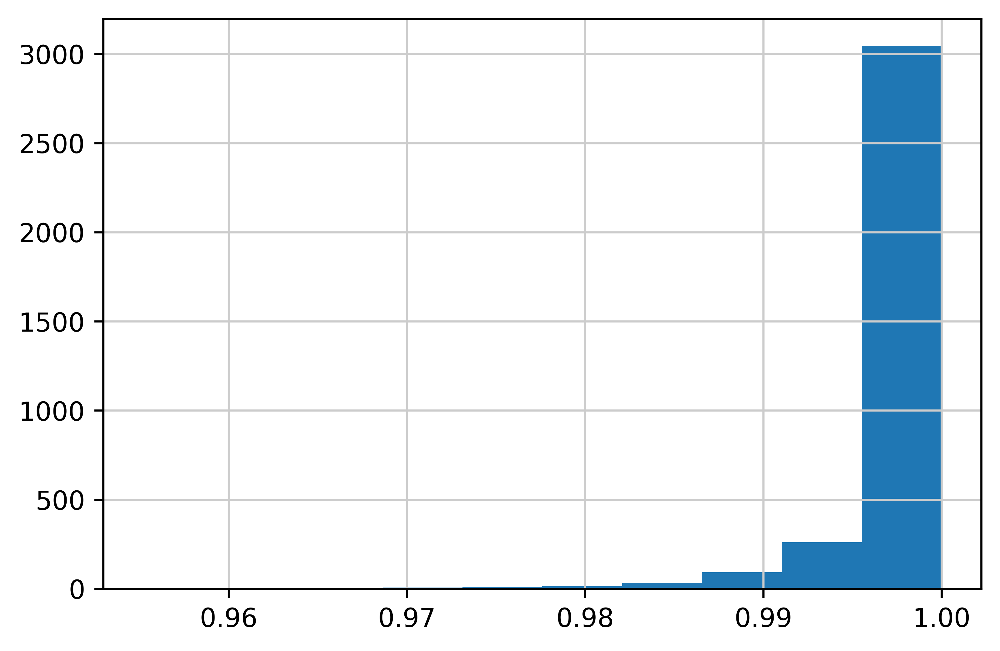

In [30]:
A = adata_sub_cell_pert.obsm['cell_emb']
B = adata_sub_cell_pert.obsm['cell_emb_perturb_case1']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(cell_emb_cos_sim))
print(np.min(cell_emb_cos_sim))
plt.hist(cell_emb_cos_sim)

0.99985445
0.99372476


(array([1.000e+00, 0.000e+00, 1.000e+00, 2.000e+00, 1.000e+00, 2.000e+00,
        2.000e+00, 8.000e+00, 1.330e+02, 3.314e+03]),
 array([0.99372476, 0.99435204, 0.99497932, 0.9956066 , 0.99623388,
        0.99686122, 0.9974885 , 0.99811578, 0.99874306, 0.99937034,
        0.99999762]),
 <BarContainer object of 10 artists>)

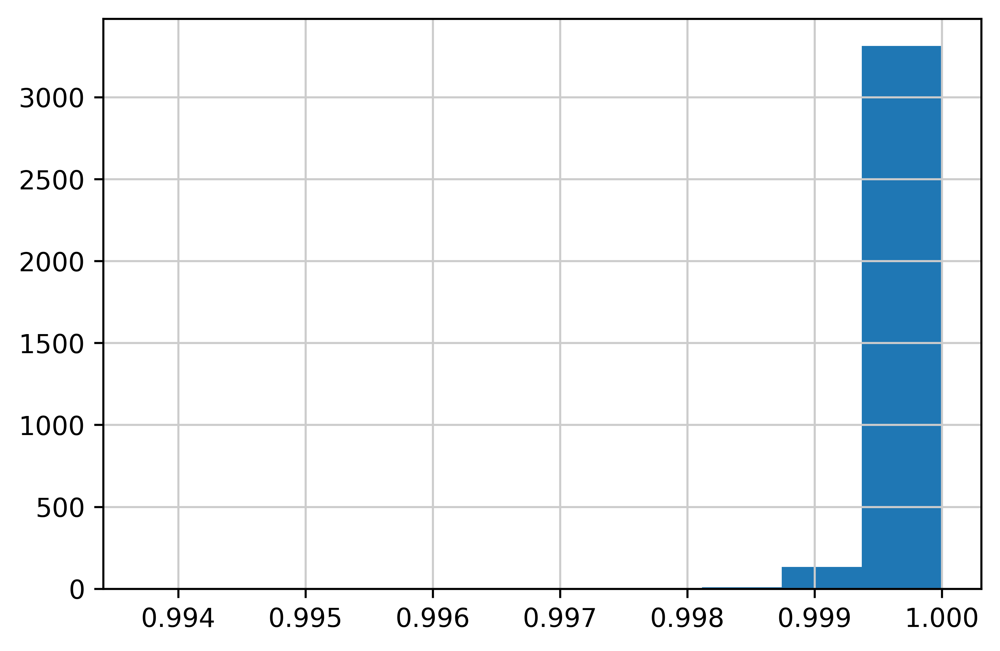

In [31]:
A = adata_sub_cell_pert.obsm['spatial_cell_emb']
B = adata_sub_cell_pert.obsm['spatial_cell_emb_perturb_case1']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

spatial_cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(spatial_cell_emb_cos_sim))
print(np.min(spatial_cell_emb_cos_sim))
plt.hist(spatial_cell_emb_cos_sim)

0.99997157
0.9926368


(array([1.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 3.462e+03]),
 array([0.9926368 , 0.9933731 , 0.99410939, 0.99484569, 0.99558198,
        0.99631834, 0.99705464, 0.99779093, 0.99852723, 0.99926353,
        0.99999982]),
 <BarContainer object of 10 artists>)

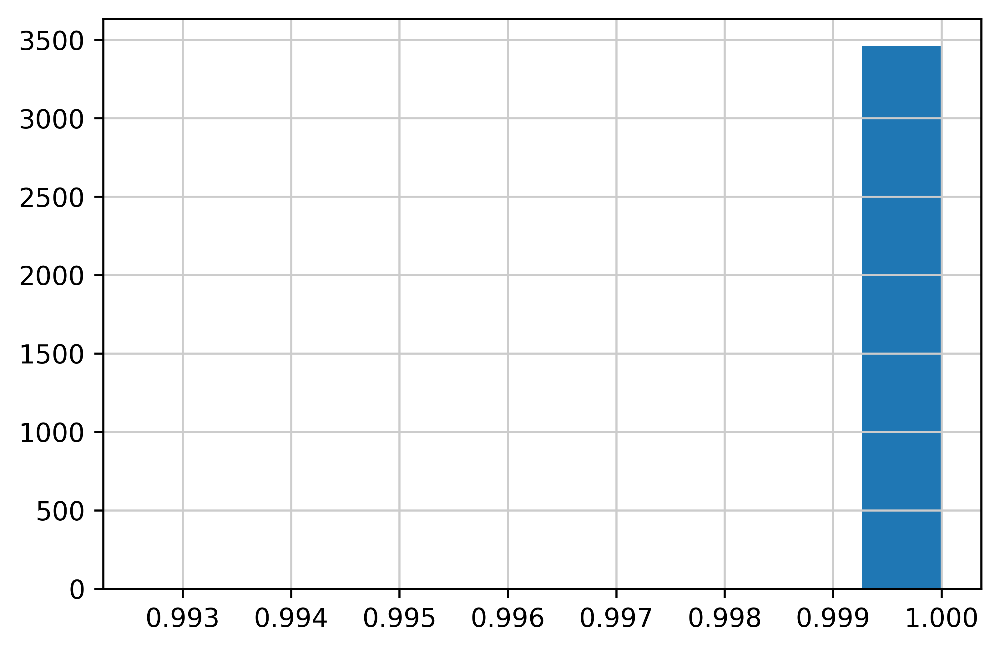

In [32]:
A = adata_sub_cell_pert.obsm['neighborhood_emb']
B = adata_sub_cell_pert.obsm['neighborhood_emb_perturb_case1']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

neighborhood_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(neighborhood_emb_cos_sim))
print(np.min(neighborhood_emb_cos_sim))
plt.hist(neighborhood_emb_cos_sim)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


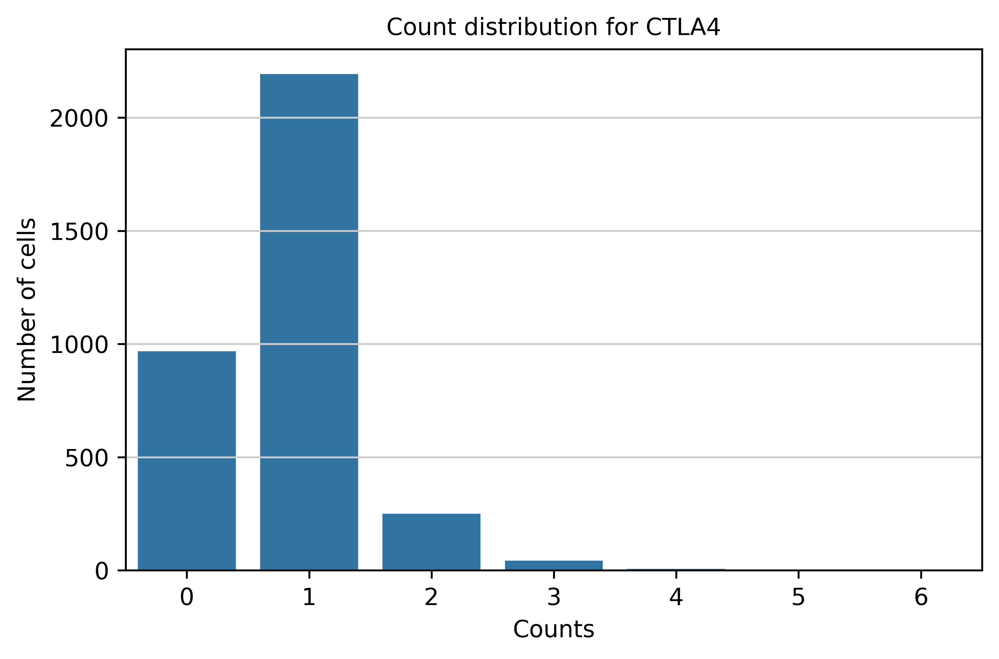

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


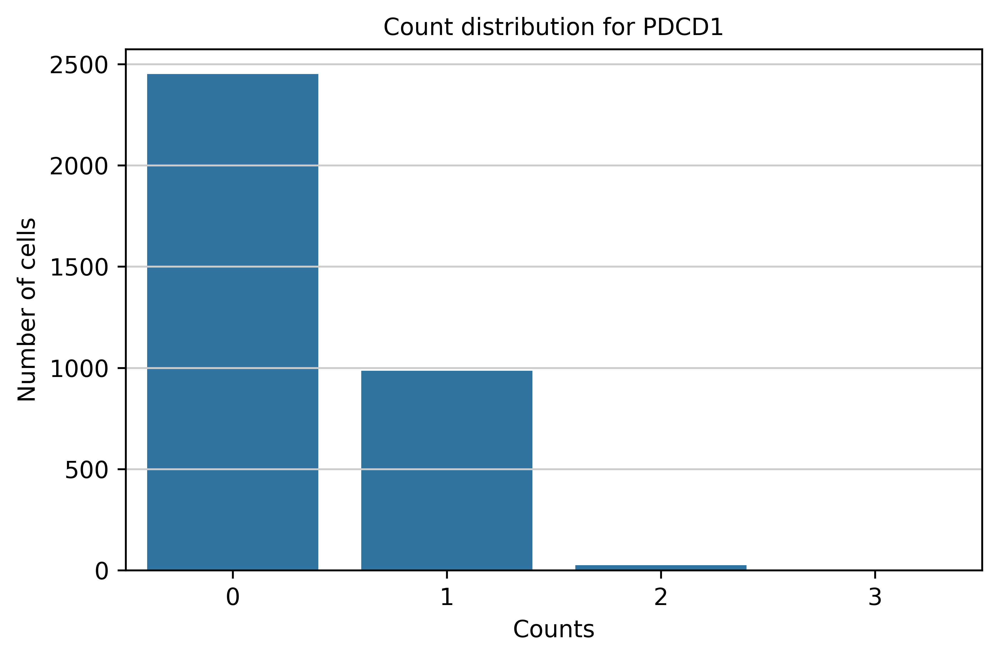

In [36]:
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].X
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


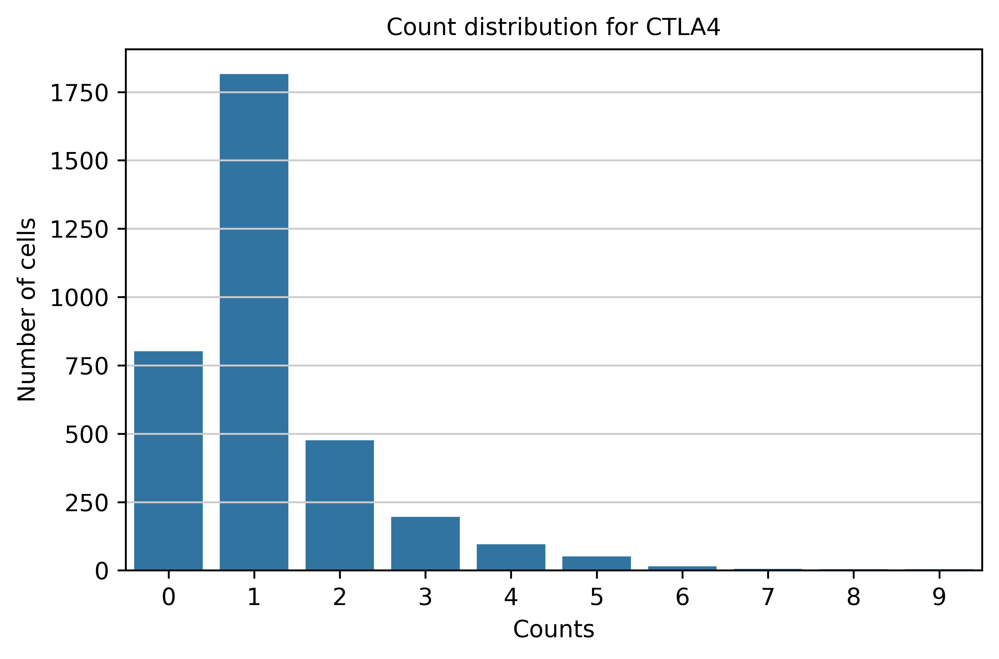

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


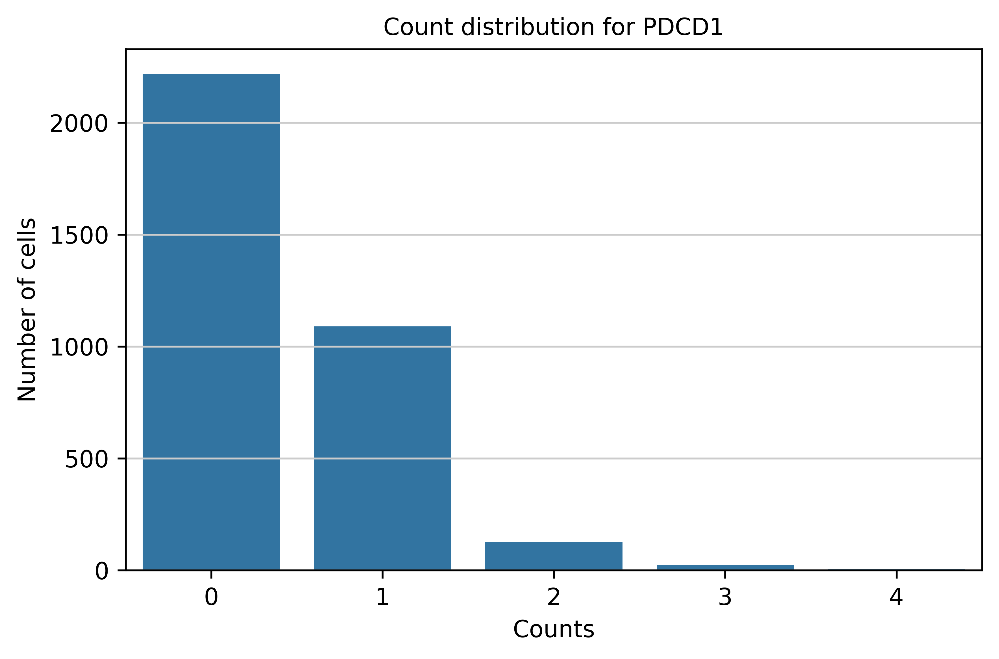

In [46]:
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].layers['counts_neighborhood']
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

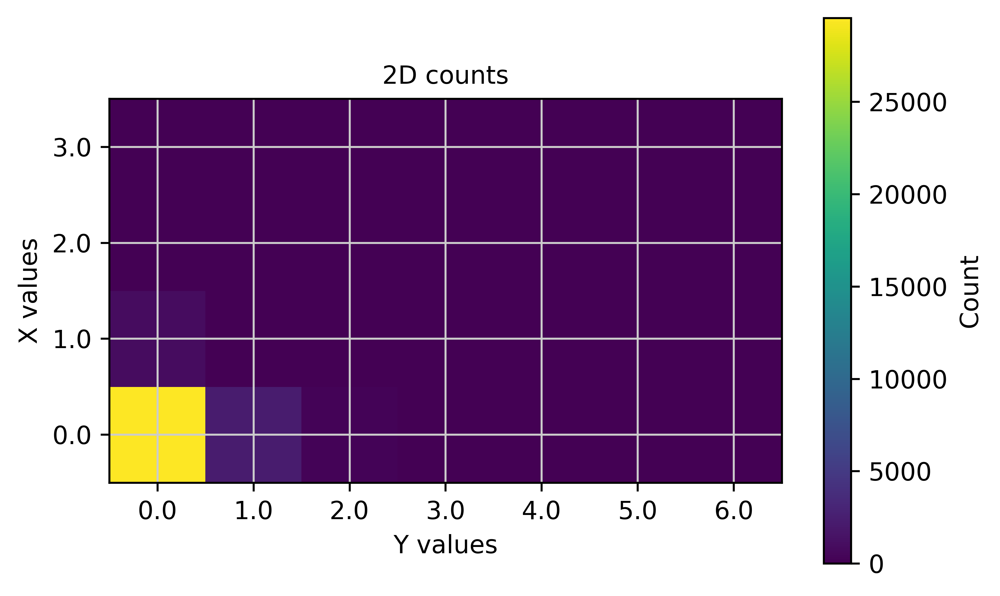

In [56]:
x = adata_sub_pert[:, adata_sub_cell_pert.var_names.isin(['PDCD1'])].layers['counts'].toarray().flatten()
y = adata_sub_pert[:, adata_sub_cell_pert.var_names.isin(['CTLA4'])].layers['counts'].toarray().flatten()

x_vals, y_vals = np.unique(x), np.unique(y)
count_matrix = np.zeros((len(x_vals), len(y_vals)), dtype=int)

for xi, yi in zip(x, y):
    count_matrix[np.where(x_vals == xi)[0][0],
                 np.where(y_vals == yi)[0][0]] += 1

plt.imshow(count_matrix, origin="lower")
plt.colorbar(label="Count")
plt.xticks(range(len(y_vals)), y_vals)
plt.yticks(range(len(x_vals)), x_vals)
plt.xlabel("Y values")
plt.ylabel("X values")
plt.title("2D counts")
plt.show()

#### 2.5.1.3 Neighborhood Perturbations

In [47]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [48]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

33093


In [49]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

0.9997841
0.9552039


(array([2.0000e+00, 0.0000e+00, 1.0000e+00, 6.0000e+00, 1.0000e+01,
        1.4000e+01, 3.3000e+01, 9.2000e+01, 2.6000e+02, 3.2675e+04]),
 array([0.95520389, 0.95968354, 0.96416318, 0.96864277, 0.97312242,
        0.97760206, 0.98208171, 0.98656136, 0.99104095, 0.99552059,
        1.00000024]),
 <BarContainer object of 10 artists>)

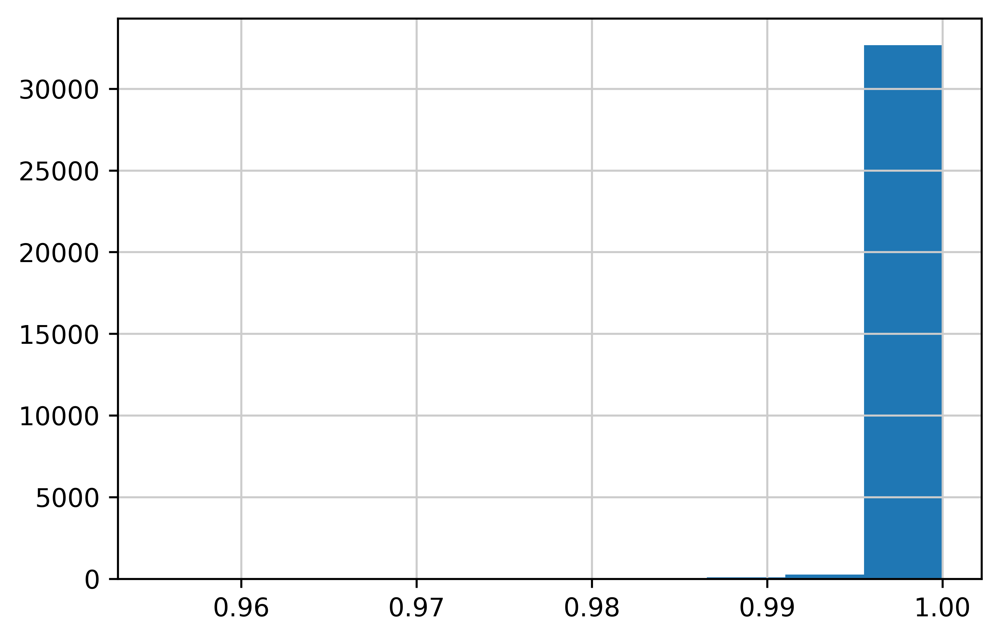

In [50]:
A = adata_sub_pert.obsm['cell_emb']
B = adata_sub_pert.obsm['cell_emb_perturb_case1']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(cell_emb_cos_sim))
print(np.min(cell_emb_cos_sim))
plt.hist(cell_emb_cos_sim)

0.9999688
0.9779211


(array([1.0000e+00, 0.0000e+00, 0.0000e+00, 2.0000e+00, 0.0000e+00,
        3.0000e+00, 1.0000e+00, 5.0000e+00, 1.3000e+01, 3.3068e+04]),
 array([0.97792113, 0.980129  , 0.98233688, 0.98454481, 0.98675269,
        0.98896056, 0.99116844, 0.99337631, 0.99558425, 0.99779212,
        1.        ]),
 <BarContainer object of 10 artists>)

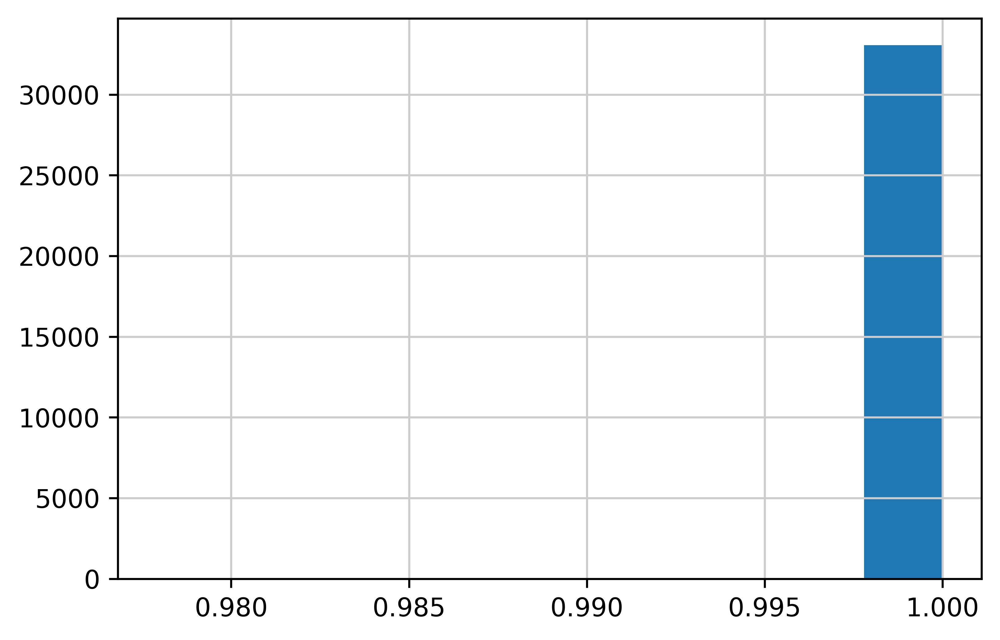

In [51]:
A = adata_sub_pert.obsm['spatial_cell_emb']
B = adata_sub_pert.obsm['spatial_cell_emb_perturb_case1']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

spatial_cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(spatial_cell_emb_cos_sim))
print(np.min(spatial_cell_emb_cos_sim))
plt.hist(spatial_cell_emb_cos_sim)

0.99997956
0.98037875


(array([1.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 2.0000e+00,
        3.0000e+00, 3.0000e+00, 3.0000e+00, 9.0000e+00, 3.3072e+04]),
 array([0.98037875, 0.98234087, 0.984303  , 0.98626512, 0.98822725,
        0.99018937, 0.9921515 , 0.99411362, 0.99607575, 0.99803787,
        1.        ]),
 <BarContainer object of 10 artists>)

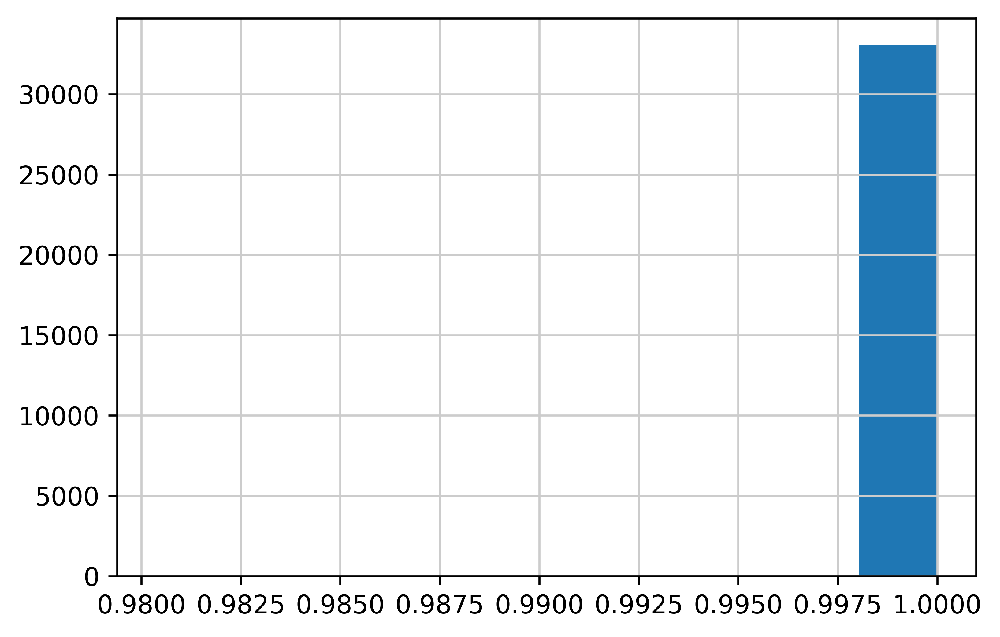

In [52]:
A = adata_sub_pert.obsm['neighborhood_emb']
B = adata_sub_pert.obsm['neighborhood_emb_perturb_case1']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

neighborhood_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(neighborhood_emb_cos_sim))
print(np.min(neighborhood_emb_cos_sim))
plt.hist(neighborhood_emb_cos_sim)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


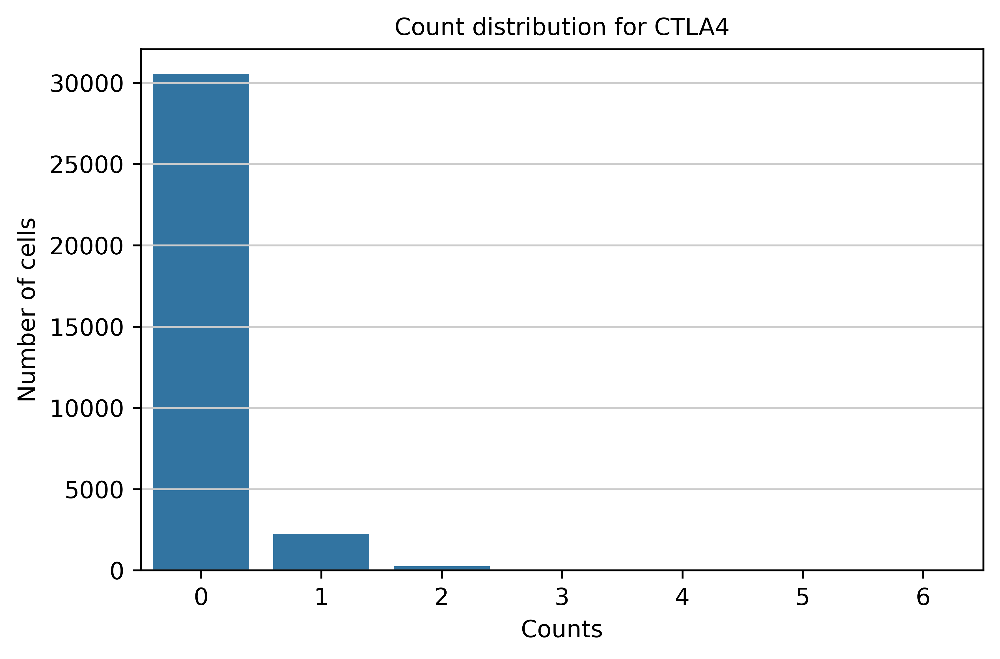

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


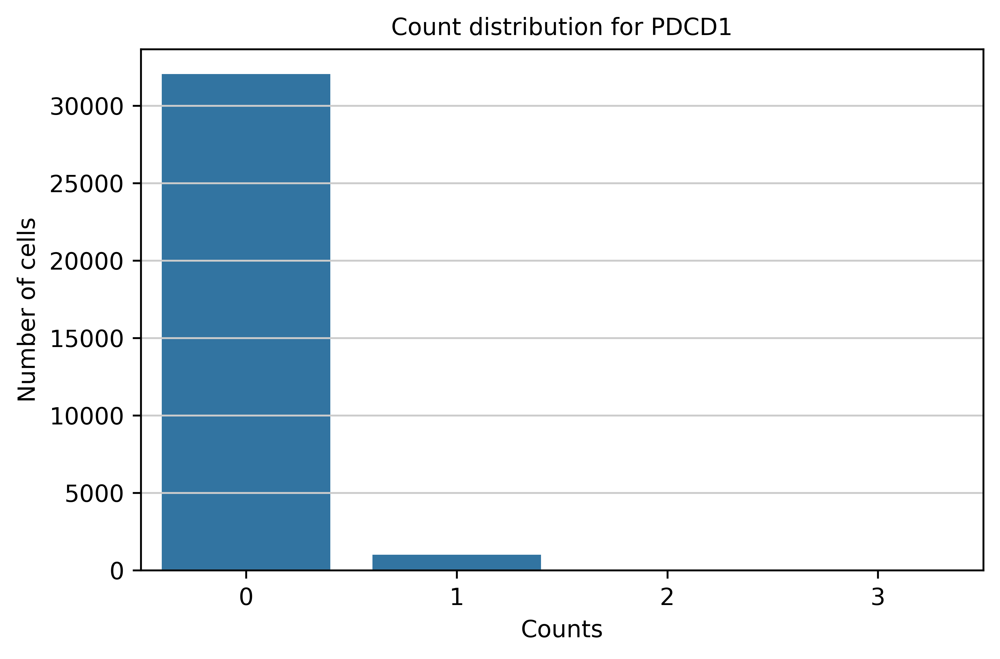

In [53]:
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_pert[:, gene].X
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


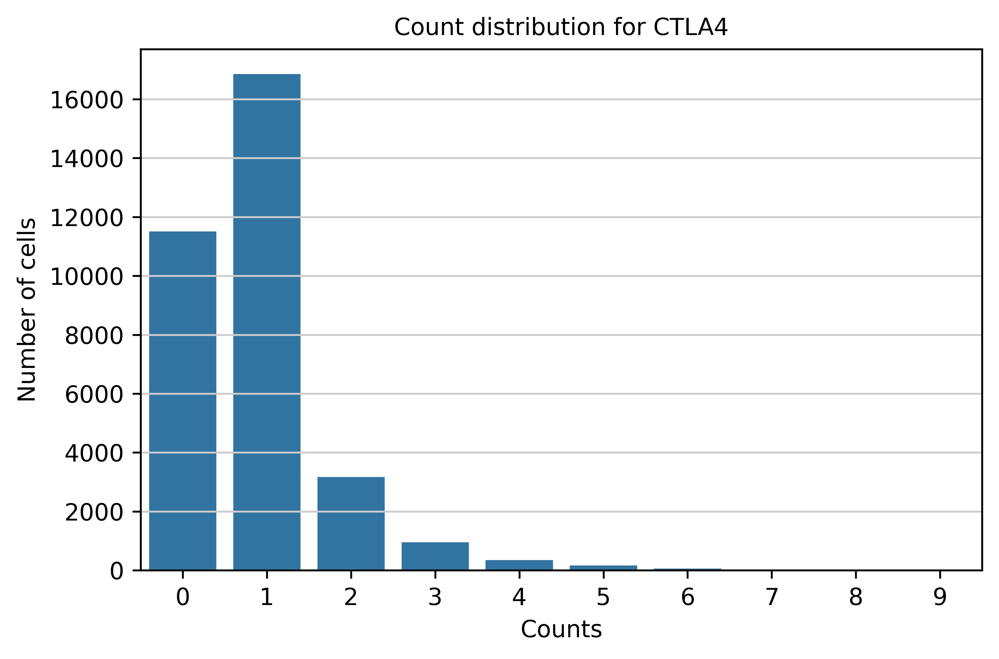

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


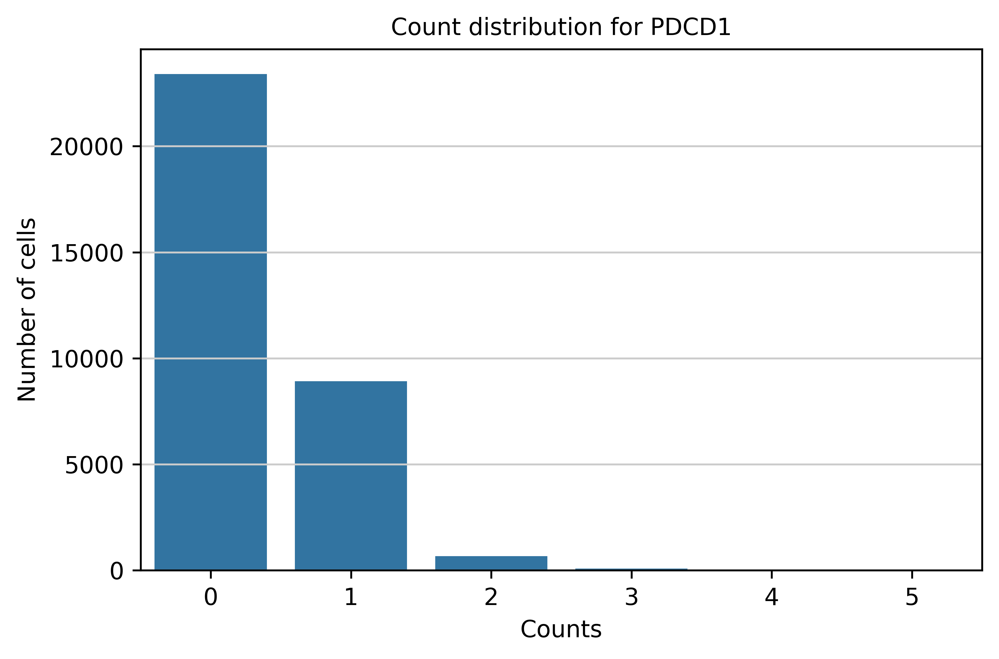

In [54]:
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_pert[:, gene].layers['counts_neighborhood']
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

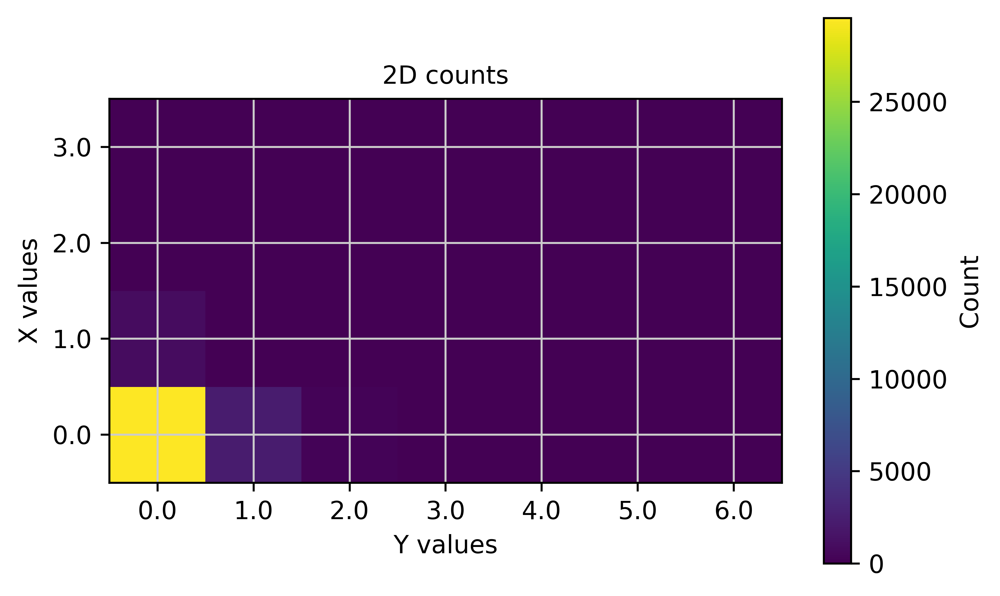

In [55]:
x = adata_sub_pert[:, adata_sub_pert.var_names.isin(['PDCD1'])].layers['counts'].toarray().flatten()
y = adata_sub_pert[:, adata_sub_pert.var_names.isin(['CTLA4'])].layers['counts'].toarray().flatten()

x_vals, y_vals = np.unique(x), np.unique(y)
count_matrix = np.zeros((len(x_vals), len(y_vals)), dtype=int)

for xi, yi in zip(x, y):
    count_matrix[np.where(x_vals == xi)[0][0],
                 np.where(y_vals == yi)[0][0]] += 1

plt.imshow(count_matrix, origin="lower")
plt.colorbar(label="Count")
plt.xticks(range(len(y_vals)), y_vals)
plt.yticks(range(len(x_vals)), x_vals)
plt.xlabel("Y values")
plt.ylabel("X values")
plt.title("2D counts")
plt.show()

### 2.5.2 Perturbation Case 2

Knockout Perturbation:
- Cell & Neighborhood
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)
    - KDR (ENSG00000128052)
    - FLT4 (ENSG00000037280)
    - PDGFRA (ENSG00000134853)
    - PDGFRB (ENSG00000113721)
    - KIT (ENSG00000157404)
    - CSF3R (ENSG00000119535)
    - FLT3 (ENSG00000122025)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [332]:
pert_genes = [
    'CTLA4',
    'PDCD1',
    'KDR',
    'FLT4',
    'PDGFRA',
    'PDGFRB',
    'KIT',
    'CSF3R',
    'FLT3']

In [333]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

            ensembl_id  highly_variable  highly_variable_rank     means  \
CTLA4  ENSG00000163599             True                 359.0  0.005836   

       variances  variances_norm  
CTLA4   0.007755         1.22414  
            ensembl_id  highly_variable  highly_variable_rank     means  \
PDCD1  ENSG00000188389            False                   NaN  0.002927   

       variances  variances_norm  
PDCD1   0.003121        0.986409  
          ensembl_id  highly_variable  highly_variable_rank     means  \
KDR  ENSG00000128052             True                 225.0  0.042929   

     variances  variances_norm  
KDR   0.070335        1.363115  
           ensembl_id  highly_variable  highly_variable_rank     means  \
FLT4  ENSG00000037280             True                 129.0  0.071771   

      variances  variances_norm  
FLT4   0.152284        1.610407  
             ensembl_id  highly_variable  highly_variable_rank     means  \
PDGFRA  ENSG00000134853             True            

In [334]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case2")

#### 2.5.2.1 Individual Perturbations

In [335]:
# pert_idx = 0 # 0.9968, 0.9994, 0.9996
# pert_idx = 1 # 0.9993, 0.9995, 0.9996
# pert_idx = 2 # 0.9981, 0.9995, 0.9997
# pert_idx = 3 # 0.9994, 0.9996, 0.9997
# pert_idx = 4 # 0.9982, 0.9996, 0.9998
# pert_idx = 5 # 0.9993, 0.9997, 0.9998
# pert_idx = 6 # 0.9987, 0.9996, 0.9998
# pert_idx = 7 # 0.9993, 0.9997, 0.9998
pert_idx = 8 # 0.9956, 0.9991, 0.9992
# pert_idx = 9 # 0.9993, 0.9994, 0.9994
# pert_idx = 10 # 0.9972, 0.9995, 0.9996
# pert_idx = 11 # 0.9993, 0.9996, 0.9997
# pert_idx = 12 # 0.9995, 0.9994, 0.9995
# pert_idx = 13 # 0.9995, 0.9994, 0.9996
# pert_idx = 14 # 0.9995, 0.9994, 0.9996
# pert_idx = 15 # 0.9982, 0.9995, 0,9996
# pert_idx = 16 # 0.9987, 0.9995, 0,9996
# pert_idx = 17 # 0.9994, 0.9996, 0,9996

ind_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: x[f"pert_flag_idx_{pert_idx}"])

In [336]:
ind_pert_cell_ids = list(ind_pert_filtered_dataset['cell_id'])
print(len(ind_pert_cell_ids))

60505


In [337]:
adata_sub_ind_pert = adata[adata.obs_names.isin(ind_pert_cell_ids)]

cell_emb: mean=0.995555  min=0.875217


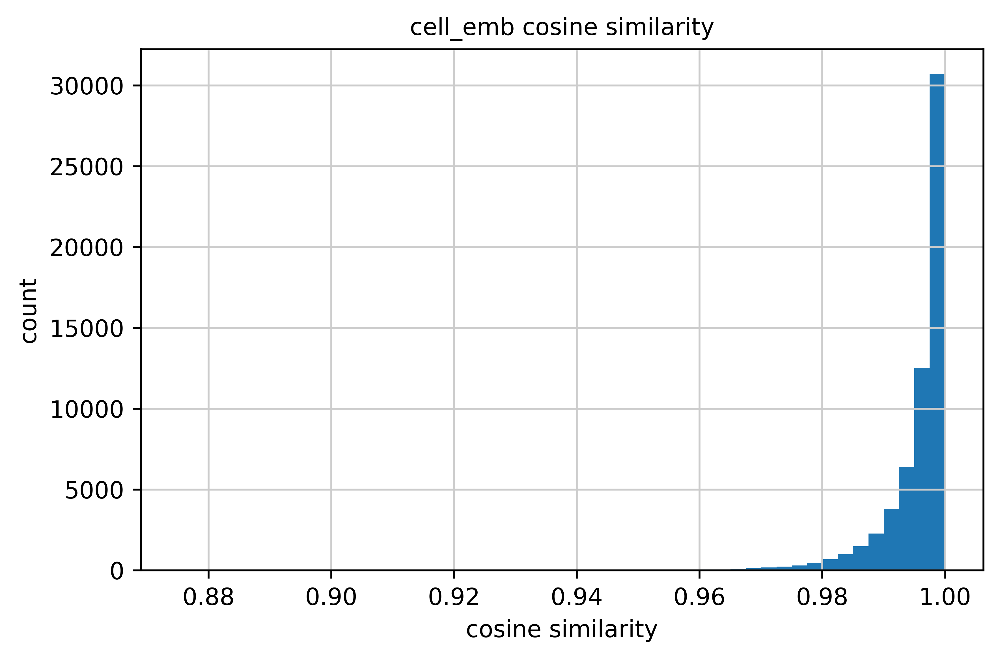

spatial_cell_emb: mean=0.999124  min=0.981702


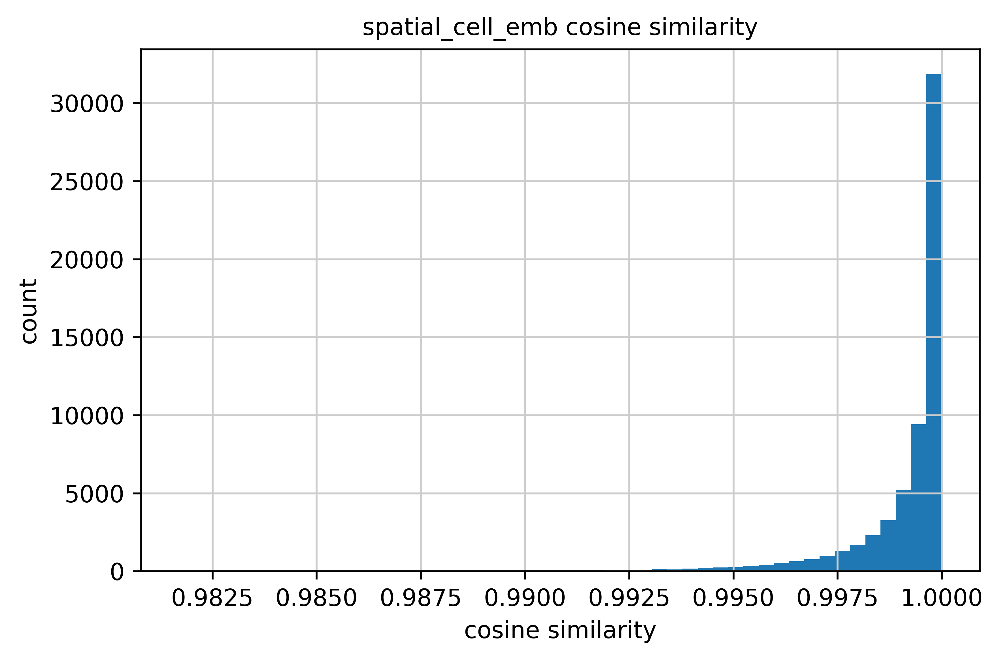

neighborhood_emb: mean=0.999241  min=0.981631


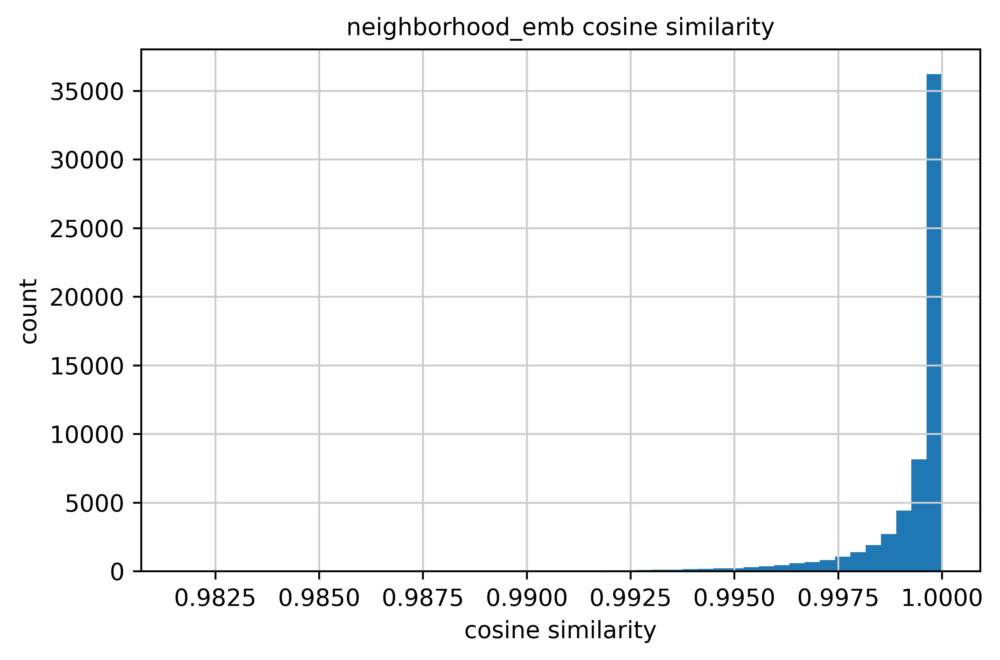

In [338]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_ind_pert,
    pairs=[("cell_emb", "cell_emb_perturb_case2", "cell_emb"),
           ("spatial_cell_emb", "spatial_cell_emb_perturb_case2", "spatial_cell_emb"),
           ("neighborhood_emb", "neighborhood_emb_perturb_case2", "neighborhood_emb")])

In [340]:
df_cos_sim_sorted = summarize_cosine_sim_by_label(
    adata_sub_ind_pert,
    pairs=[("cell_emb", "cell_emb_perturb_case2", "cell_emb"),
           ("spatial_cell_emb", "spatial_cell_emb_perturb_case2", "spatial_cell_emb"),
           ("neighborhood_emb", "neighborhood_emb_perturb_case2", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Neuron,67,0.984458,0.998165,0.998803
1,CD4+ T cell,217,0.985980,0.998167,0.998707
2,Memory B cell,38,0.987495,0.998572,0.998873
3,Descending thin limb,91,0.989232,0.998558,0.998870
4,Vascular mural cell,5672,0.991364,0.998870,0.999181
5,CD8+ T cell,604,0.991677,0.998921,0.999057
6,Neutrophil,143,0.991723,0.998901,0.999033
7,Natural killer cell,16,0.991897,0.999672,0.999731
8,Conventional dendritic cell,222,0.991927,0.998978,0.999099
9,CD16+ monocyte,2,0.992257,0.999886,0.999930


In [341]:
df_cos_sim_sorted = summarize_cosine_sim_by_label(
    adata_sub_ind_pert,
    pairs=[("cell_emb", "cell_emb_perturb_case2", "cell_emb"),
           ("spatial_cell_emb", "spatial_cell_emb_perturb_case2", "spatial_cell_emb"),
           ("neighborhood_emb", "neighborhood_emb_perturb_case2", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Loop of Henle neighborhood,4628,0.994628,0.999098,0.999242
1,Proximal nephron neighborhood,16149,0.995148,0.999497,0.999672
2,Fibrovascular neighborhood,13662,0.995162,0.998907,0.999066
3,Glomerular neighborhood,10579,0.995983,0.999760,0.999827
4,Injured proximal nephron neighborhood,2730,0.996030,0.999047,0.999185
5,Distal nephron neighborhood,12757,0.996373,0.998384,0.998407


#### 2.5.2.2 Cell Perturbations

In [60]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [61]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

199168


In [62]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

0.9973395
0.87521726


(array([1.00000e+00, 1.00000e+00, 4.00000e+00, 7.00000e+00, 1.70000e+01,
        7.30000e+01, 2.50000e+02, 1.23700e+03, 6.90000e+03, 1.90678e+05]),
 array([0.87521726, 0.88769531, 0.90017337, 0.91265142, 0.92512947,
        0.93760753, 0.95008552, 0.96256357, 0.97504163, 0.98751968,
        0.99999774]),
 <BarContainer object of 10 artists>)

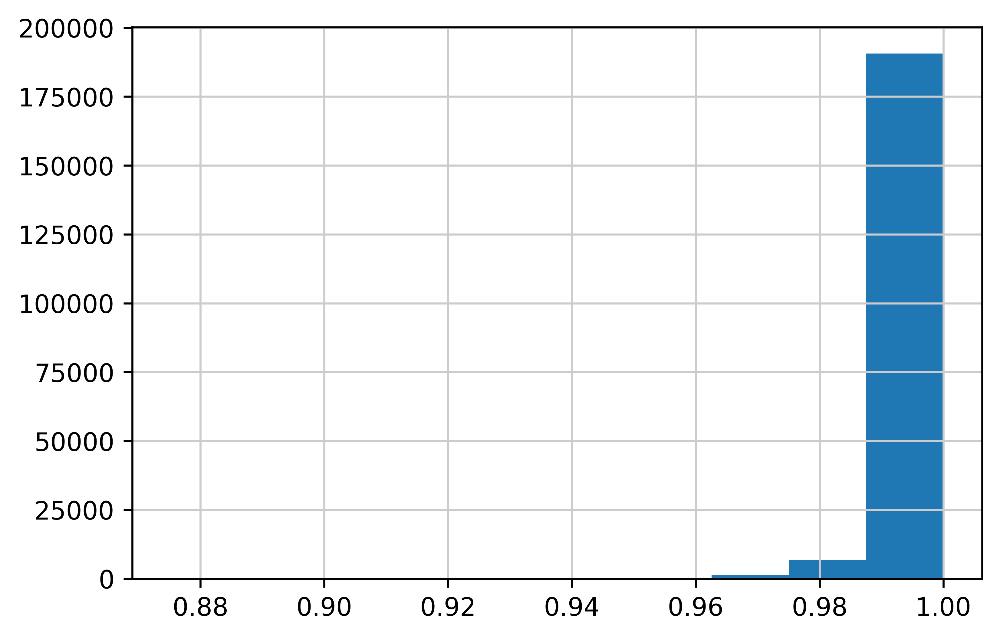

In [63]:
A = adata_sub_cell_pert.obsm['cell_emb']
B = adata_sub_cell_pert.obsm['cell_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(cell_emb_cos_sim))
print(np.min(cell_emb_cos_sim))
plt.hist(cell_emb_cos_sim)

0.99946755
0.98170245


(array([6.00000e+00, 9.00000e+00, 2.40000e+01, 6.80000e+01, 1.88000e+02,
        4.36000e+02, 1.03800e+03, 2.81100e+03, 9.09200e+03, 1.85496e+05]),
 array([0.98170245, 0.98353195, 0.9853614 , 0.9871909 , 0.98902035,
        0.99084985, 0.99267936, 0.9945088 , 0.99633831, 0.99816775,
        0.99999726]),
 <BarContainer object of 10 artists>)

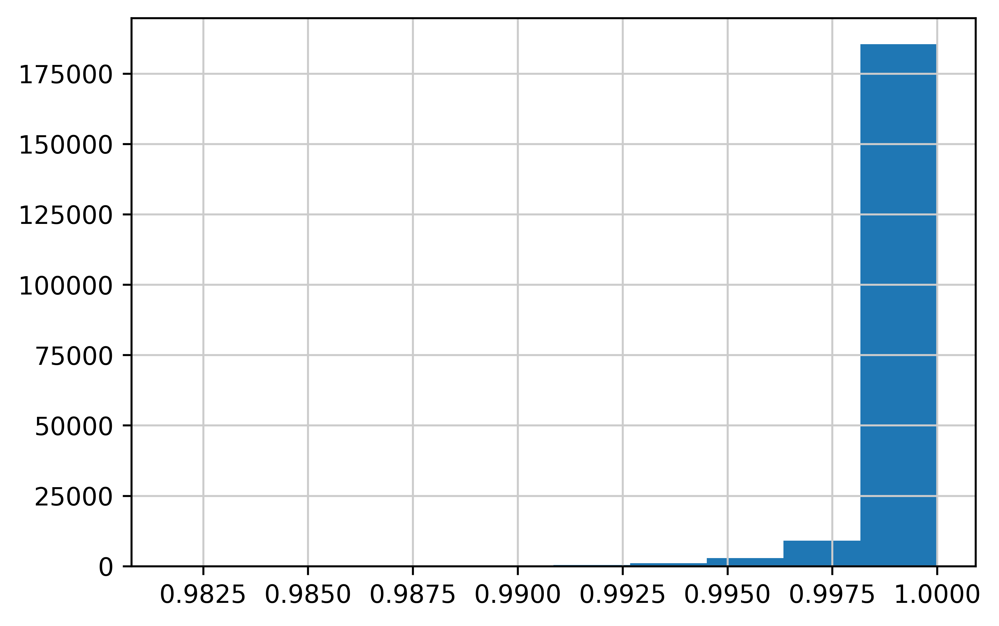

In [64]:
A = adata_sub_cell_pert.obsm['spatial_cell_emb']
B = adata_sub_cell_pert.obsm['spatial_cell_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

spatial_cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(spatial_cell_emb_cos_sim))
print(np.min(spatial_cell_emb_cos_sim))
plt.hist(spatial_cell_emb_cos_sim)

0.99960023
0.98163074


(array([6.00000e+00, 9.00000e+00, 2.50000e+01, 6.50000e+01, 1.61000e+02,
        4.08000e+02, 8.89000e+02, 2.23400e+03, 6.85200e+03, 1.88519e+05]),
 array([0.98163074, 0.98346764, 0.98530459, 0.98714149, 0.98897839,
        0.99081528, 0.99265224, 0.99448913, 0.99632603, 0.99816298,
        0.99999988]),
 <BarContainer object of 10 artists>)

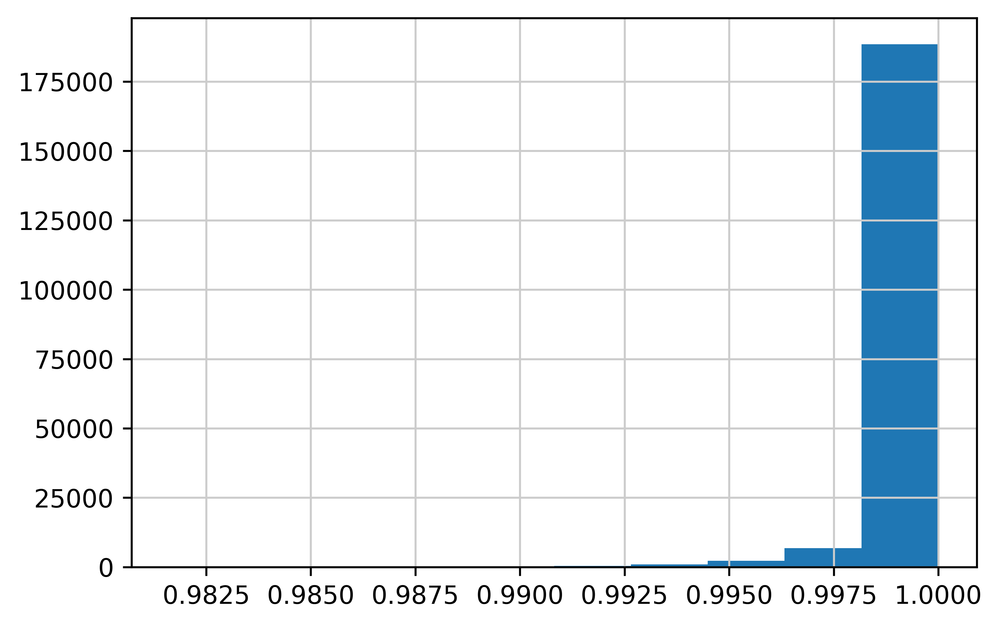

In [65]:
A = adata_sub_cell_pert.obsm['neighborhood_emb']
B = adata_sub_cell_pert.obsm['neighborhood_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

neighborhood_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(neighborhood_emb_cos_sim))
print(np.min(neighborhood_emb_cos_sim))
plt.hist(neighborhood_emb_cos_sim)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


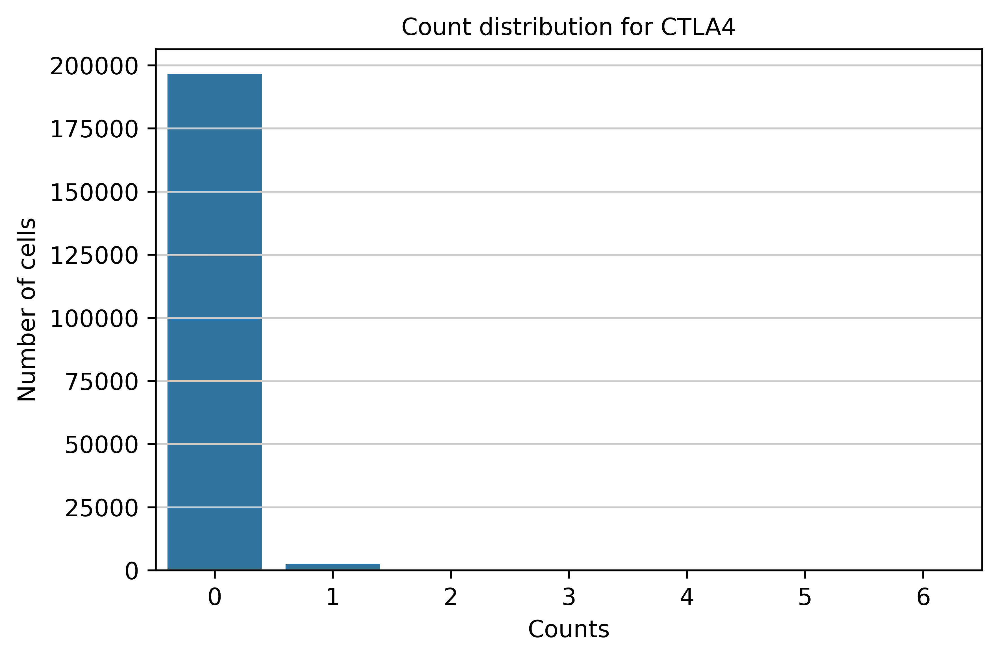

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


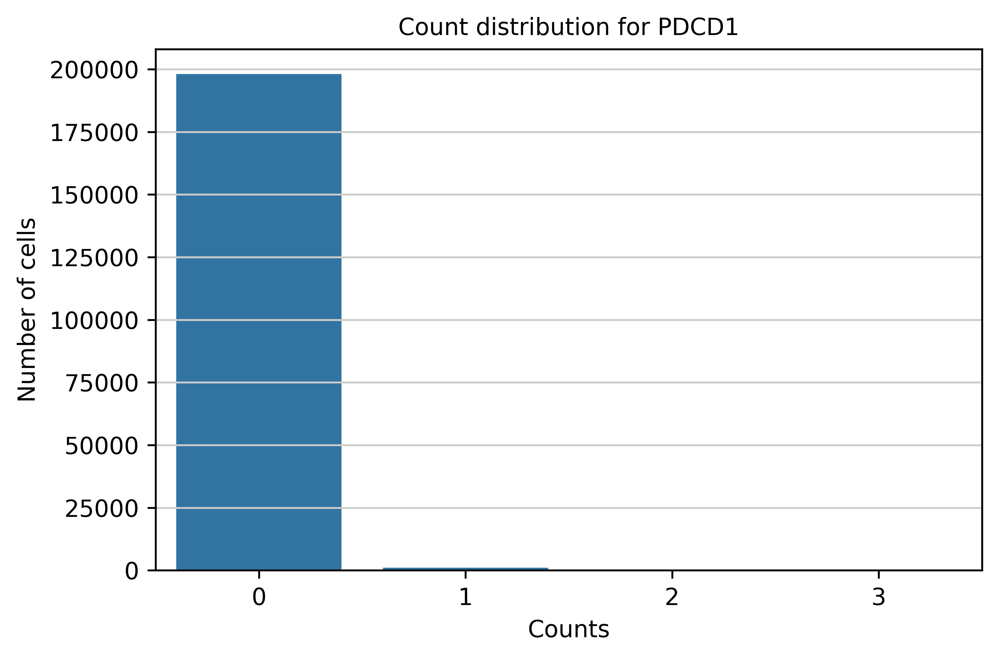

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


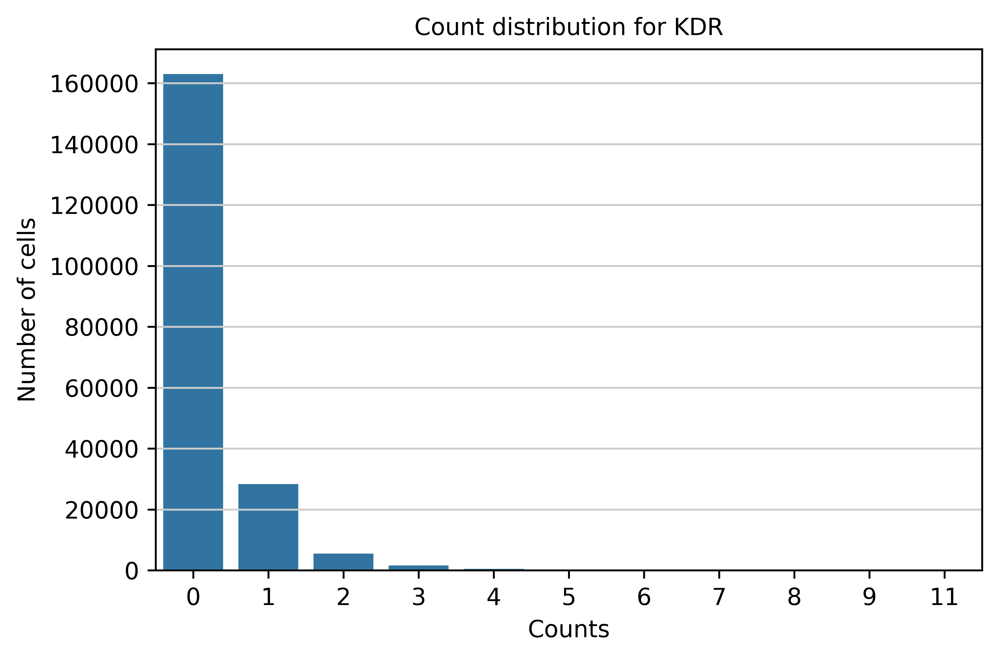

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


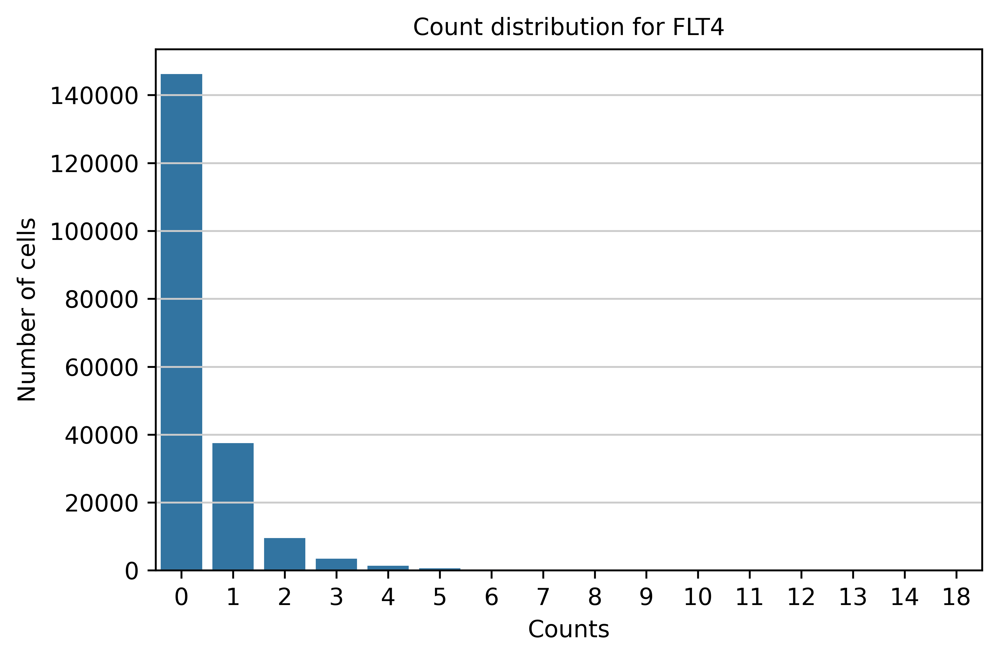

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


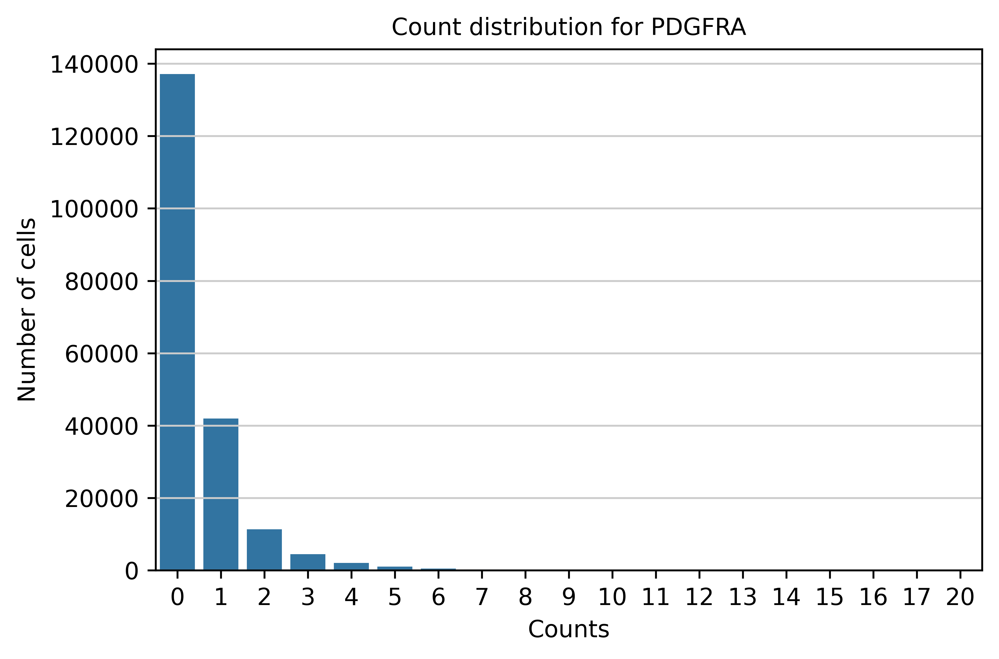

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


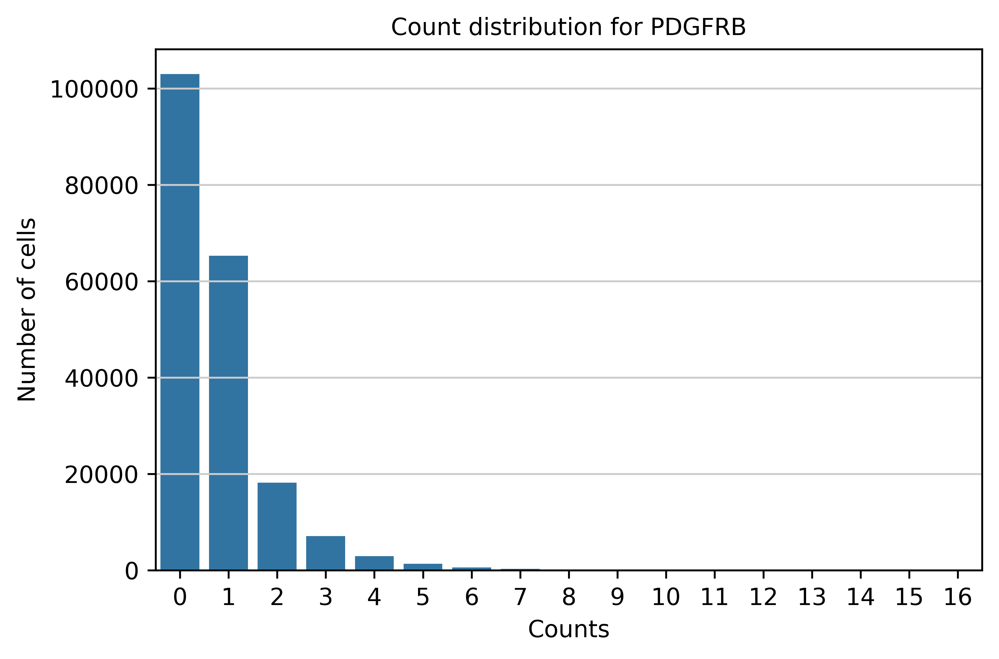

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


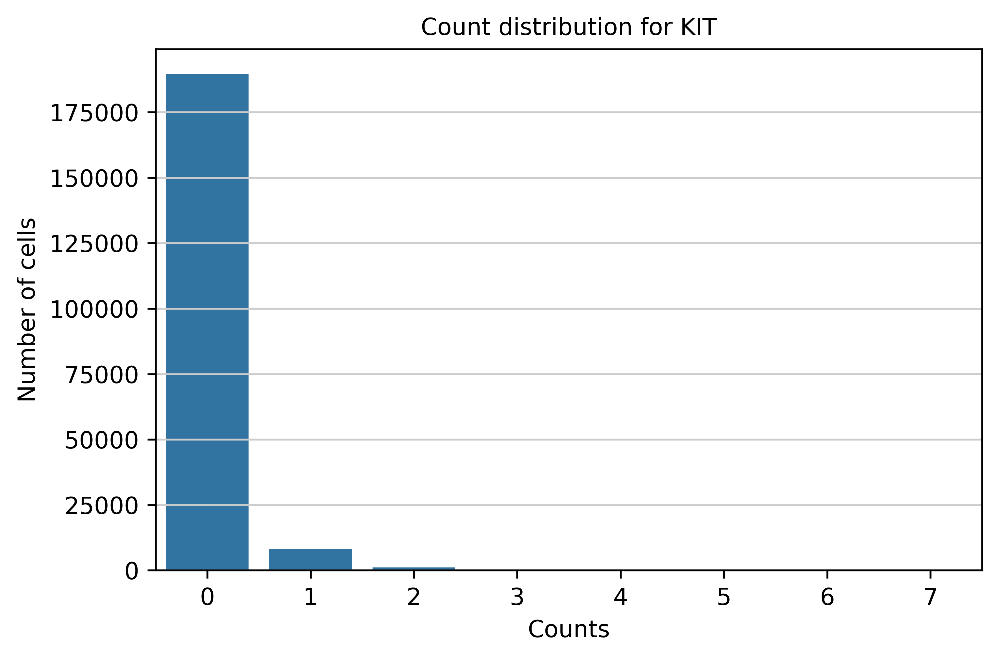

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


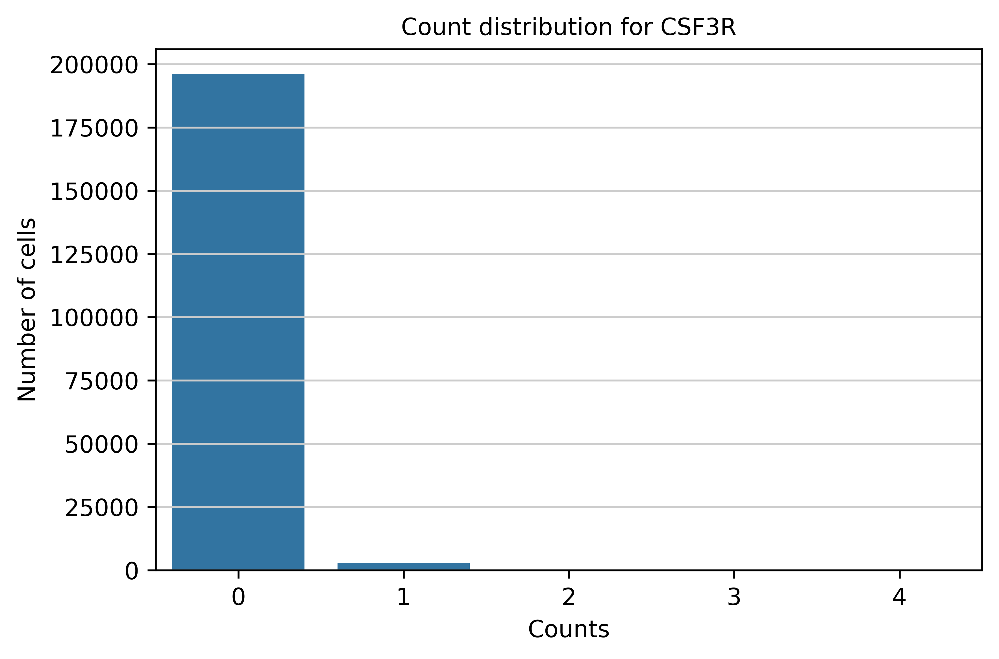

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


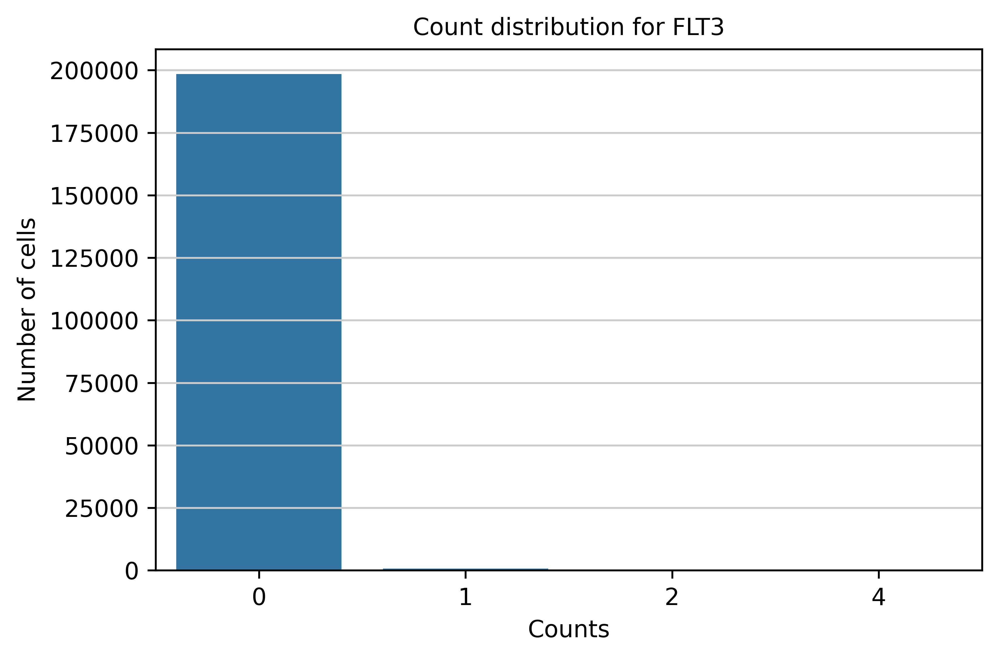

In [66]:
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].X
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


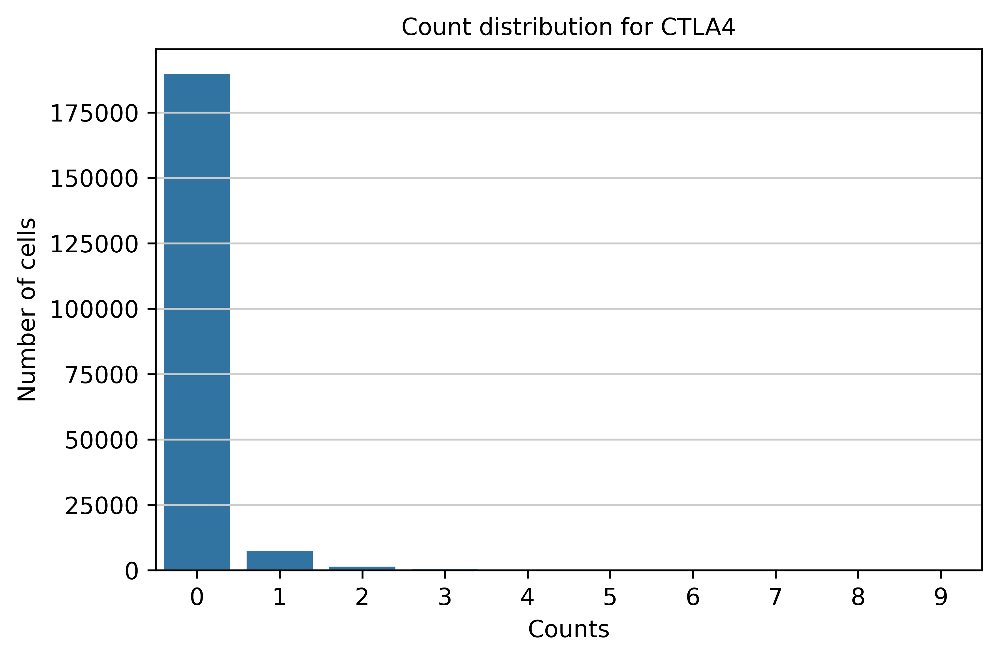

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


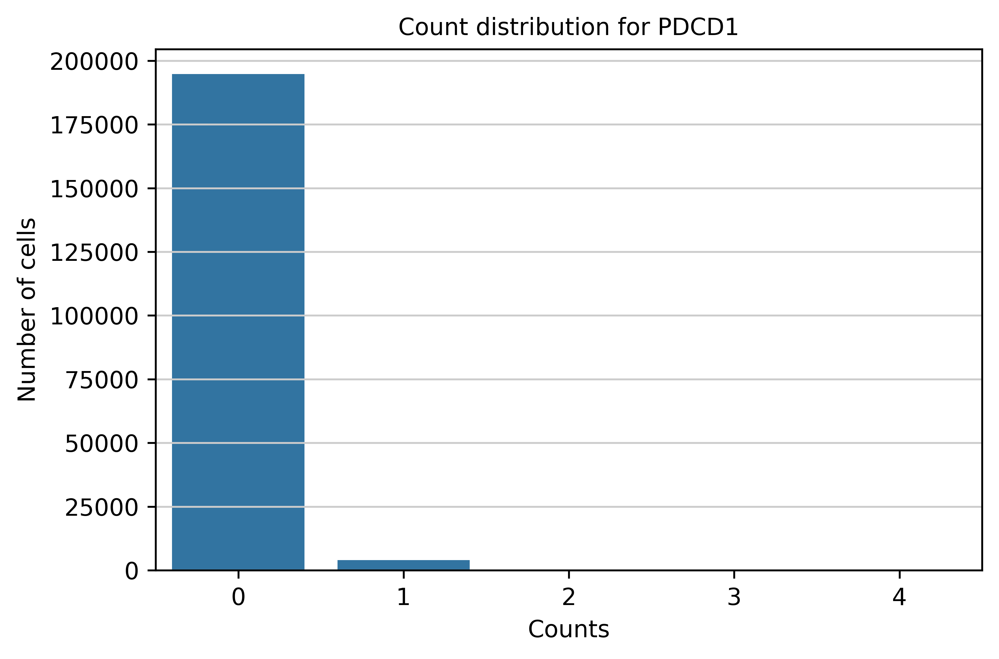

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


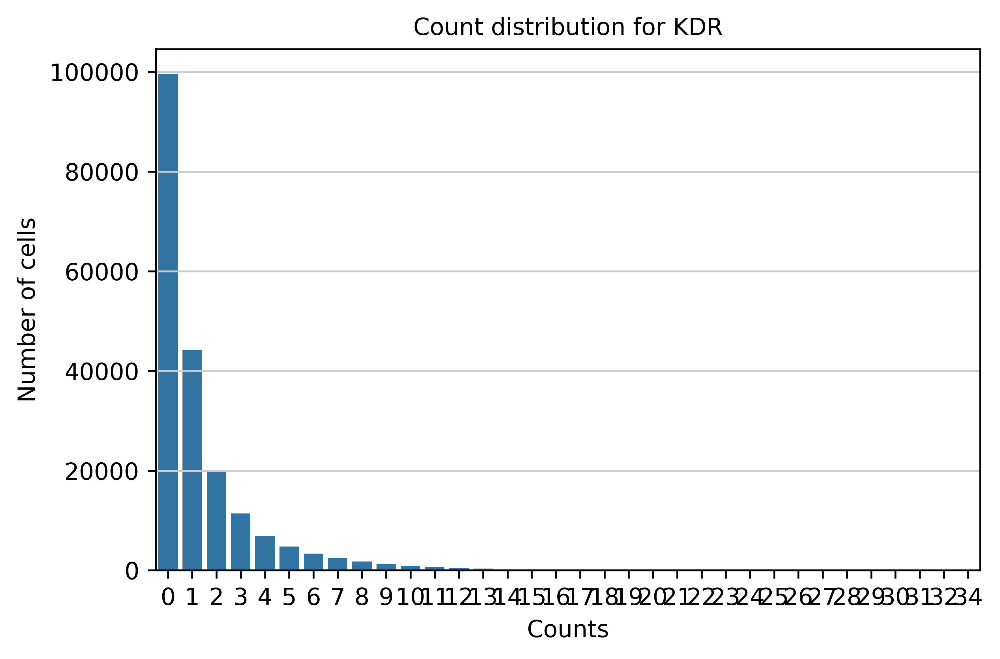

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


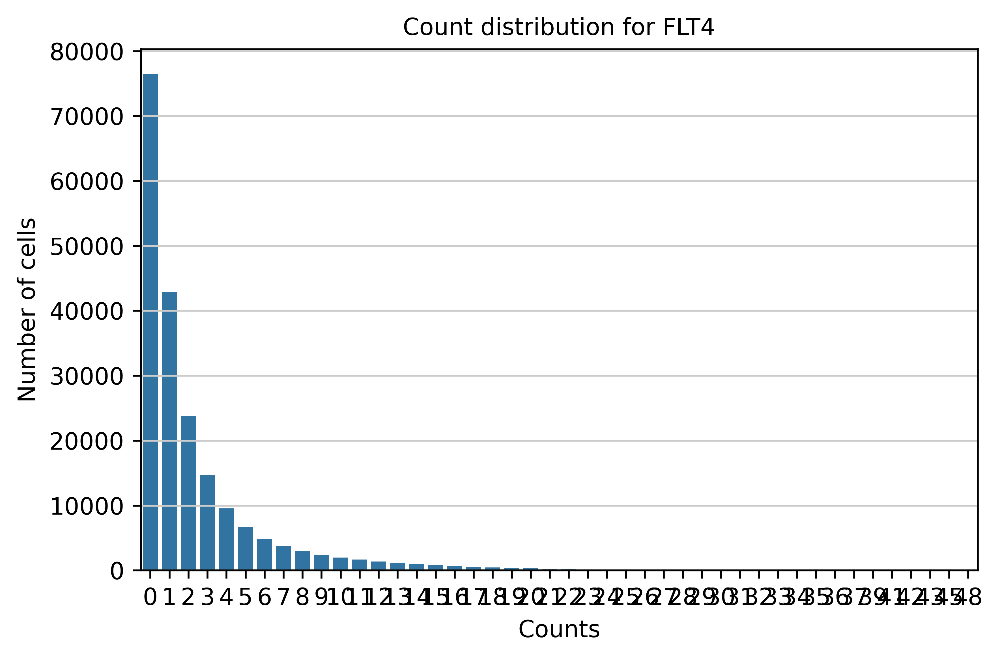

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


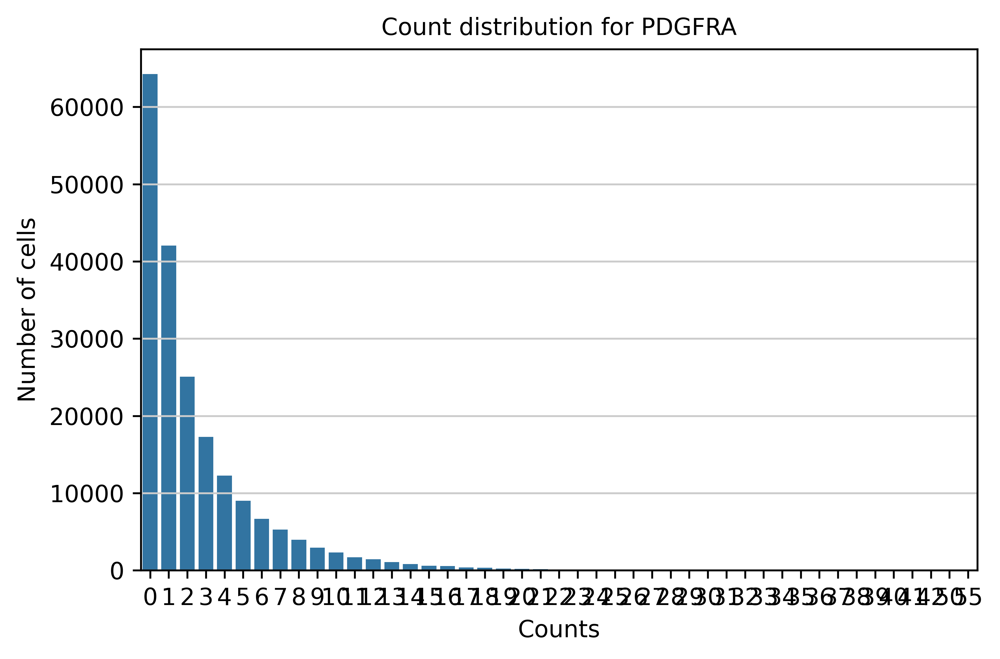

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


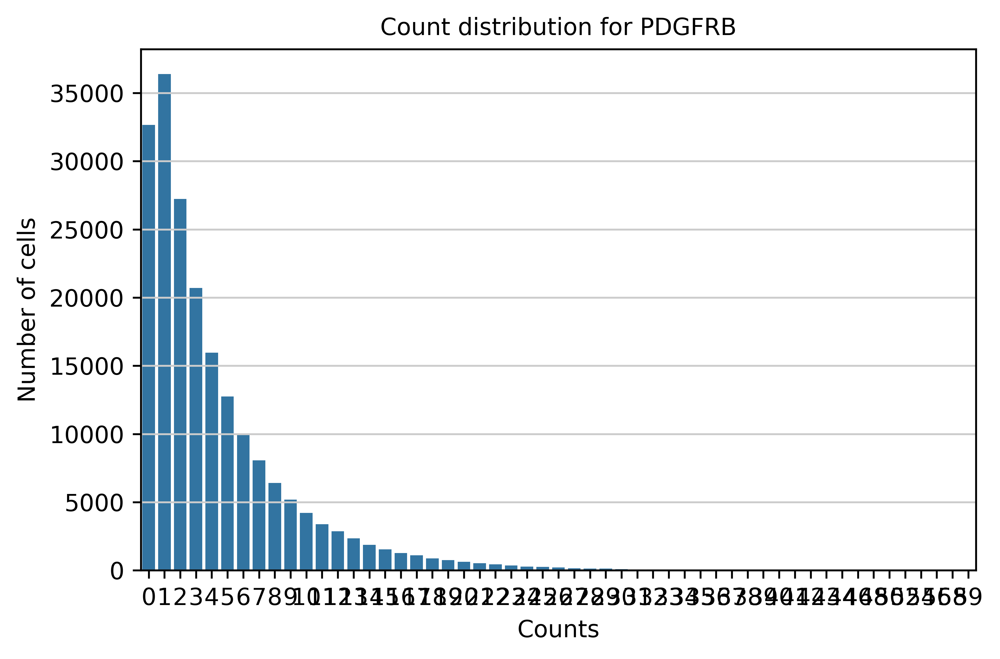

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


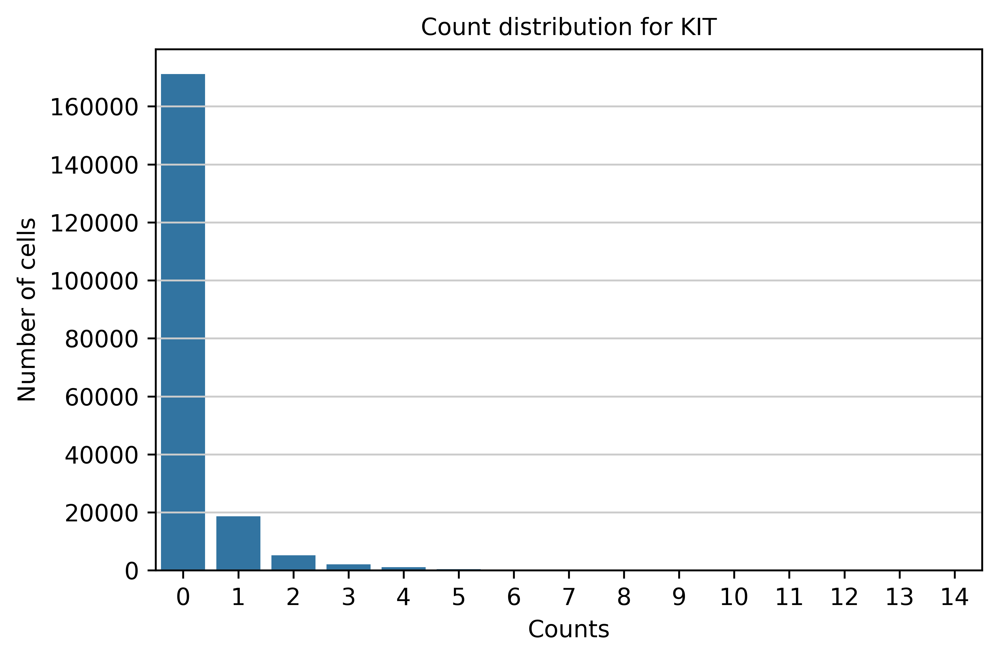

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


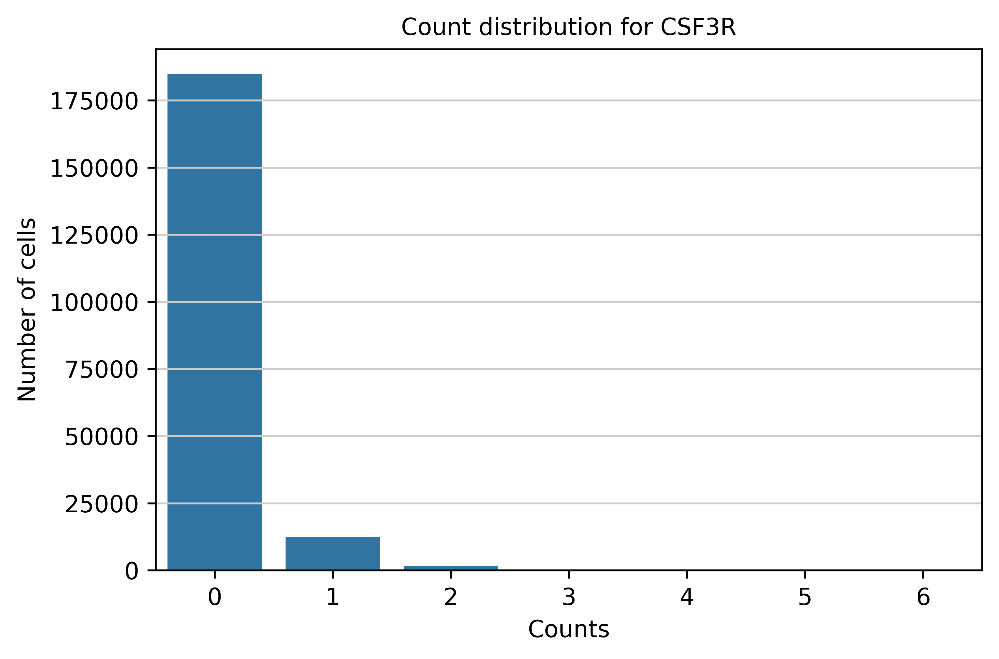

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


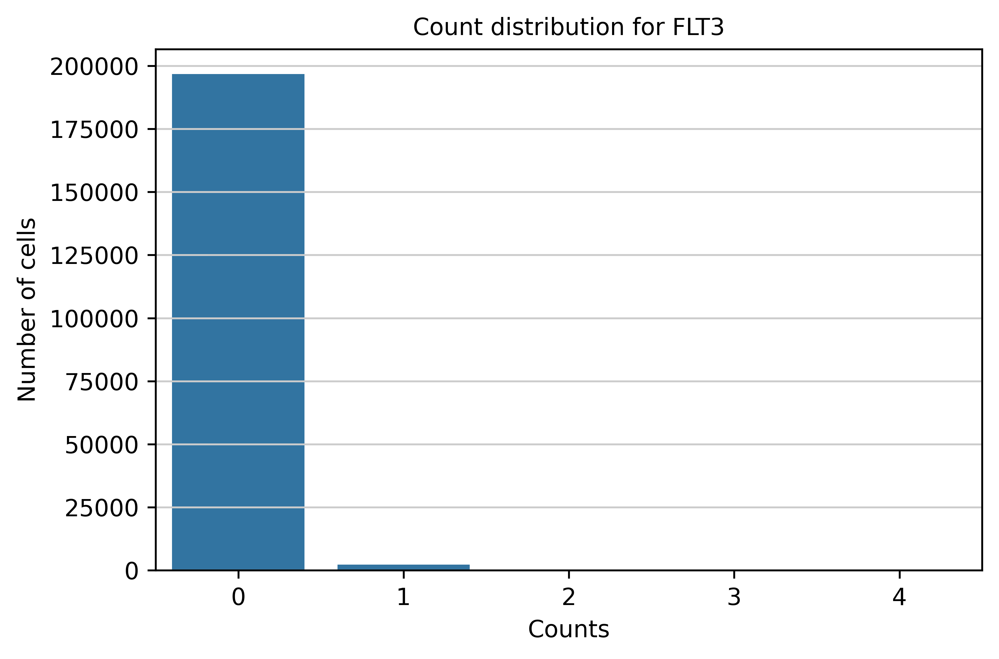

In [67]:
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].layers['counts_neighborhood']
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

#### 2.5.2.3 Neighborhood Perturbations

In [68]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [69]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

742831


In [70]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

0.9992866
0.87521726


(array([1.00000e+00, 1.00000e+00, 4.00000e+00, 7.00000e+00, 1.70000e+01,
        7.30000e+01, 2.50000e+02, 1.23700e+03, 6.90300e+03, 7.34338e+05]),
 array([0.87521726, 0.88769555, 0.90017384, 0.91265213, 0.92513043,
        0.93760872, 0.95008707, 0.96256536, 0.97504365, 0.98752195,
        1.00000024]),
 <BarContainer object of 10 artists>)

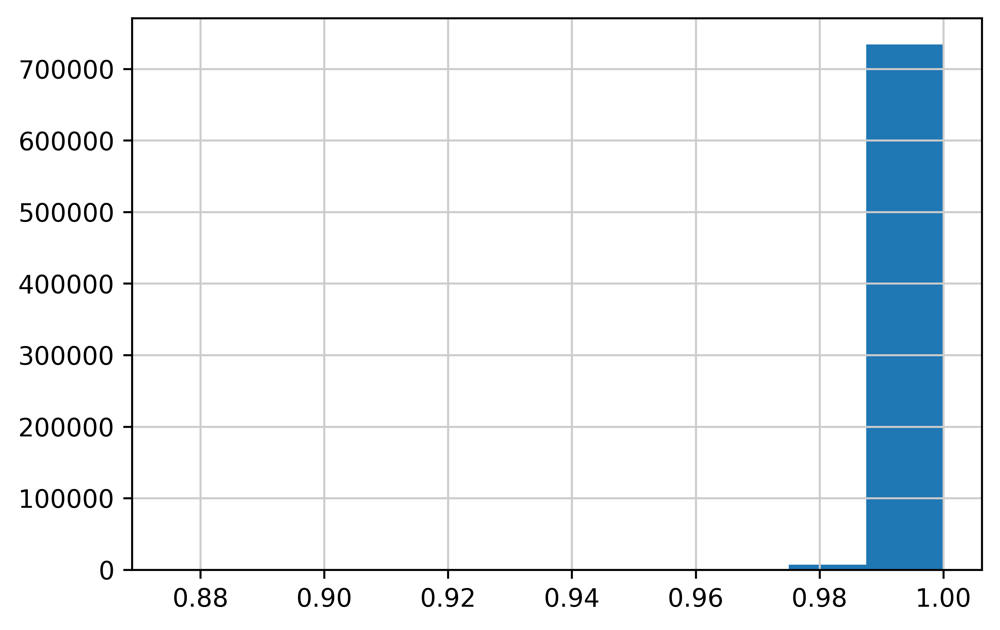

In [71]:
A = adata_sub_pert.obsm['cell_emb']
B = adata_sub_pert.obsm['cell_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(cell_emb_cos_sim))
print(np.min(cell_emb_cos_sim))
plt.hist(cell_emb_cos_sim)

0.99963576
0.9779211


(array([2.0000e+00, 8.0000e+00, 3.3000e+01, 1.0000e+02, 3.1100e+02,
        8.2100e+02, 2.1020e+03, 5.7150e+03, 1.8969e+04, 7.1477e+05]),
 array([0.97792113, 0.980129  , 0.98233688, 0.98454481, 0.98675269,
        0.98896056, 0.99116844, 0.99337631, 0.99558425, 0.99779212,
        1.        ]),
 <BarContainer object of 10 artists>)

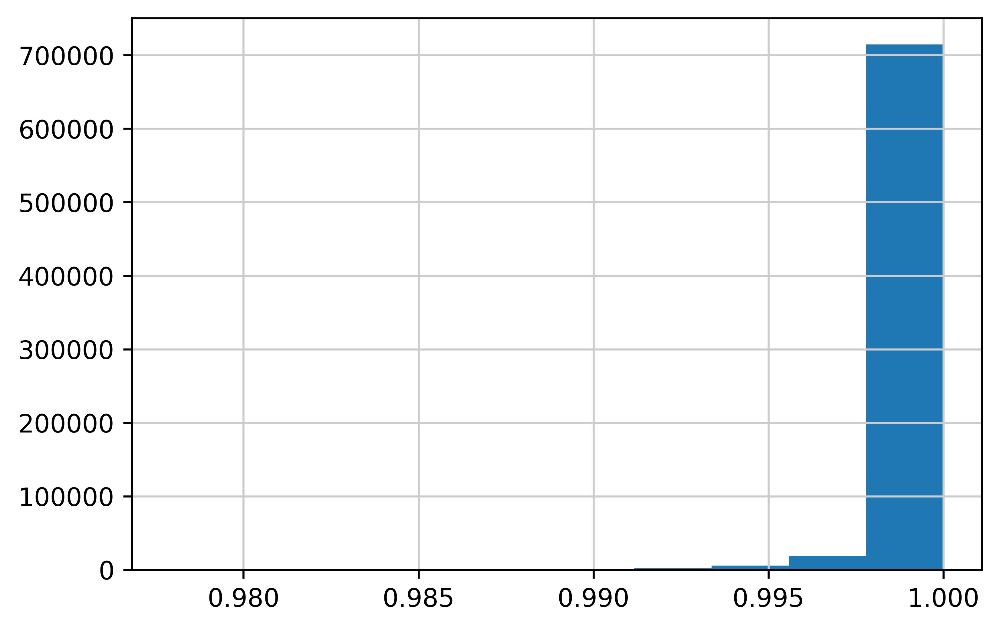

In [72]:
A = adata_sub_pert.obsm['spatial_cell_emb']
B = adata_sub_pert.obsm['spatial_cell_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

spatial_cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(spatial_cell_emb_cos_sim))
print(np.min(spatial_cell_emb_cos_sim))
plt.hist(spatial_cell_emb_cos_sim)

0.99969274
0.98037714


(array([5.00000e+00, 2.50000e+01, 5.20000e+01, 1.55000e+02, 4.01000e+02,
        9.50000e+02, 2.34000e+03, 5.72800e+03, 1.77130e+04, 7.15462e+05]),
 array([0.98037714, 0.98233944, 0.98430169, 0.98626399, 0.98822623,
        0.99018854, 0.99215084, 0.99411309, 0.99607539, 0.99803764,
        0.99999994]),
 <BarContainer object of 10 artists>)

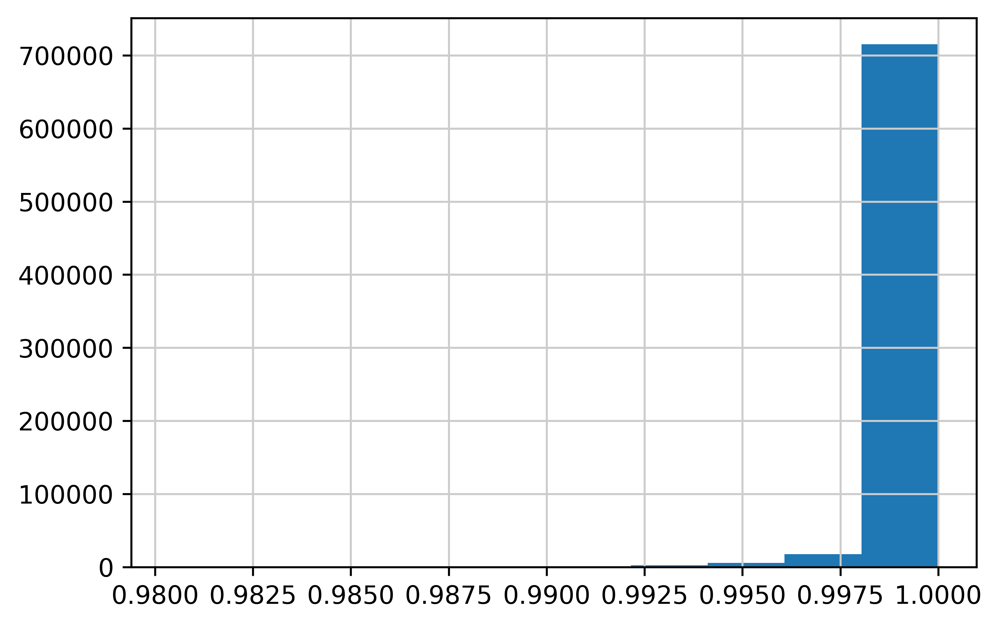

In [73]:
A = adata_sub_pert.obsm['neighborhood_emb']
B = adata_sub_pert.obsm['neighborhood_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

neighborhood_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(neighborhood_emb_cos_sim))
print(np.min(neighborhood_emb_cos_sim))
plt.hist(neighborhood_emb_cos_sim)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


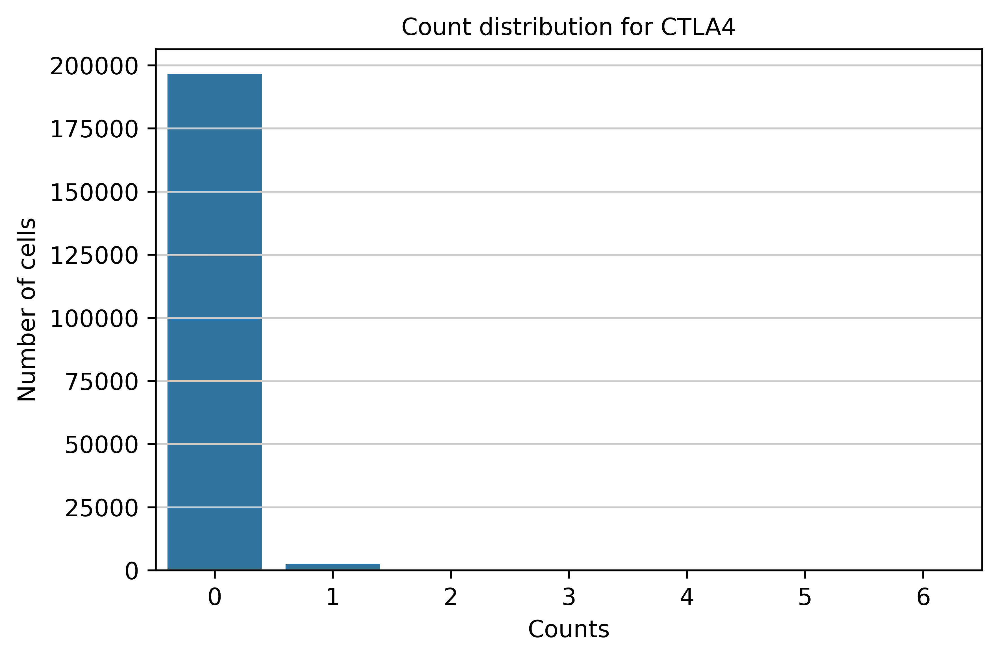

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


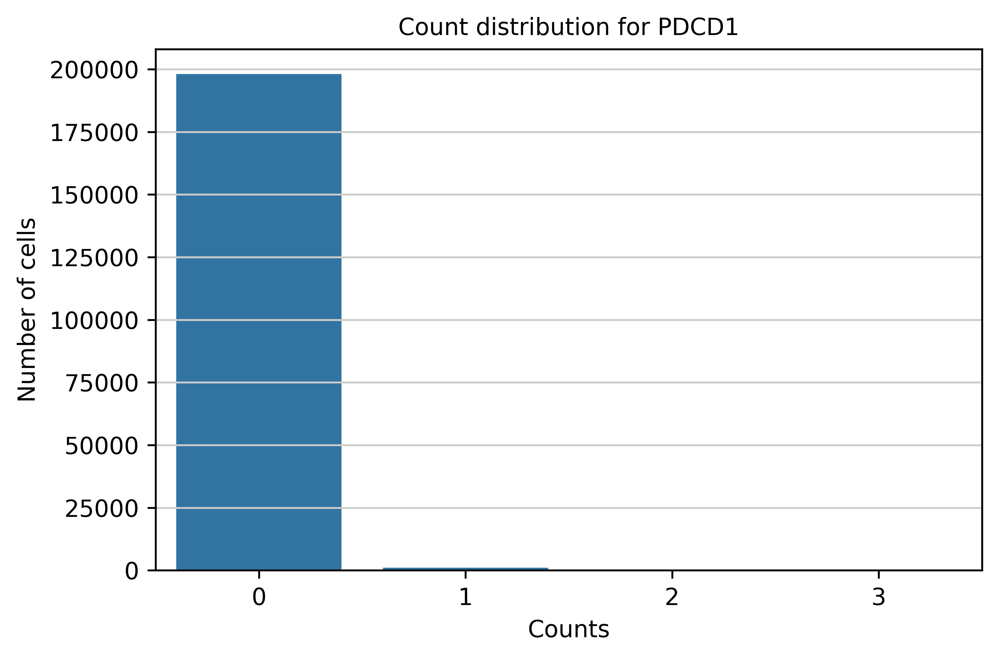

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


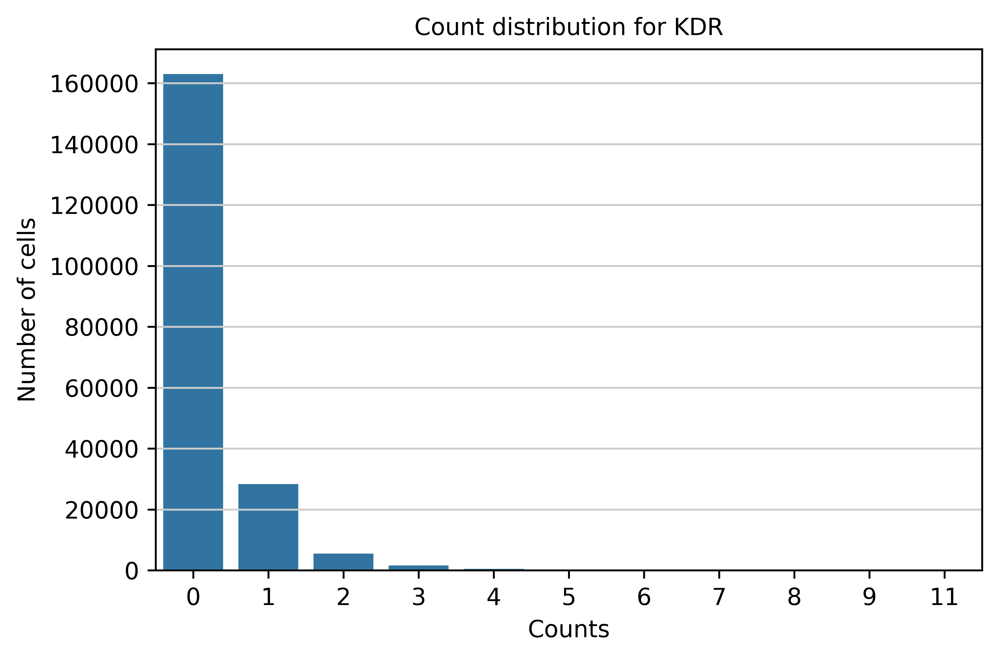

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


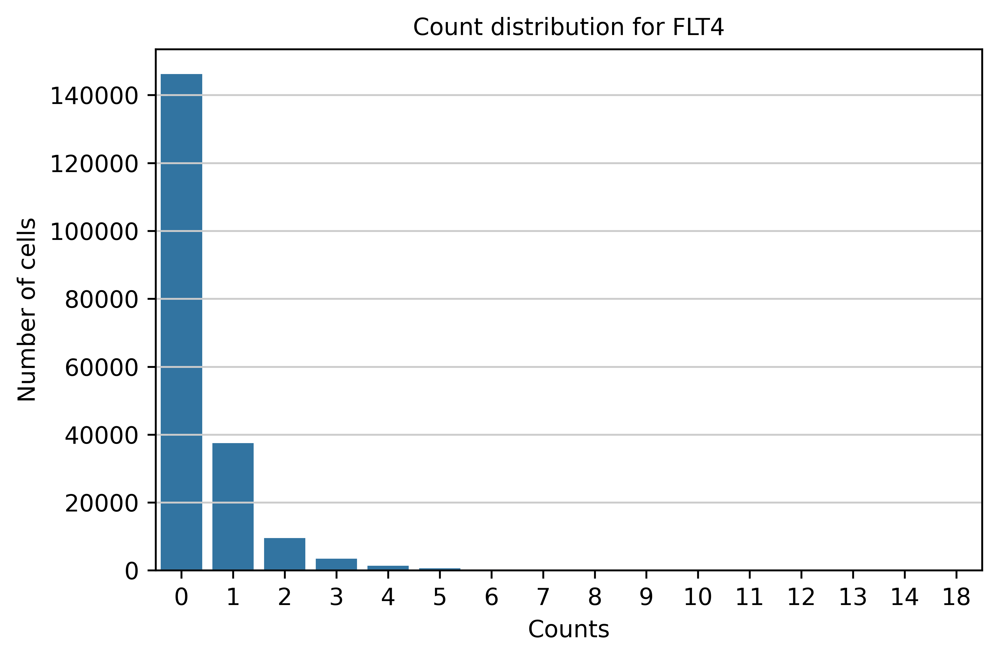

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


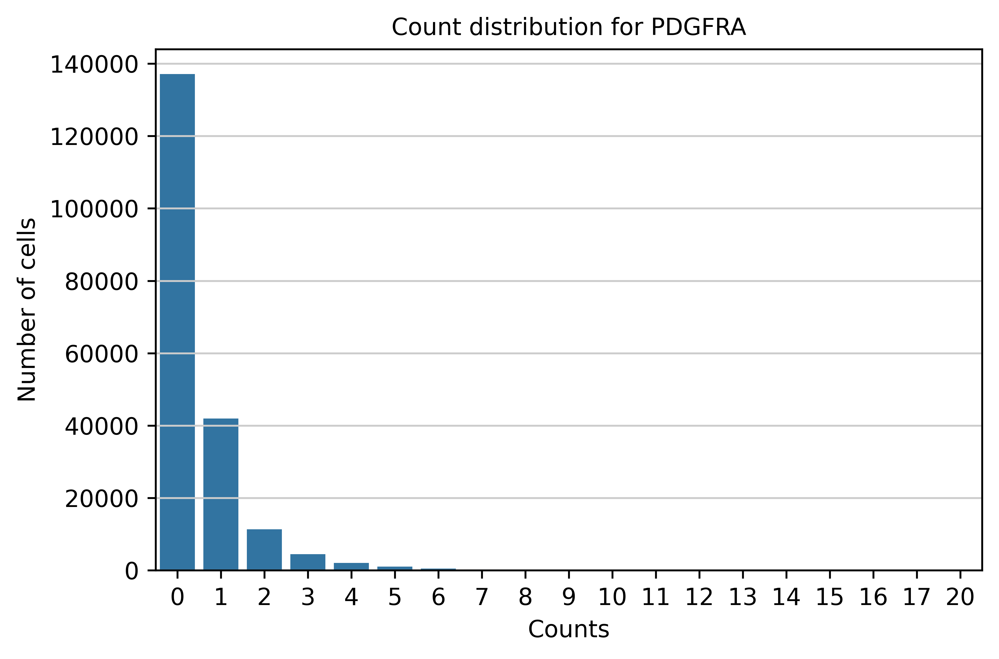

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


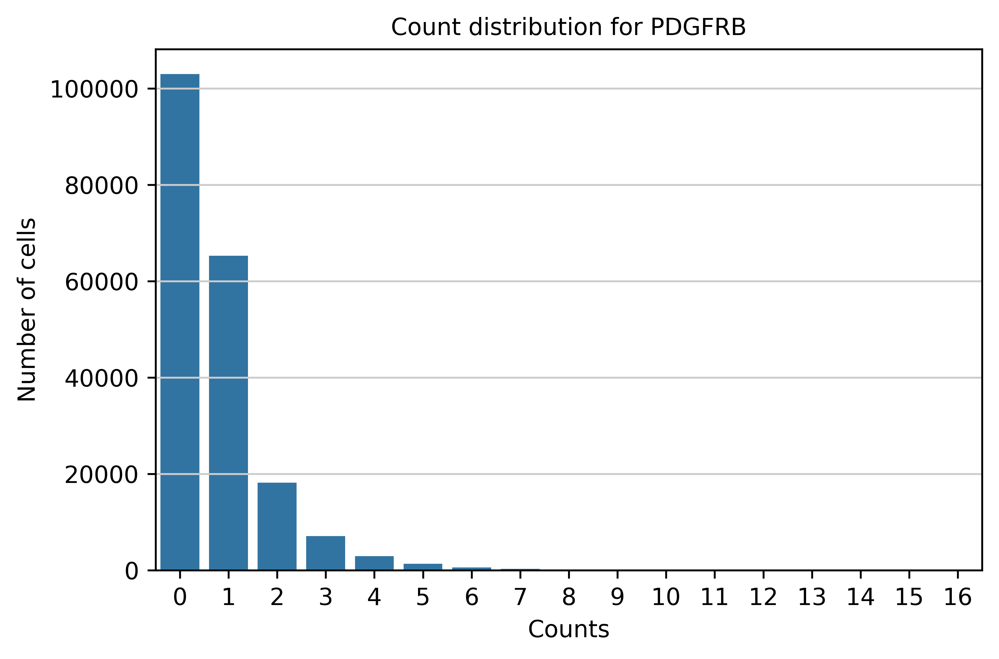

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


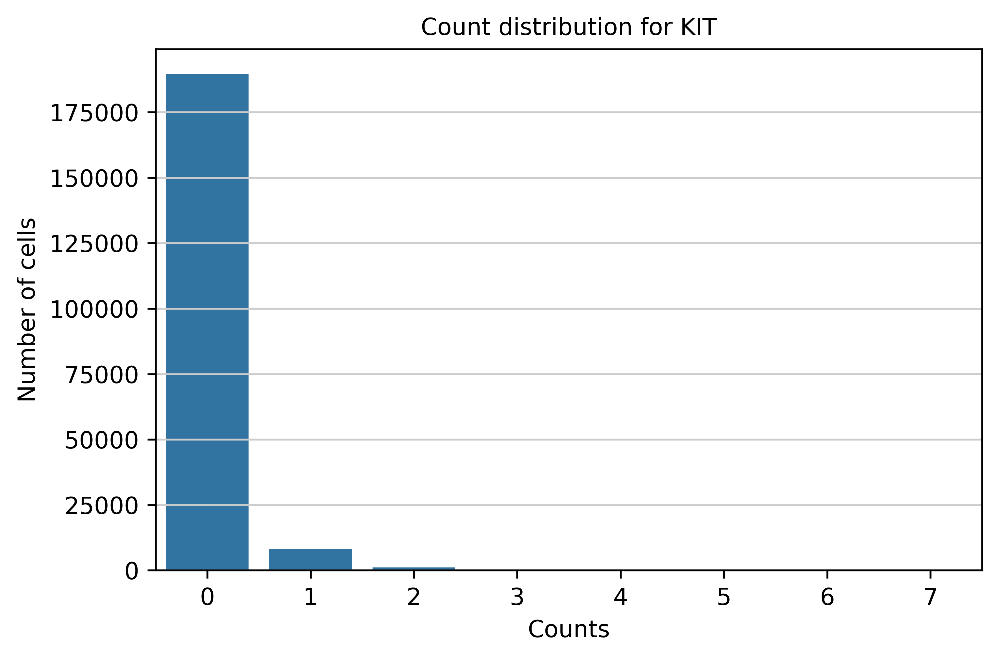

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


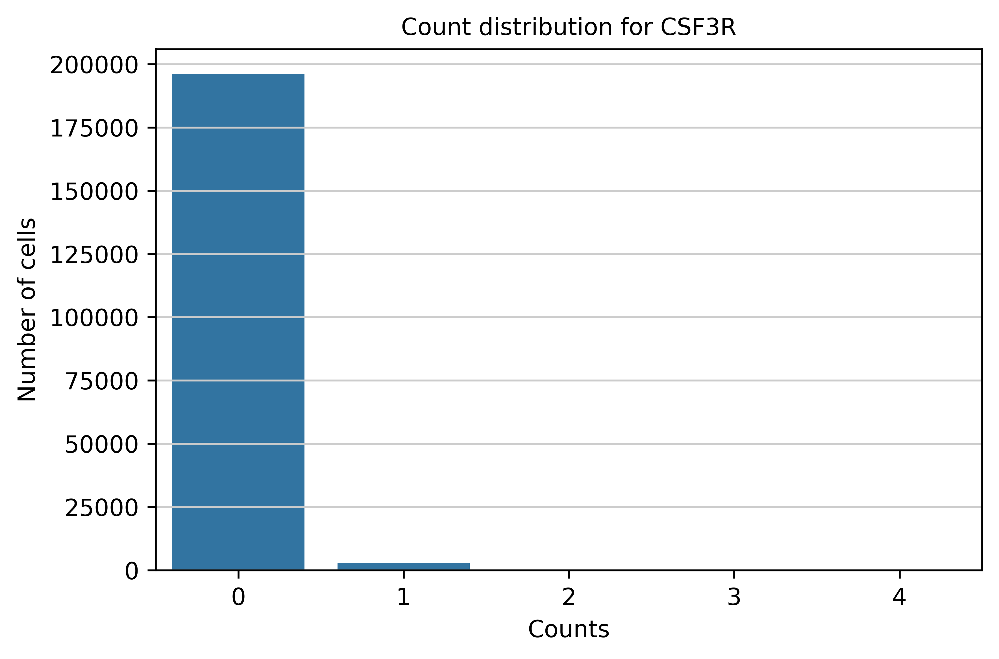

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


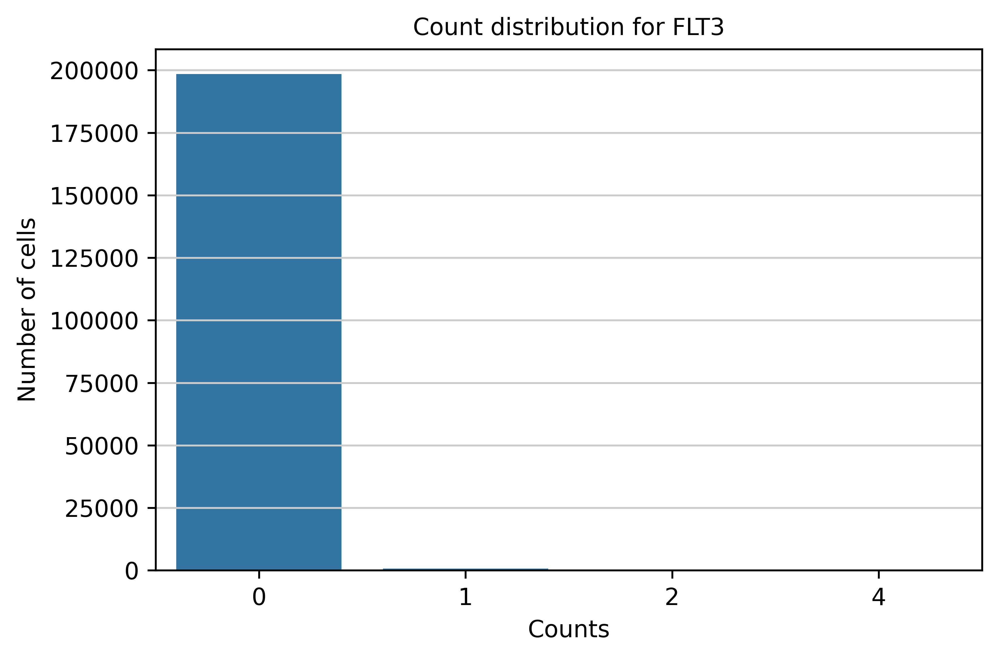

In [74]:
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].X
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


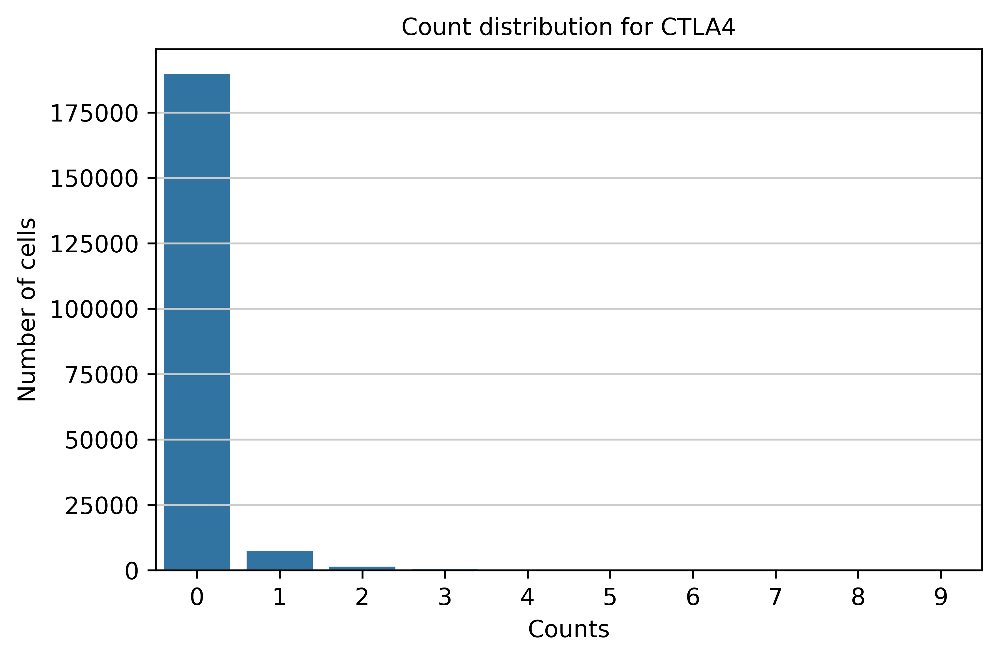

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


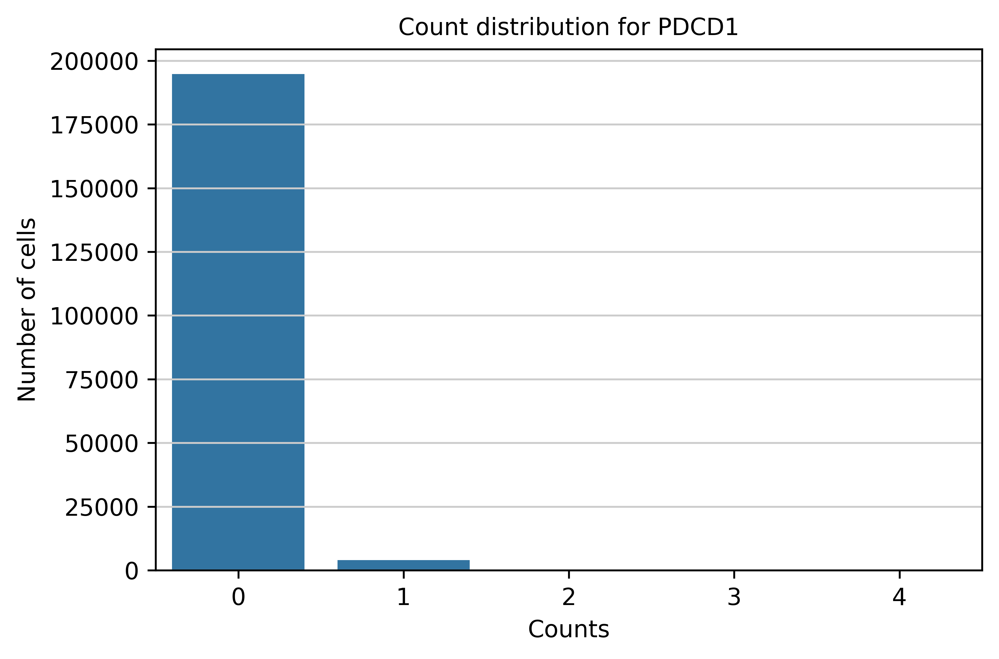

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


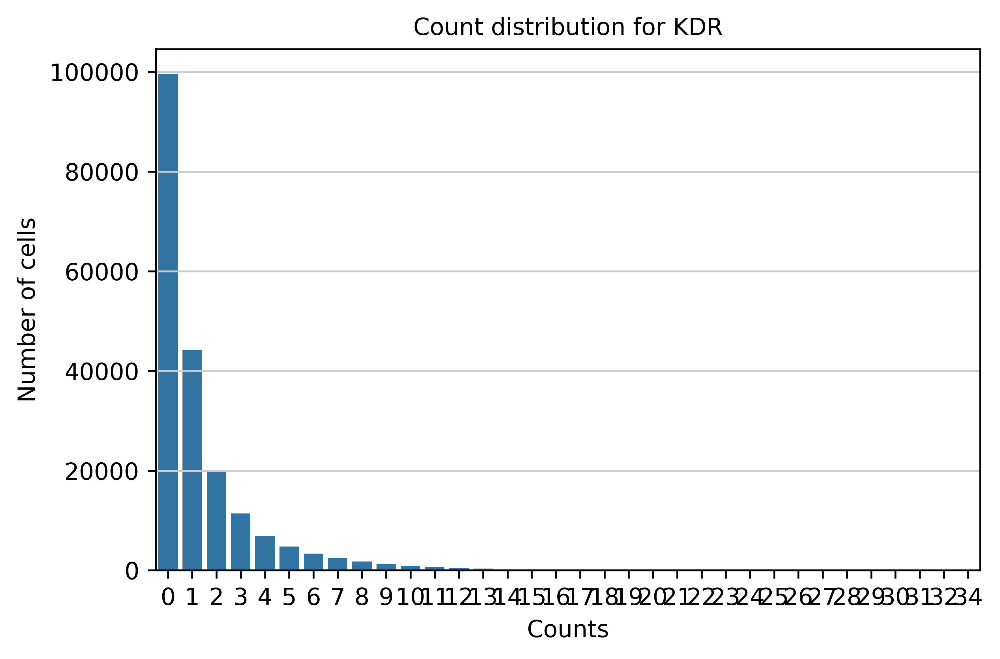

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


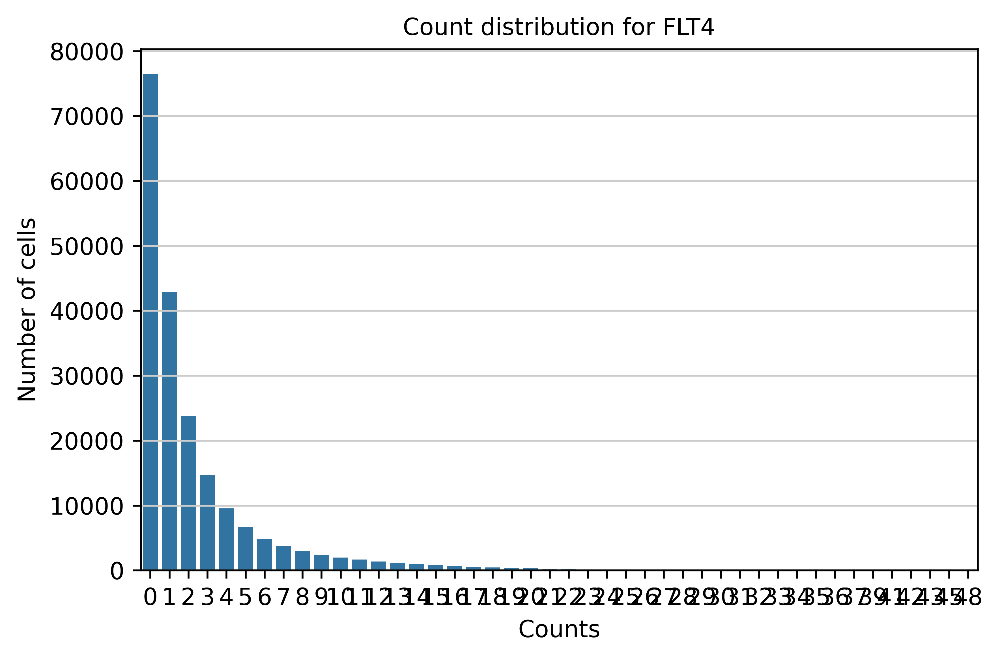

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


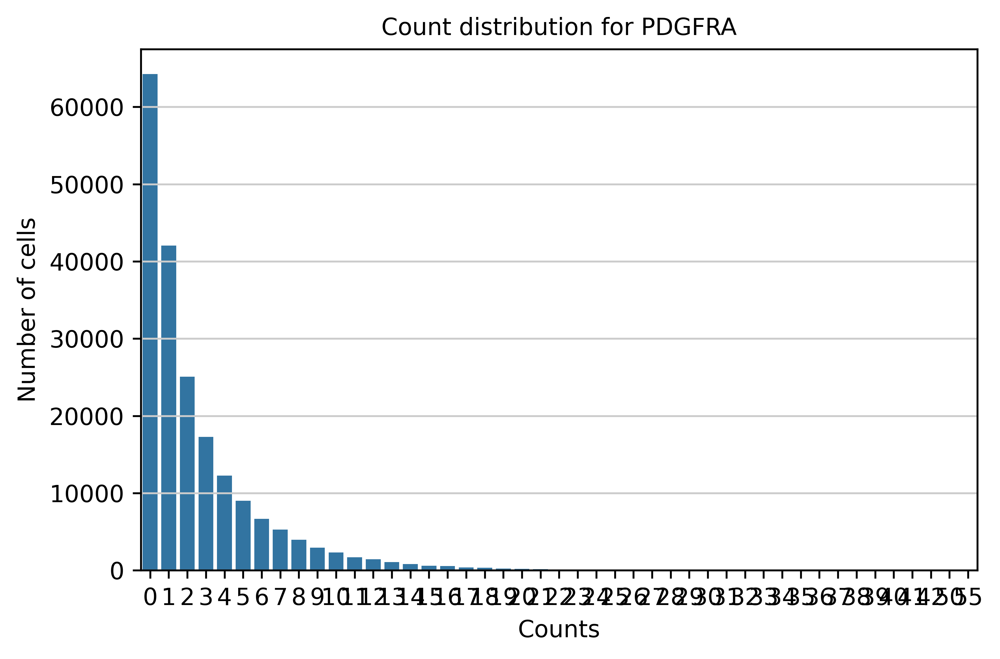

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


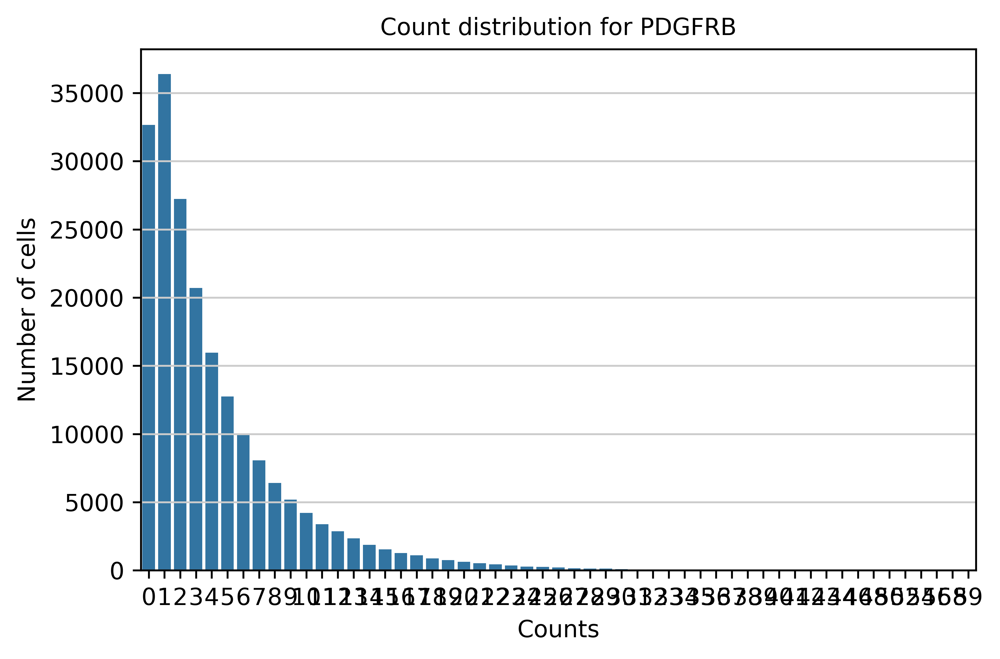

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


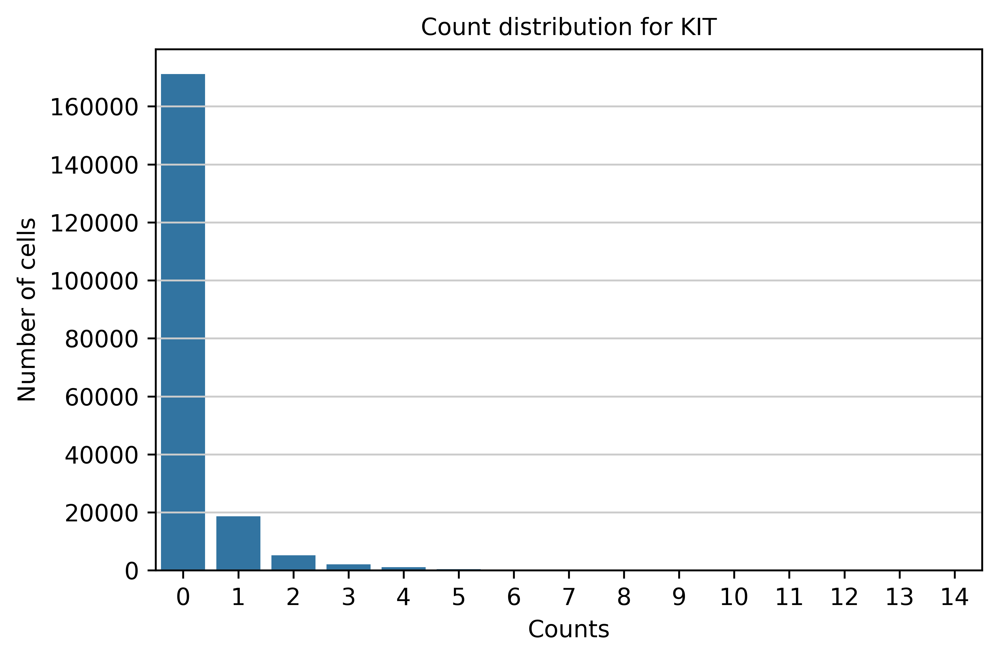

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


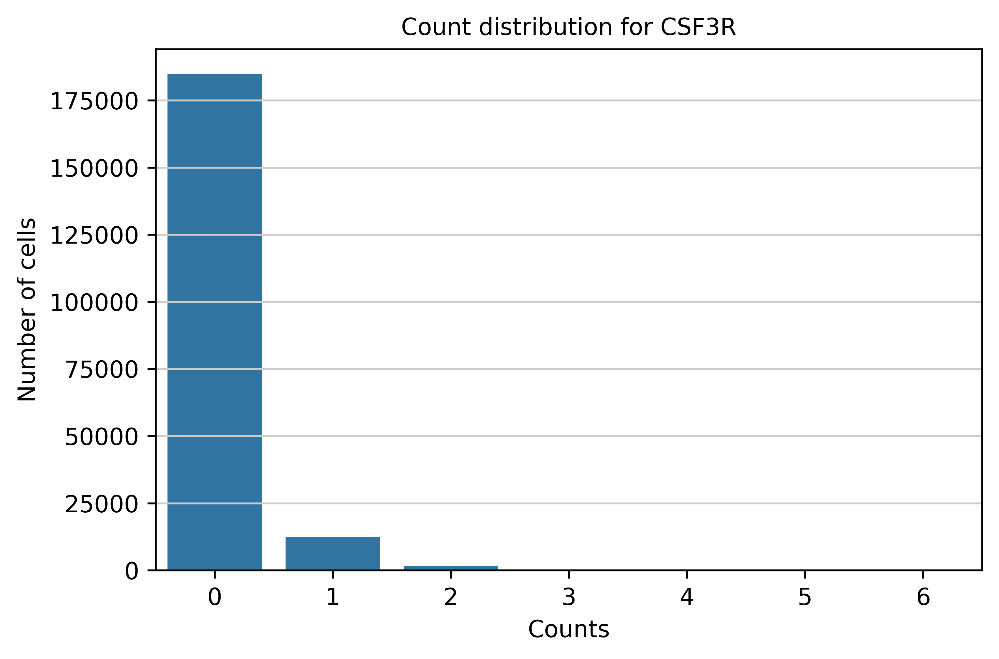

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


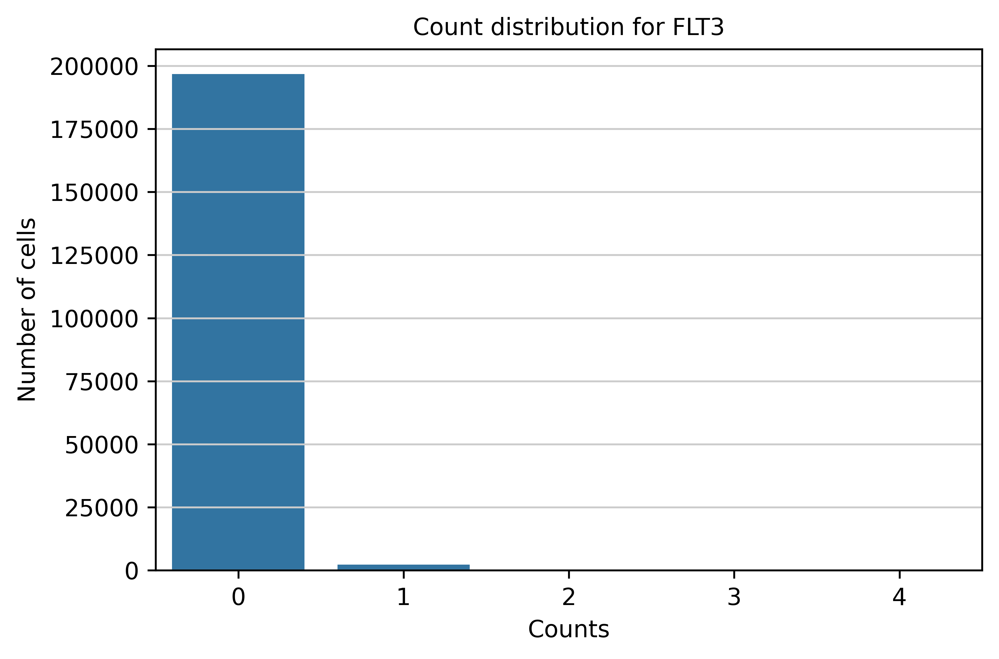

In [76]:
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].layers['counts_neighborhood']
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

### 2.5.3 Perturbation Case 3

Knockout Perturbation:
- Cell & Neighborhood
    - KDR (ENSG00000128052)
    - FLT4 (ENSG00000037280)
    - PDGFRA (ENSG00000134853)
    - PDGFRB (ENSG00000113721)
    - KIT (ENSG00000157404)
    - CSF3R (ENSG00000119535)
    - FLT3 (ENSG00000122025)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [186]:
pert_genes = [
    'KDR',
    'FLT4',
    'PDGFRA',
    'PDGFRB',
    'KIT',
    'CSF3R',
    'FLT3']

In [187]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

          ensembl_id  highly_variable  highly_variable_rank     means  \
KDR  ENSG00000128052             True                 225.0  0.042929   

     variances  variances_norm  
KDR   0.070335        1.363115  
           ensembl_id  highly_variable  highly_variable_rank     means  \
FLT4  ENSG00000037280             True                 129.0  0.071771   

      variances  variances_norm  
FLT4   0.152284        1.610407  
             ensembl_id  highly_variable  highly_variable_rank     means  \
PDGFRA  ENSG00000134853             True                 188.0  0.107361   

        variances  variances_norm  
PDGFRA   0.226664        1.465978  
             ensembl_id  highly_variable  highly_variable_rank     means  \
PDGFRB  ENSG00000113721             True                 348.0  0.157412   

        variances  variances_norm  
PDGFRB   0.314816        1.230433  
          ensembl_id  highly_variable  highly_variable_rank     means  \
KIT  ENSG00000157404             True          

In [188]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case3")

#### 2.5.3.1 Cell Perturbations

In [189]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

Filter: 100%|██████████| 737081/737081 [01:57<00:00, 6299.47 examples/s]


In [190]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

196634


In [191]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

0.9973362
0.87521726


(array([1.00000e+00, 1.00000e+00, 4.00000e+00, 7.00000e+00, 1.70000e+01,
        7.30000e+01, 2.48000e+02, 1.23000e+03, 6.82900e+03, 1.88224e+05]),
 array([0.87521726, 0.88769531, 0.90017337, 0.91265142, 0.92512947,
        0.93760753, 0.95008552, 0.96256357, 0.97504163, 0.98751968,
        0.99999774]),
 <BarContainer object of 10 artists>)

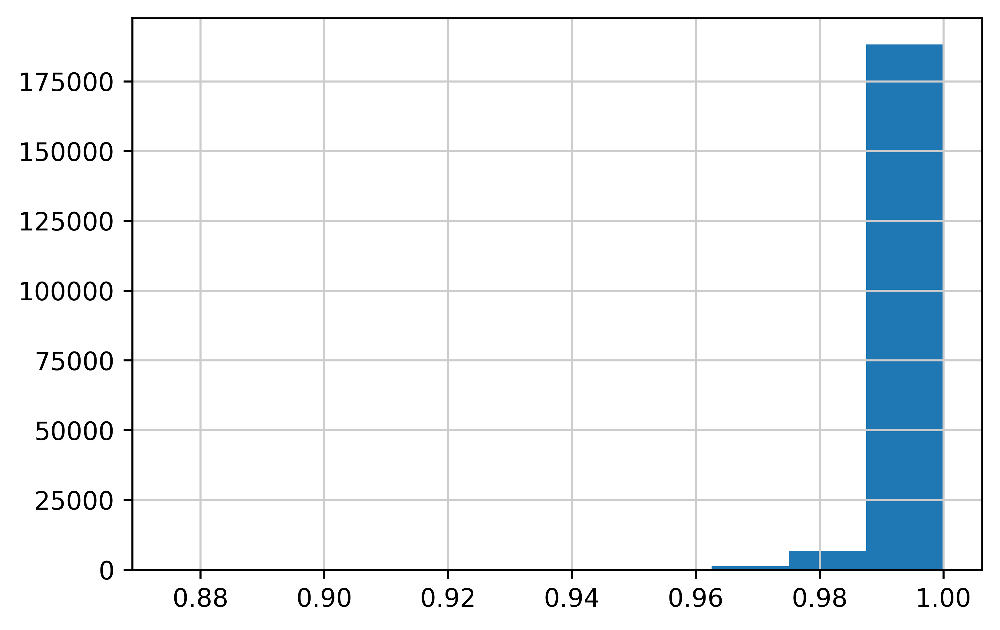

In [192]:
A = adata_sub_cell_pert.obsm['cell_emb']
B = adata_sub_cell_pert.obsm['cell_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(cell_emb_cos_sim))
print(np.min(cell_emb_cos_sim))
plt.hist(cell_emb_cos_sim)

0.9994669
0.98170245


(array([6.00000e+00, 8.00000e+00, 2.30000e+01, 6.70000e+01, 1.85000e+02,
        4.33000e+02, 1.02700e+03, 2.78600e+03, 9.01600e+03, 1.83083e+05]),
 array([0.98170245, 0.98353195, 0.9853614 , 0.9871909 , 0.98902035,
        0.99084985, 0.99267936, 0.9945088 , 0.99633831, 0.99816775,
        0.99999726]),
 <BarContainer object of 10 artists>)

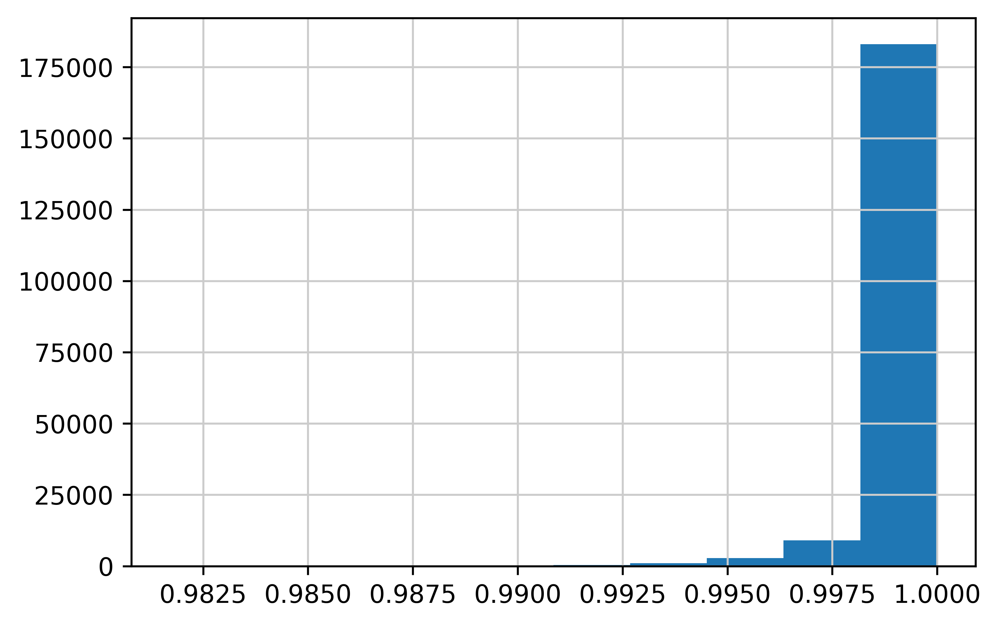

In [193]:
A = adata_sub_cell_pert.obsm['spatial_cell_emb']
B = adata_sub_cell_pert.obsm['spatial_cell_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

spatial_cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(spatial_cell_emb_cos_sim))
print(np.min(spatial_cell_emb_cos_sim))
plt.hist(spatial_cell_emb_cos_sim)

0.9995993
0.98163074


(array([6.00000e+00, 8.00000e+00, 2.30000e+01, 6.50000e+01, 1.58000e+02,
        4.04000e+02, 8.83000e+02, 2.21400e+03, 6.79500e+03, 1.86078e+05]),
 array([0.98163074, 0.98346764, 0.98530459, 0.98714149, 0.98897839,
        0.99081528, 0.99265224, 0.99448913, 0.99632603, 0.99816298,
        0.99999988]),
 <BarContainer object of 10 artists>)

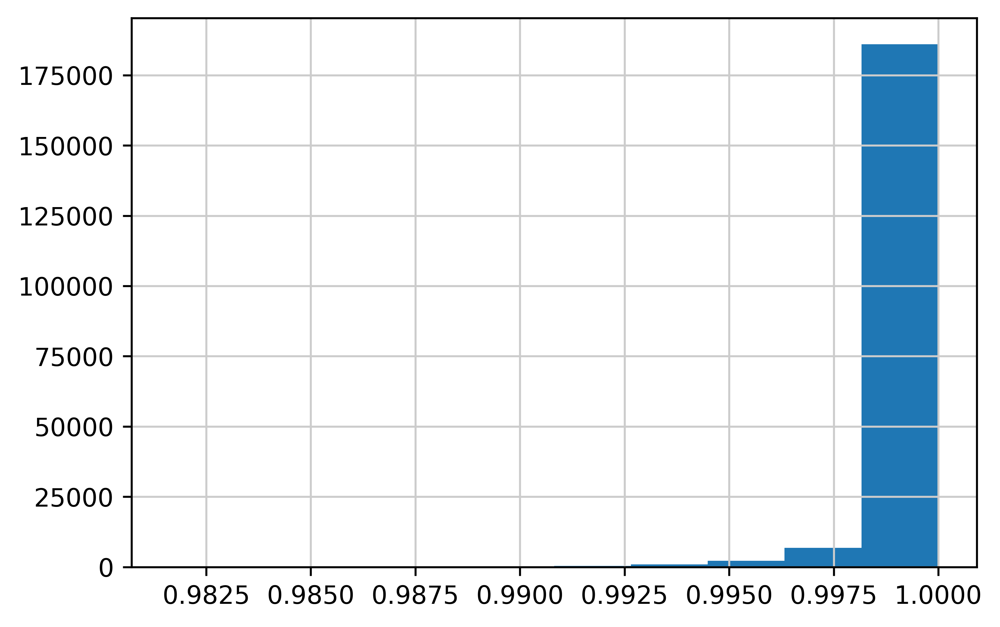

In [194]:
A = adata_sub_cell_pert.obsm['neighborhood_emb']
B = adata_sub_cell_pert.obsm['neighborhood_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

neighborhood_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(neighborhood_emb_cos_sim))
print(np.min(neighborhood_emb_cos_sim))
plt.hist(neighborhood_emb_cos_sim)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


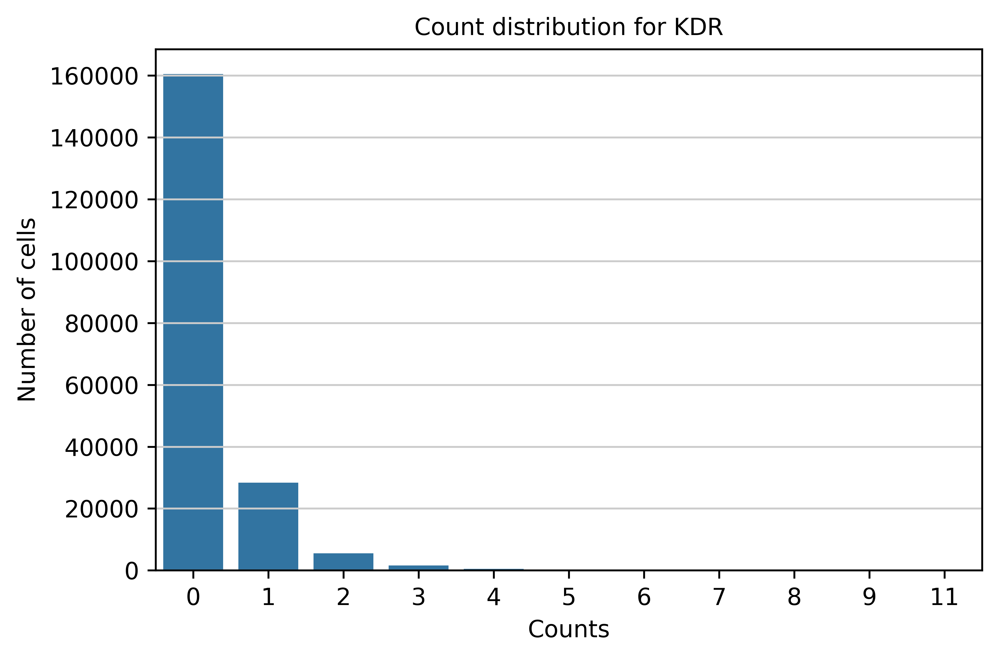

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


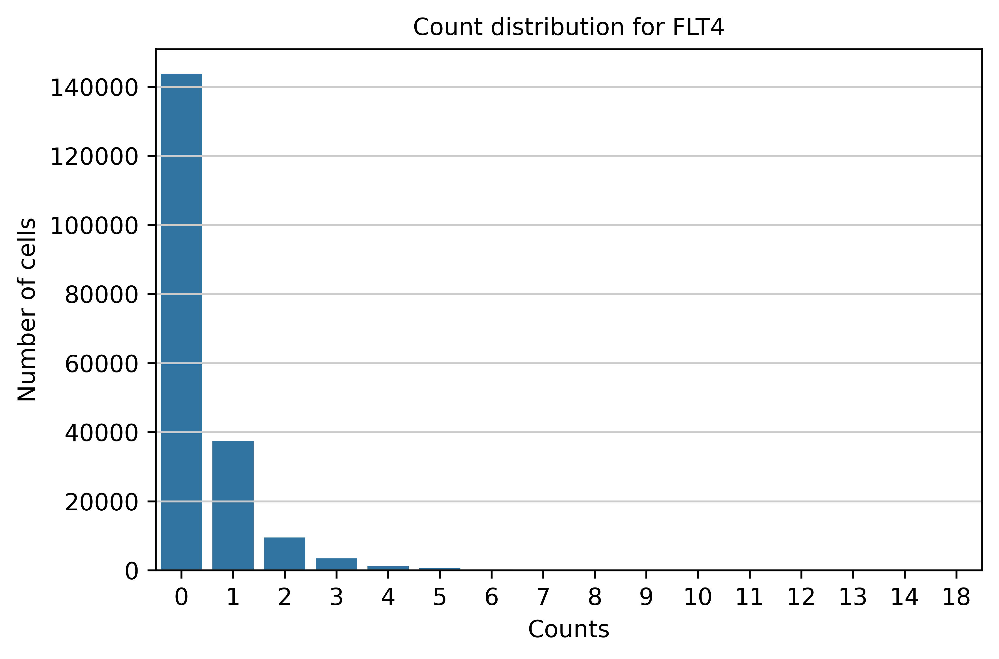

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


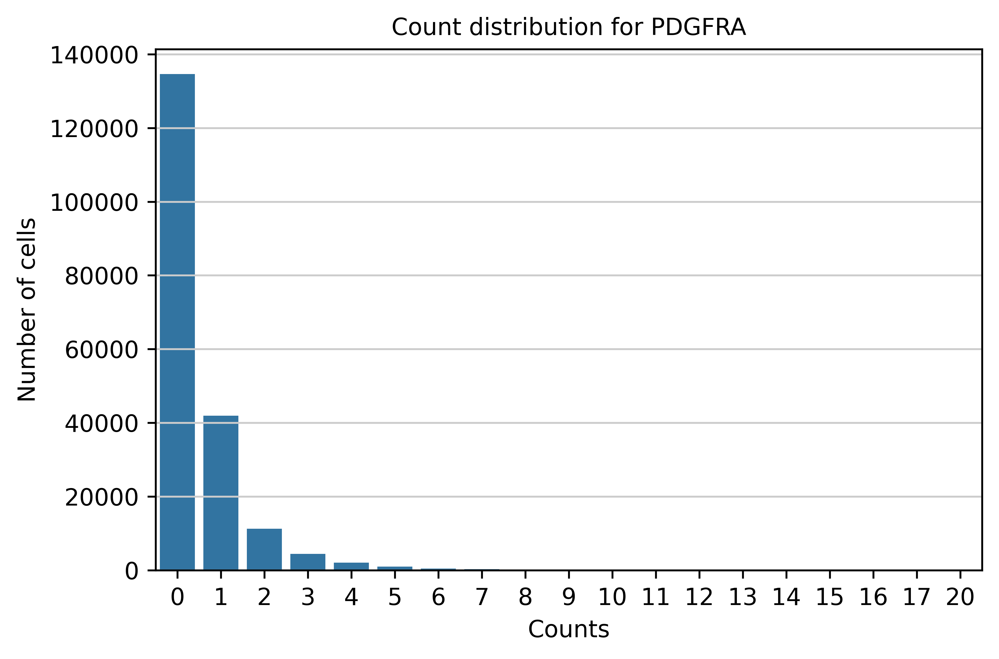

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


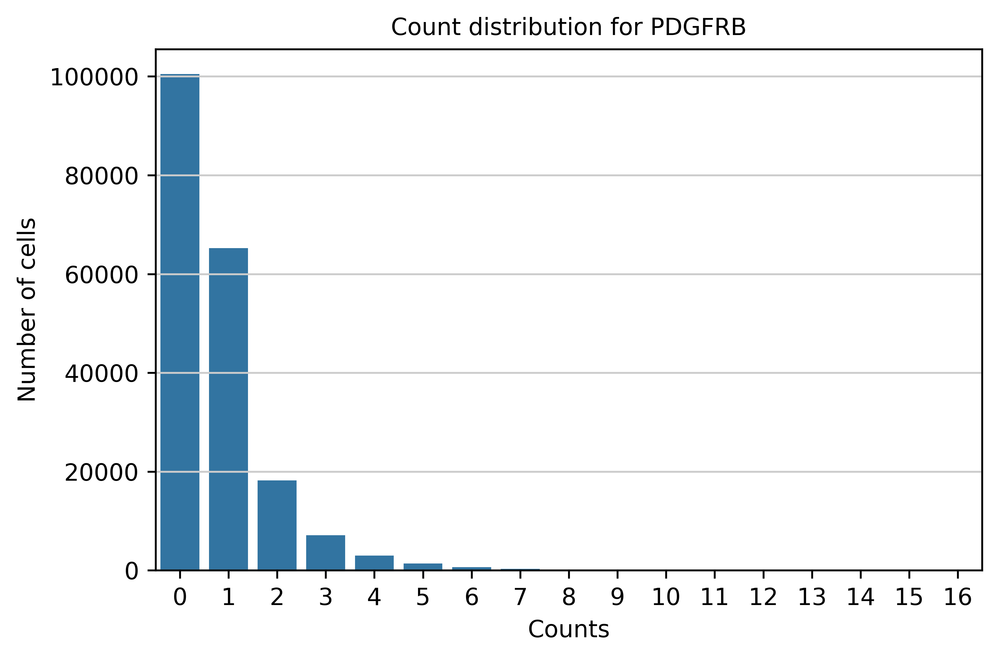

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


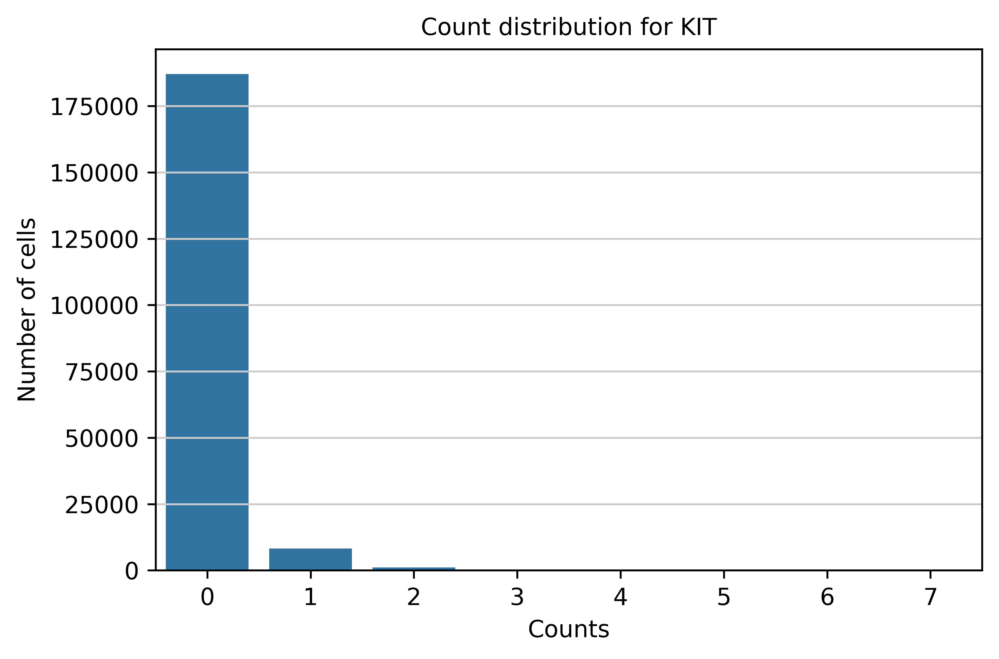

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


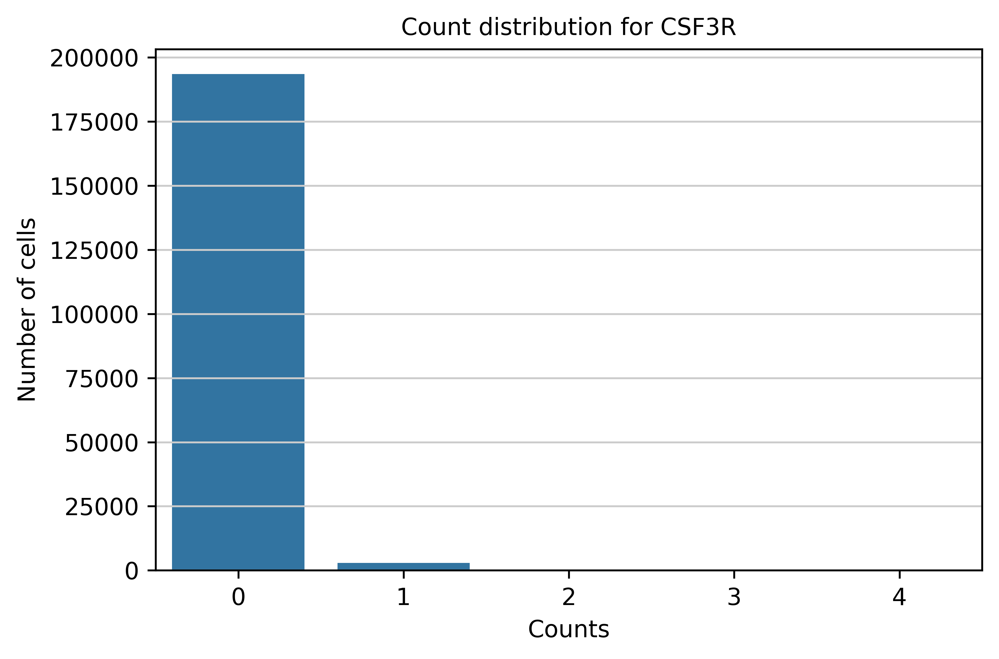

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


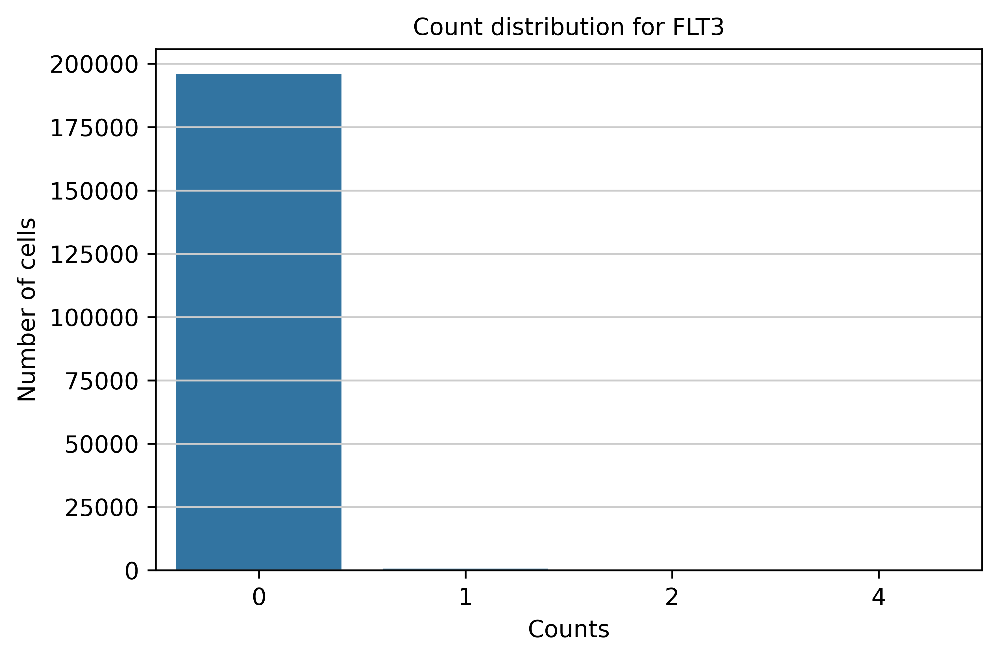

In [195]:
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].X
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

#### 2.5.3.2 Neighborhood Perturbations

In [196]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

Filter: 100%|██████████| 737081/737081 [00:30<00:00, 24352.48 examples/s]


In [197]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

737081


In [198]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

0.99929094
0.87521726


(array([1.00000e+00, 1.00000e+00, 4.00000e+00, 6.00000e+00, 1.70000e+01,
        7.30000e+01, 2.49000e+02, 1.22700e+03, 6.80600e+03, 7.28697e+05]),
 array([0.87521726, 0.88769555, 0.90017384, 0.91265213, 0.92513043,
        0.93760872, 0.95008707, 0.96256536, 0.97504365, 0.98752195,
        1.00000024]),
 <BarContainer object of 10 artists>)

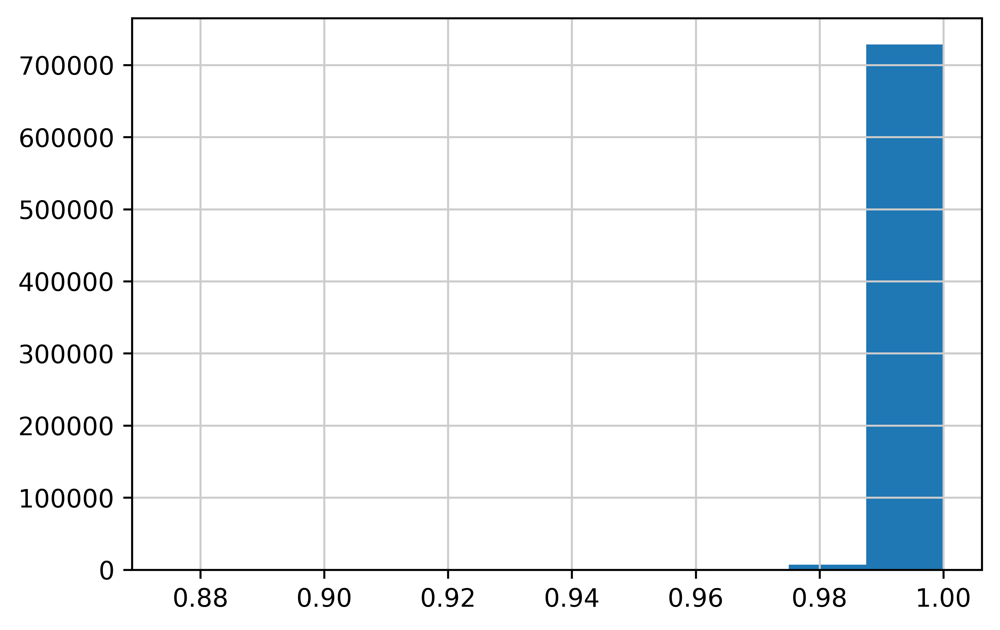

In [199]:
A = adata_sub_pert.obsm['cell_emb']
B = adata_sub_pert.obsm['cell_emb_perturb_case3']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(cell_emb_cos_sim))
print(np.min(cell_emb_cos_sim))
plt.hist(cell_emb_cos_sim)

0.9996346
0.9782121


(array([1.00000e+00, 1.00000e+01, 3.50000e+01, 1.06000e+02, 3.21000e+02,
        8.57000e+02, 2.17200e+03, 5.81300e+03, 1.92390e+04, 7.08527e+05]),
 array([0.97821212, 0.98039091, 0.98256969, 0.98474848, 0.98692727,
        0.98910606, 0.99128485, 0.99346364, 0.99564242, 0.99782121,
        1.        ]),
 <BarContainer object of 10 artists>)

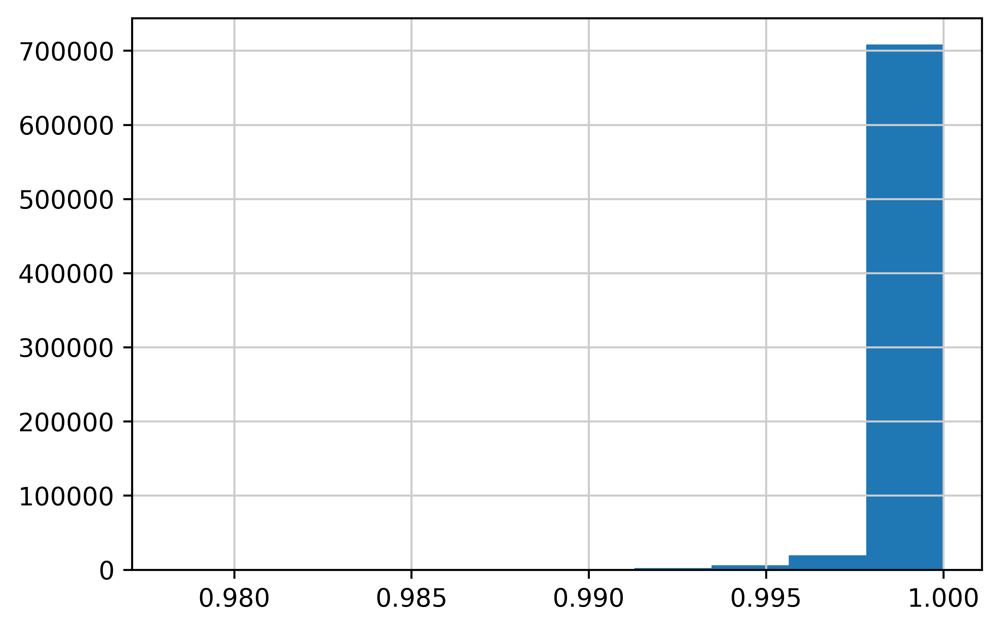

In [200]:
A = adata_sub_pert.obsm['spatial_cell_emb']
B = adata_sub_pert.obsm['spatial_cell_emb_perturb_case3']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

spatial_cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(spatial_cell_emb_cos_sim))
print(np.min(spatial_cell_emb_cos_sim))
plt.hist(spatial_cell_emb_cos_sim)

0.99969137
0.98037714


(array([4.00000e+00, 2.50000e+01, 5.20000e+01, 1.54000e+02, 4.00000e+02,
        9.47000e+02, 2.33700e+03, 5.72000e+03, 1.77000e+04, 7.09742e+05]),
 array([0.98037714, 0.98233944, 0.98430169, 0.98626399, 0.98822623,
        0.99018854, 0.99215084, 0.99411309, 0.99607539, 0.99803764,
        0.99999994]),
 <BarContainer object of 10 artists>)

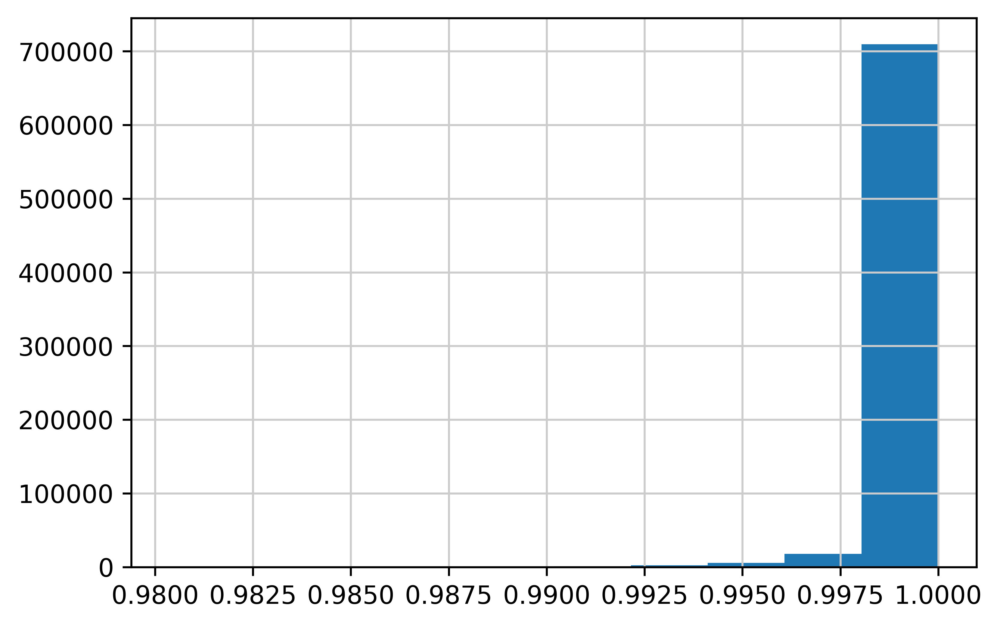

In [201]:
A = adata_sub_pert.obsm['neighborhood_emb']
B = adata_sub_pert.obsm['neighborhood_emb_perturb_case3']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

neighborhood_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(neighborhood_emb_cos_sim))
print(np.min(neighborhood_emb_cos_sim))
plt.hist(neighborhood_emb_cos_sim)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


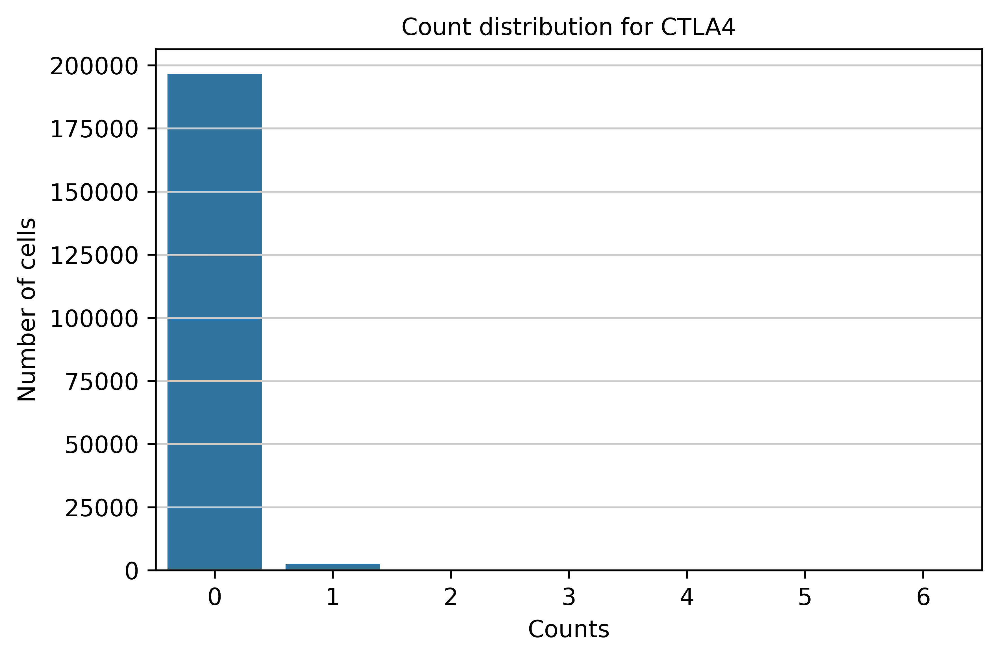

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


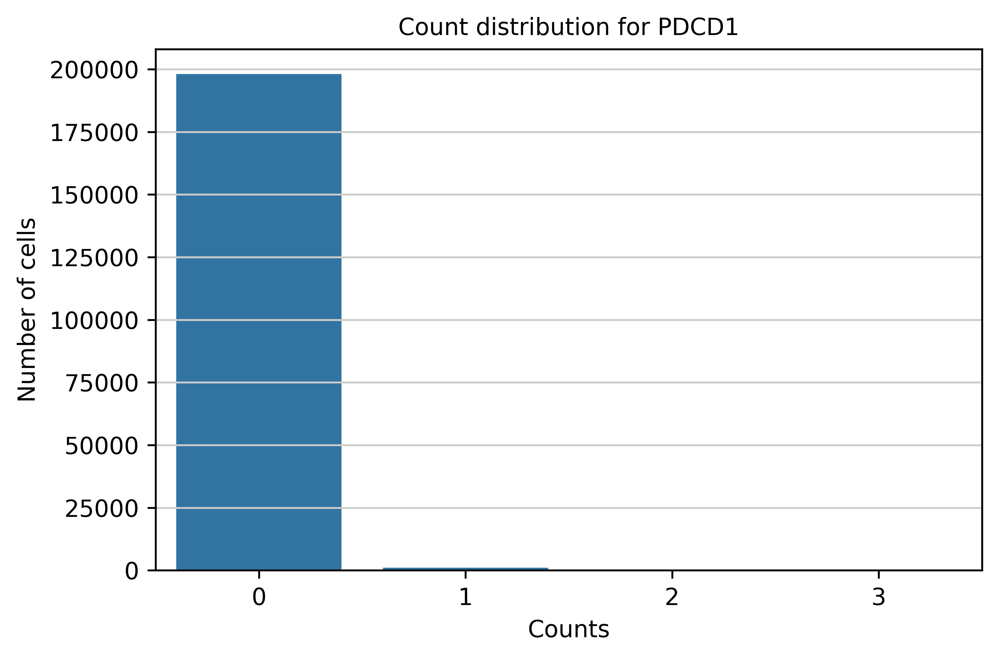

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


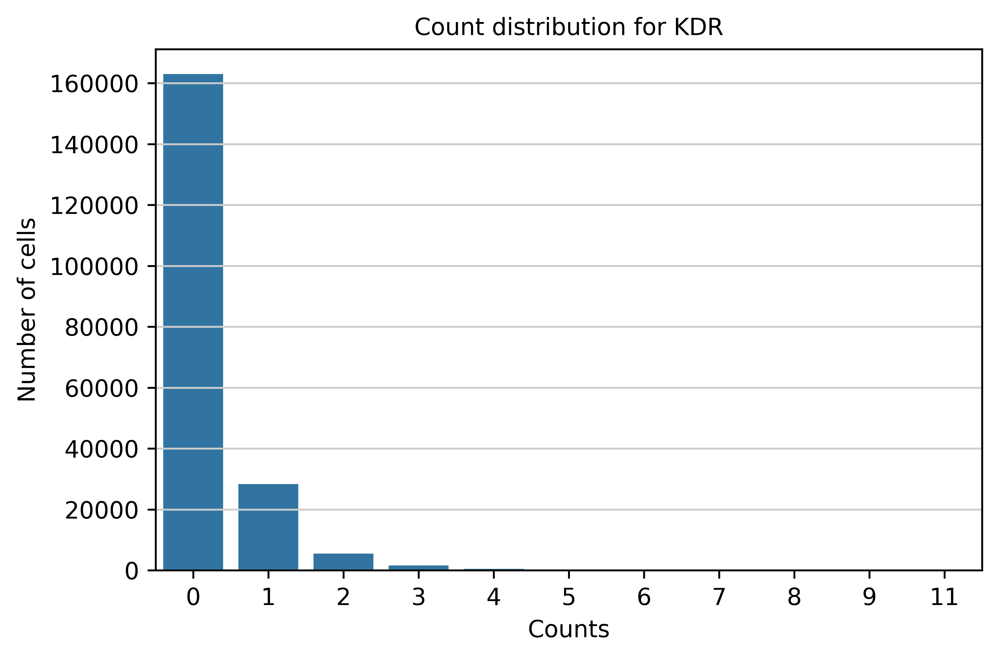

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


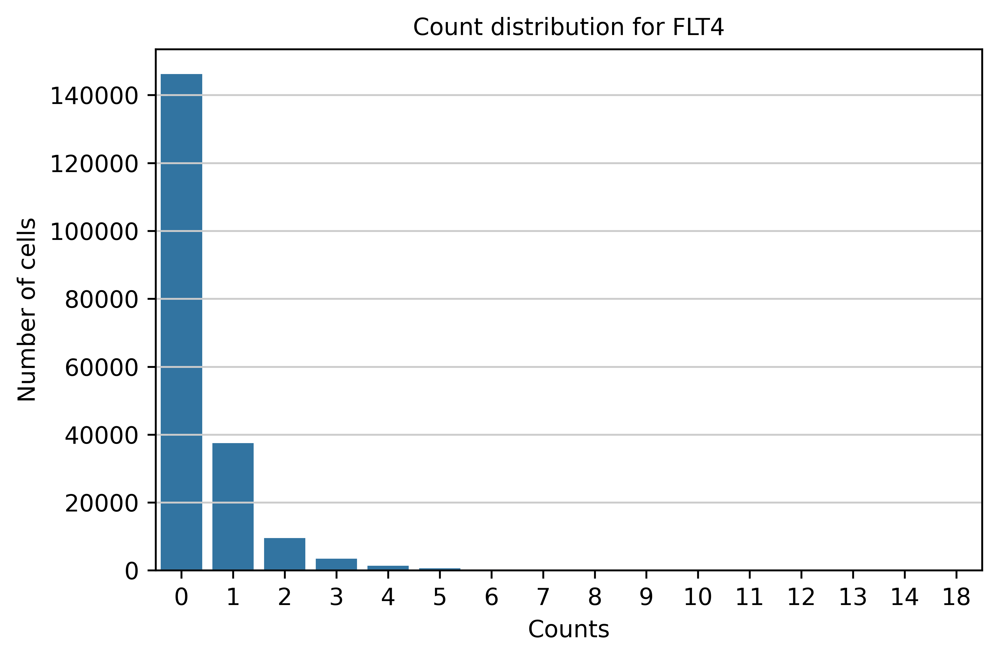

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


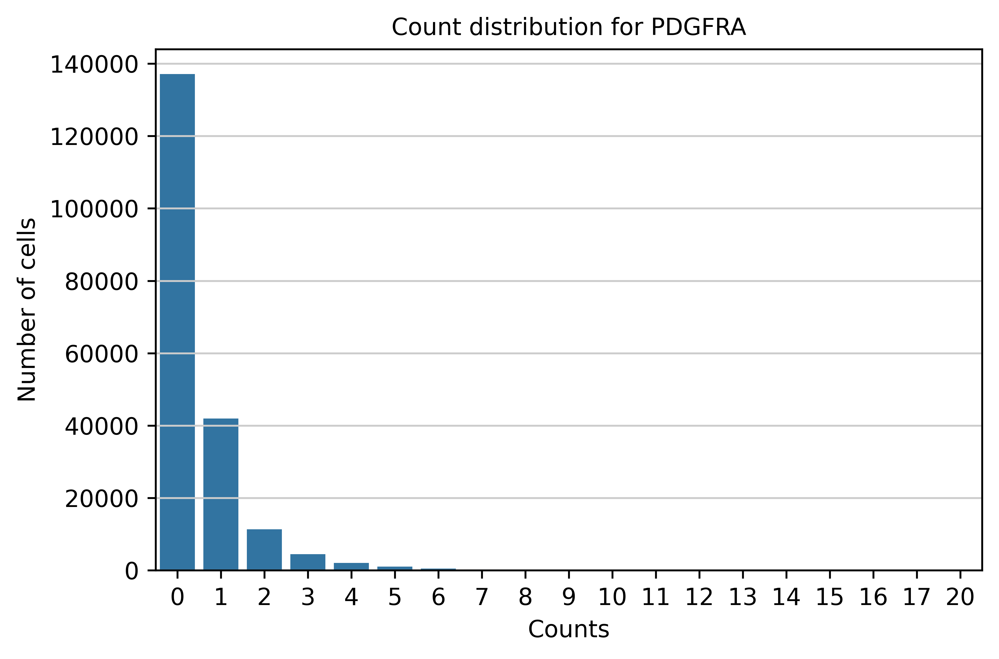

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


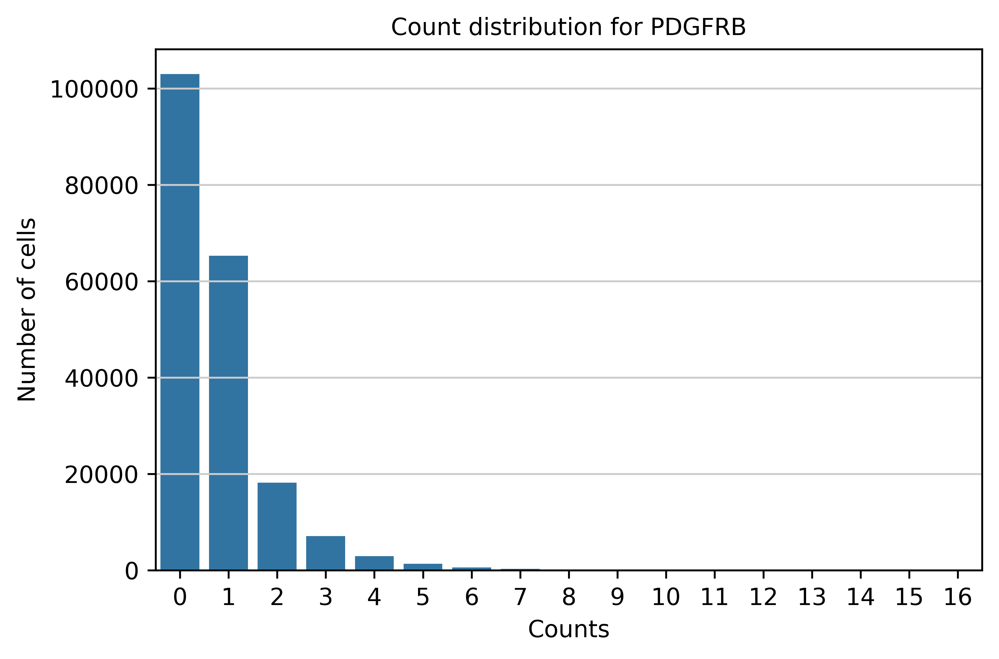

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


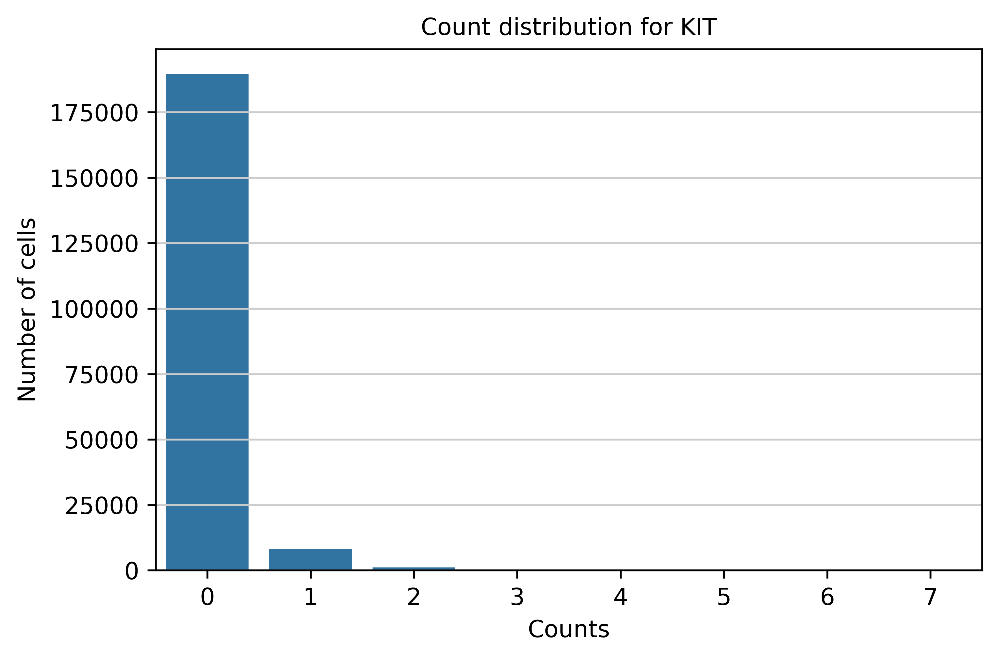

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


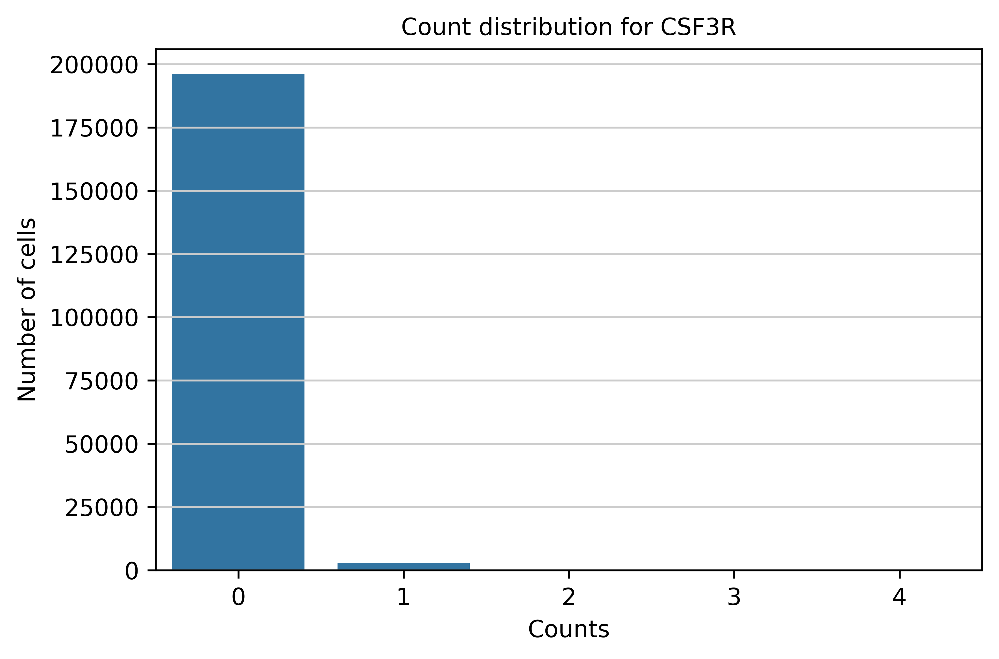

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


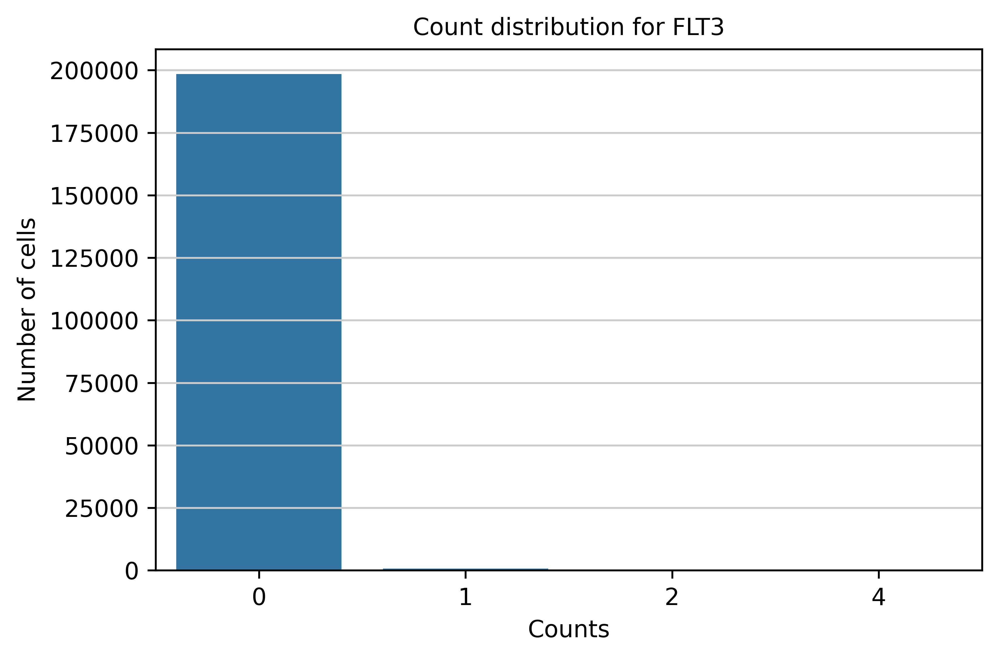

In [185]:
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].X
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

### 2.5.4 Perturbation Case 4

Knockout Perturbation:
- Top 10 differentially expressed genes with enough counts
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [202]:
pert_genes = [
    'MYH9',
    'CXCR4',
    'NR4A1',
    'THBS1',
    'PLEC',
    'EEF1G',
    'TUBB',
    'SEPTIN9',
    'SMAP2',
    'YWHAZ']

In [203]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

           ensembl_id  highly_variable  highly_variable_rank     means  \
MYH9  ENSG00000100345            False                   NaN  0.819873   

      variances  variances_norm  
MYH9   2.583143        0.694623  
            ensembl_id  highly_variable  highly_variable_rank     means  \
CXCR4  ENSG00000121966             True                  70.0  0.252166   

       variances  variances_norm  
CXCR4   0.968808        1.917838  
            ensembl_id  highly_variable  highly_variable_rank     means  \
NR4A1  ENSG00000123358             True                 192.0  0.953956   

       variances  variances_norm  
NR4A1   7.219805        1.456233  
            ensembl_id  highly_variable  highly_variable_rank     means  \
THBS1  ENSG00000137801             True                  91.0  0.326305   

       variances  variances_norm  
THBS1   1.332106        1.767337  
           ensembl_id  highly_variable  highly_variable_rank     means  \
PLEC  ENSG00000178209            False        

In [204]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case4")

FileNotFoundError: Directory /nfs/team361/sb75/DATASETS/gold/cell-graph-tokenizer/kidney_perturbation/tokenized_data/nemokidneyxeniumatlas_perturbed_case4 is neither a `Dataset` directory nor a `DatasetDict` directory.

#### 2.5.2.1 Cell Perturbations

In [189]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

Filter: 100%|██████████| 737081/737081 [01:57<00:00, 6299.47 examples/s]


In [190]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

196634


In [191]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

0.9973362
0.87521726


(array([1.00000e+00, 1.00000e+00, 4.00000e+00, 7.00000e+00, 1.70000e+01,
        7.30000e+01, 2.48000e+02, 1.23000e+03, 6.82900e+03, 1.88224e+05]),
 array([0.87521726, 0.88769531, 0.90017337, 0.91265142, 0.92512947,
        0.93760753, 0.95008552, 0.96256357, 0.97504163, 0.98751968,
        0.99999774]),
 <BarContainer object of 10 artists>)

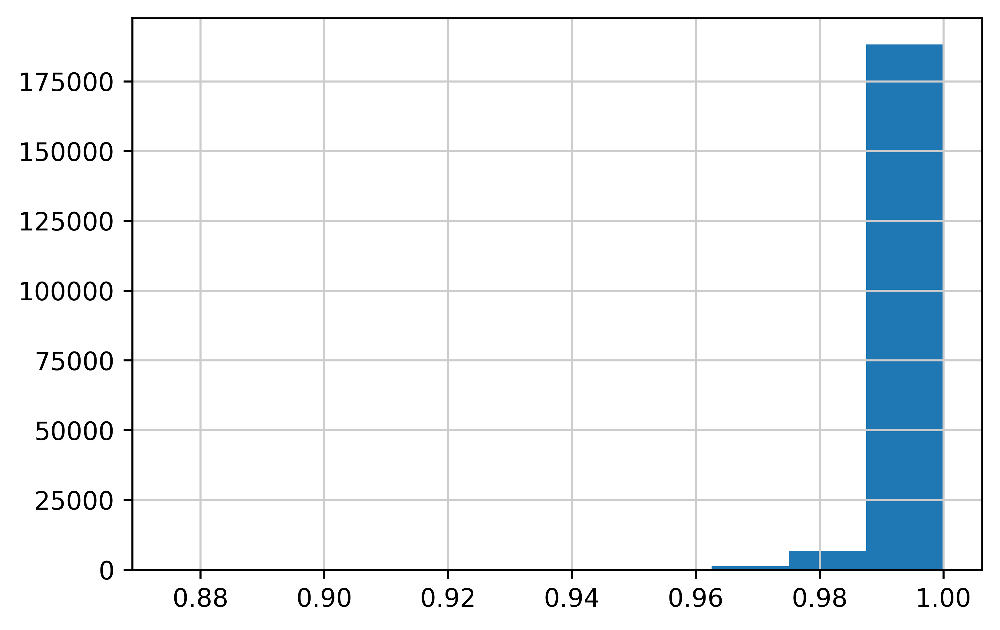

In [192]:
A = adata_sub_cell_pert.obsm['cell_emb']
B = adata_sub_cell_pert.obsm['cell_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(cell_emb_cos_sim))
print(np.min(cell_emb_cos_sim))
plt.hist(cell_emb_cos_sim)

0.9994669
0.98170245


(array([6.00000e+00, 8.00000e+00, 2.30000e+01, 6.70000e+01, 1.85000e+02,
        4.33000e+02, 1.02700e+03, 2.78600e+03, 9.01600e+03, 1.83083e+05]),
 array([0.98170245, 0.98353195, 0.9853614 , 0.9871909 , 0.98902035,
        0.99084985, 0.99267936, 0.9945088 , 0.99633831, 0.99816775,
        0.99999726]),
 <BarContainer object of 10 artists>)

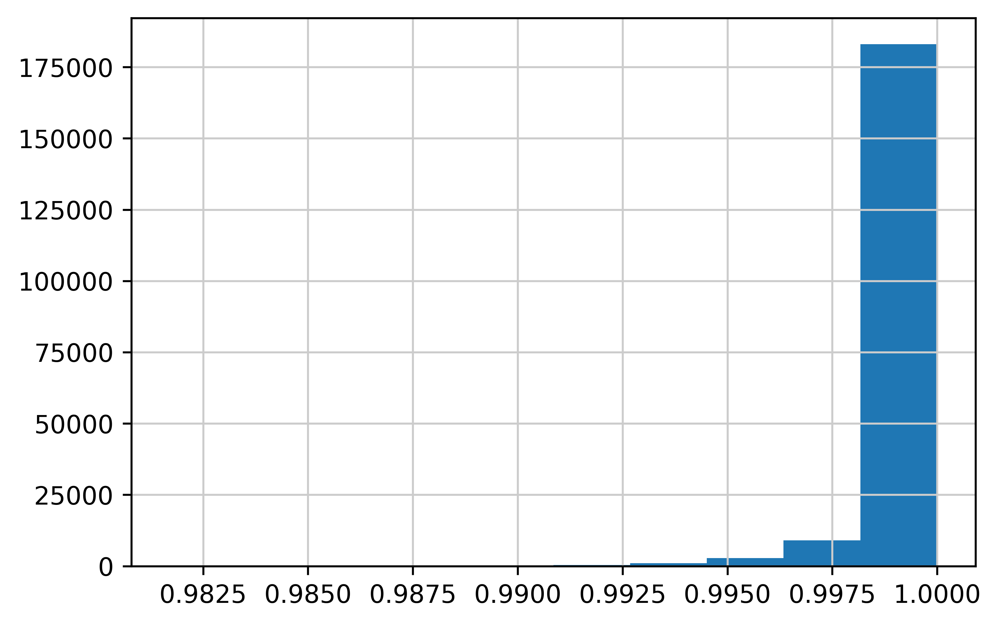

In [193]:
A = adata_sub_cell_pert.obsm['spatial_cell_emb']
B = adata_sub_cell_pert.obsm['spatial_cell_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

spatial_cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(spatial_cell_emb_cos_sim))
print(np.min(spatial_cell_emb_cos_sim))
plt.hist(spatial_cell_emb_cos_sim)

0.9995993
0.98163074


(array([6.00000e+00, 8.00000e+00, 2.30000e+01, 6.50000e+01, 1.58000e+02,
        4.04000e+02, 8.83000e+02, 2.21400e+03, 6.79500e+03, 1.86078e+05]),
 array([0.98163074, 0.98346764, 0.98530459, 0.98714149, 0.98897839,
        0.99081528, 0.99265224, 0.99448913, 0.99632603, 0.99816298,
        0.99999988]),
 <BarContainer object of 10 artists>)

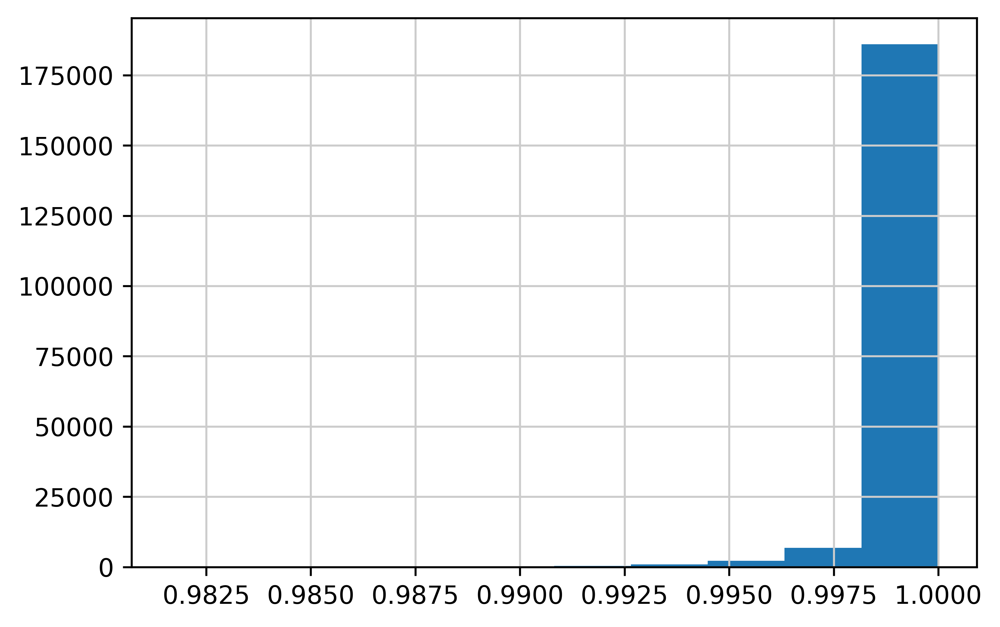

In [194]:
A = adata_sub_cell_pert.obsm['neighborhood_emb']
B = adata_sub_cell_pert.obsm['neighborhood_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

neighborhood_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(neighborhood_emb_cos_sim))
print(np.min(neighborhood_emb_cos_sim))
plt.hist(neighborhood_emb_cos_sim)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


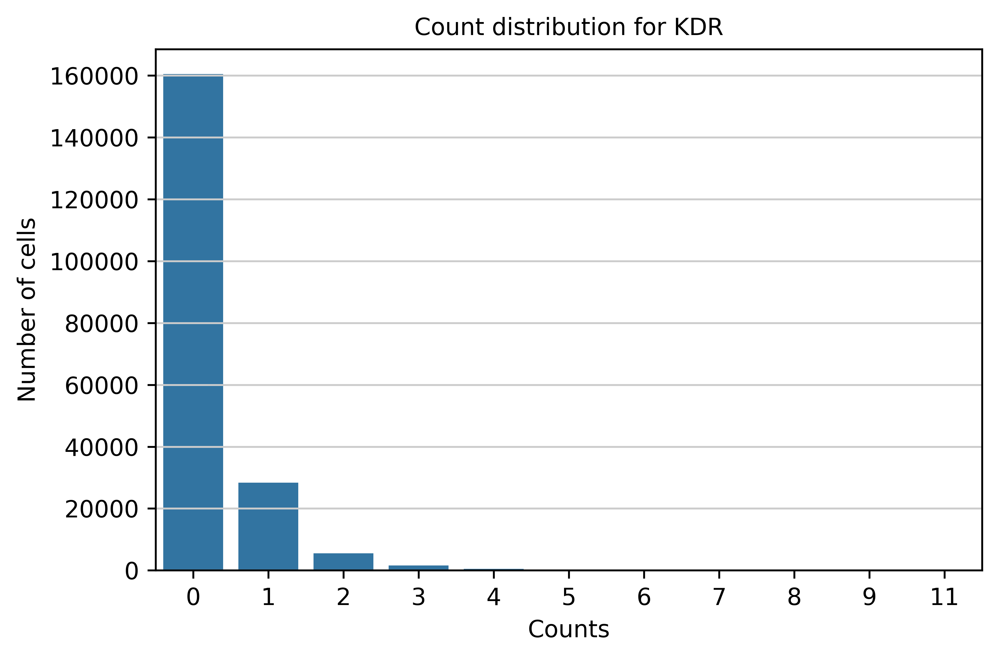

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


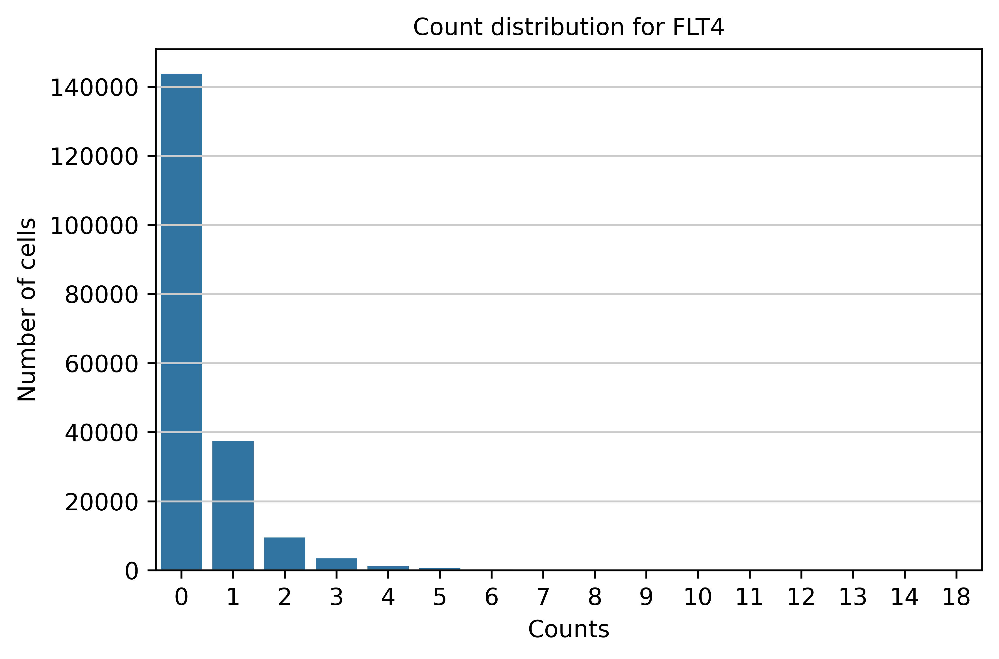

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


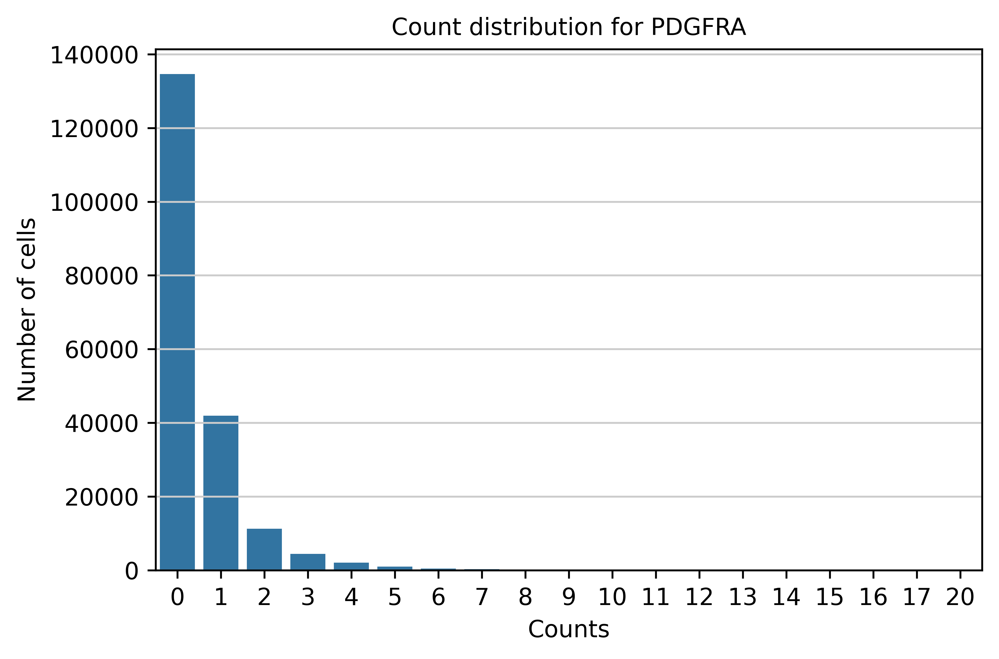

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


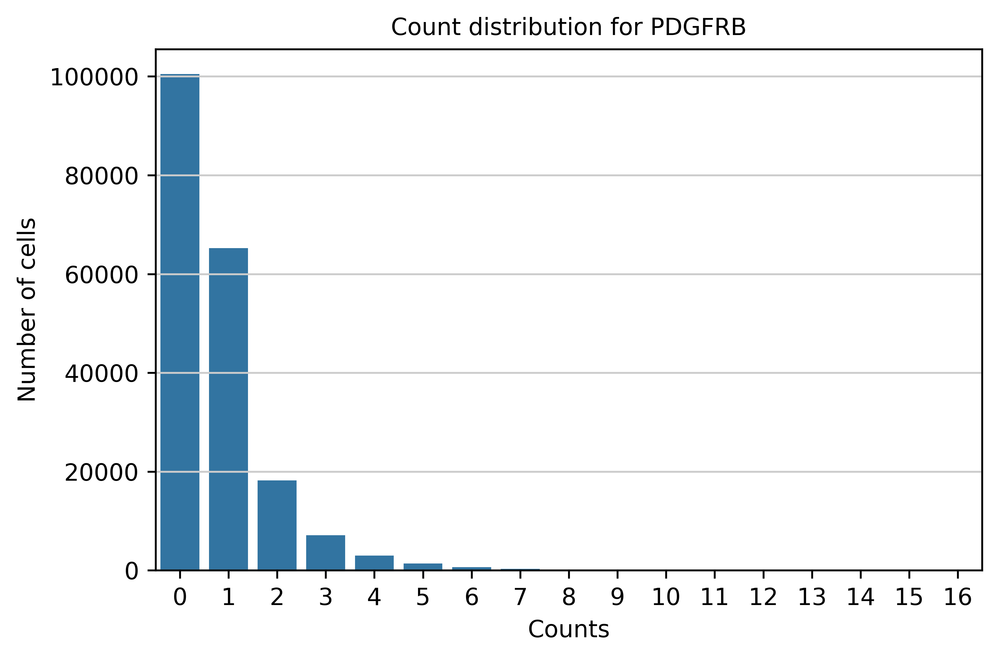

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


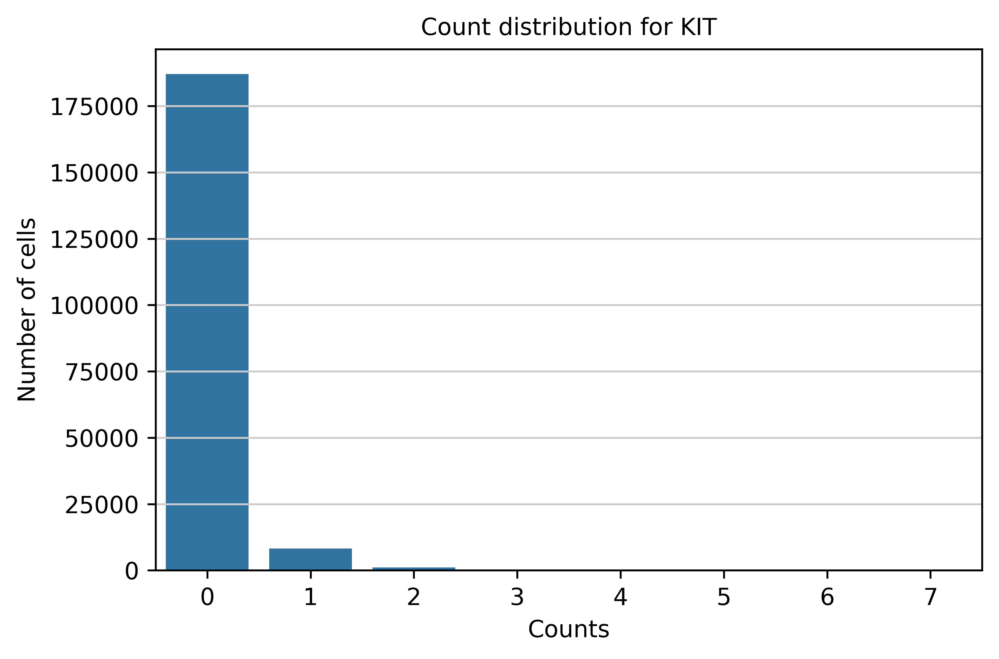

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


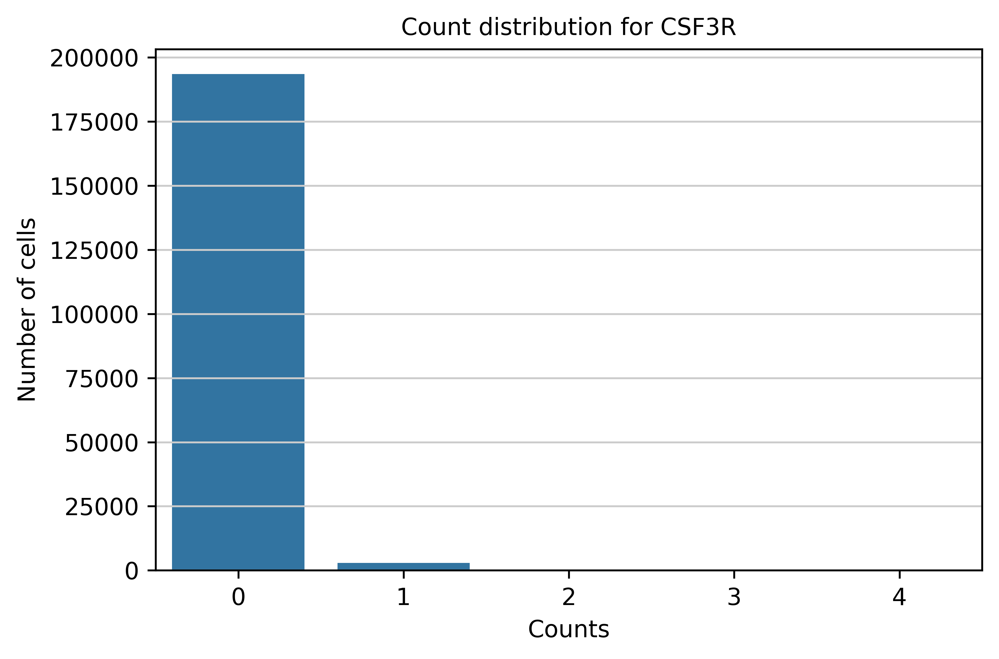

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


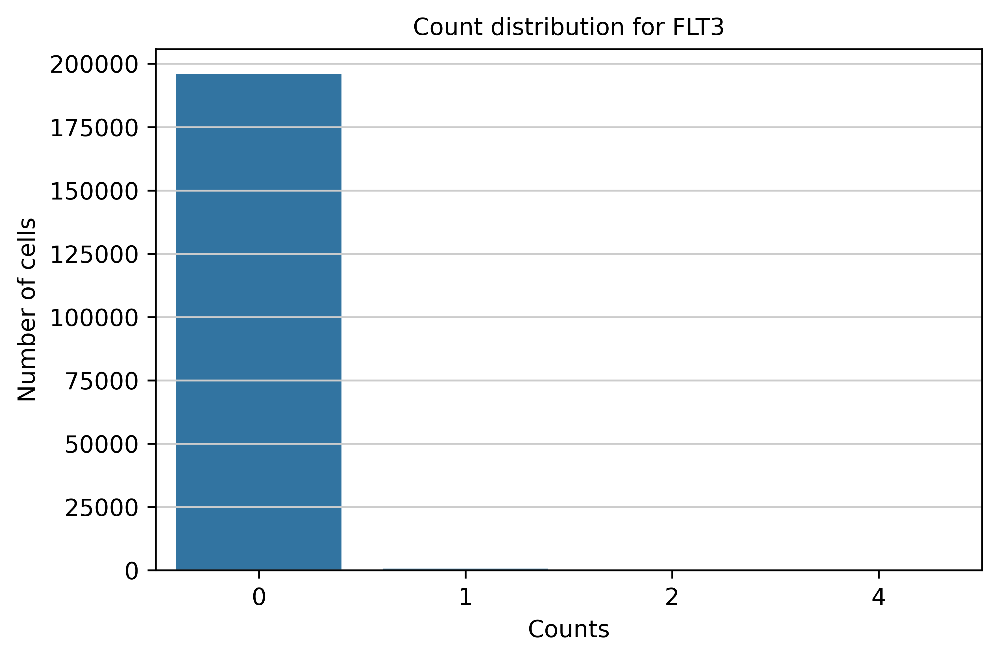

In [195]:
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].X
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

#### 2.5.2.2 Neighborhood Perturbations

In [196]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

Filter: 100%|██████████| 737081/737081 [00:30<00:00, 24352.48 examples/s]


In [197]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

737081


In [198]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

0.99929094
0.87521726


(array([1.00000e+00, 1.00000e+00, 4.00000e+00, 6.00000e+00, 1.70000e+01,
        7.30000e+01, 2.49000e+02, 1.22700e+03, 6.80600e+03, 7.28697e+05]),
 array([0.87521726, 0.88769555, 0.90017384, 0.91265213, 0.92513043,
        0.93760872, 0.95008707, 0.96256536, 0.97504365, 0.98752195,
        1.00000024]),
 <BarContainer object of 10 artists>)

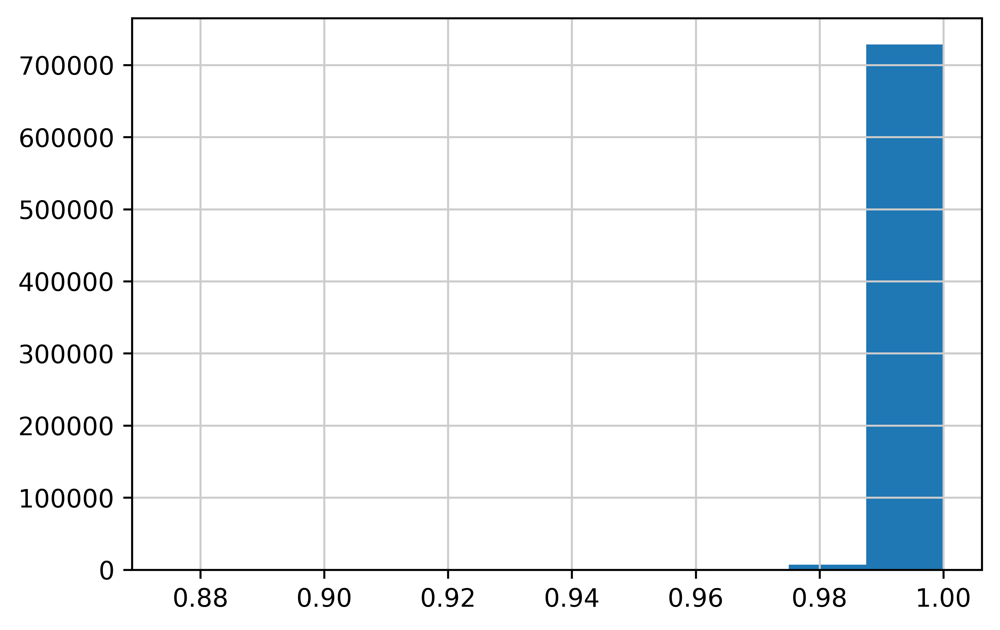

In [199]:
A = adata_sub_pert.obsm['cell_emb']
B = adata_sub_pert.obsm['cell_emb_perturb_case3']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(cell_emb_cos_sim))
print(np.min(cell_emb_cos_sim))
plt.hist(cell_emb_cos_sim)

In [ ]:
A = adata_sub_pert.obsm['spatial_cell_emb']
B = adata_sub_pert.obsm['spatial_cell_emb_perturb_case3']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

spatial_cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(spatial_cell_emb_cos_sim))
print(np.min(spatial_cell_emb_cos_sim))
plt.hist(spatial_cell_emb_cos_sim)

In [ ]:
A = adata_sub_pert.obsm['neighborhood_emb']
B = adata_sub_pert.obsm['neighborhood_emb_perturb_case3']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

neighborhood_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(neighborhood_emb_cos_sim))
print(np.min(neighborhood_emb_cos_sim))
plt.hist(neighborhood_emb_cos_sim)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


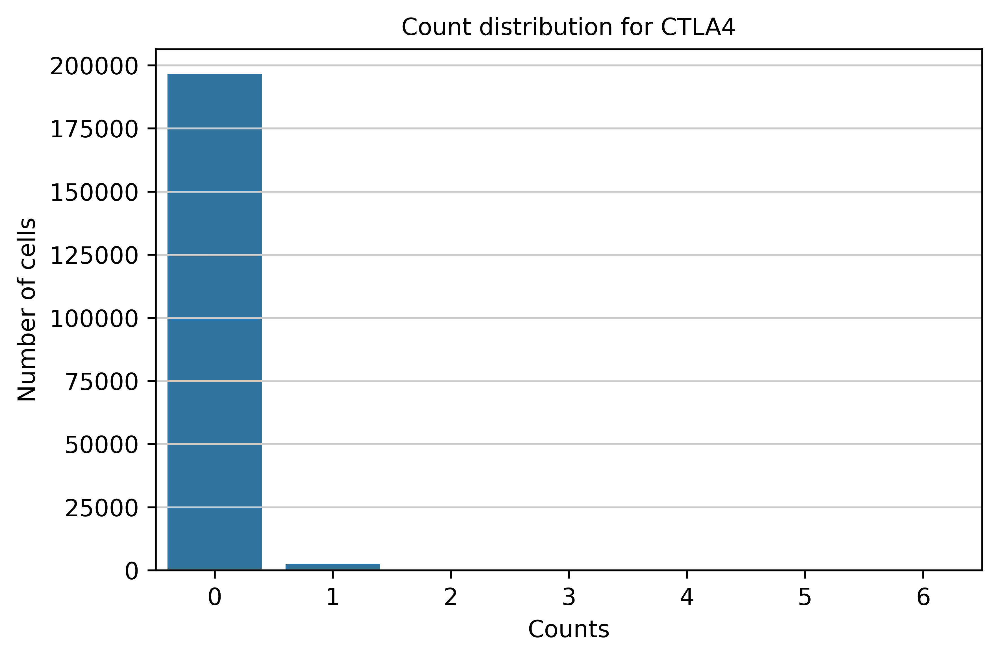

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


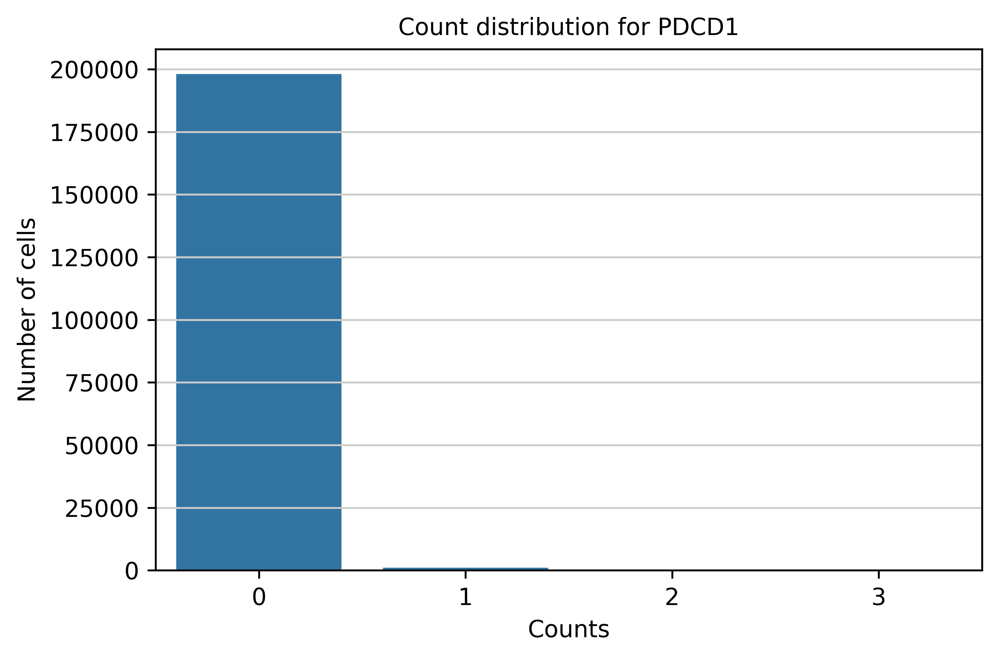

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


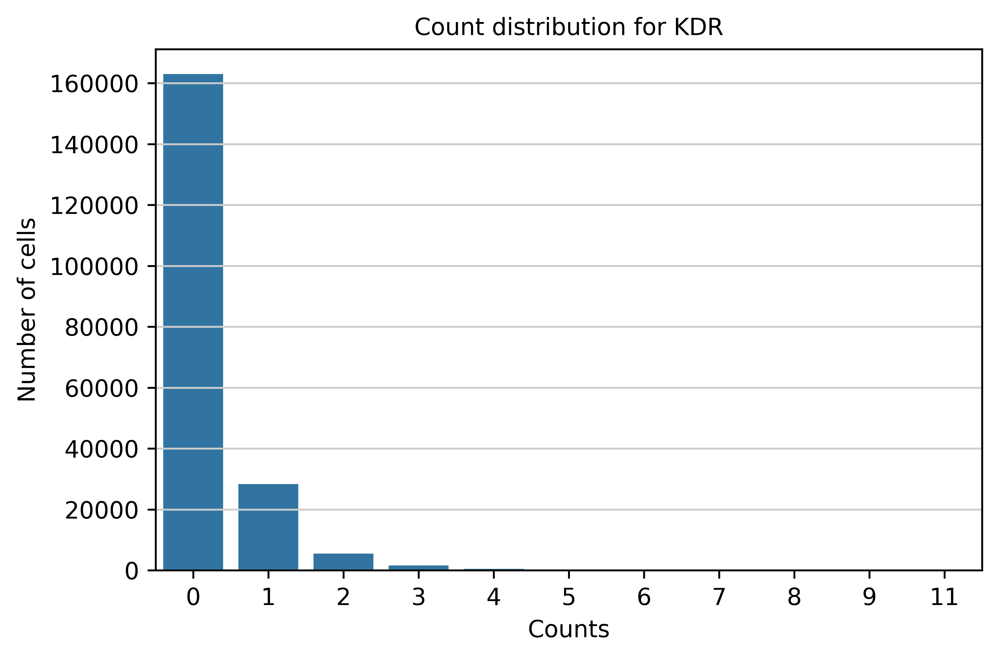

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


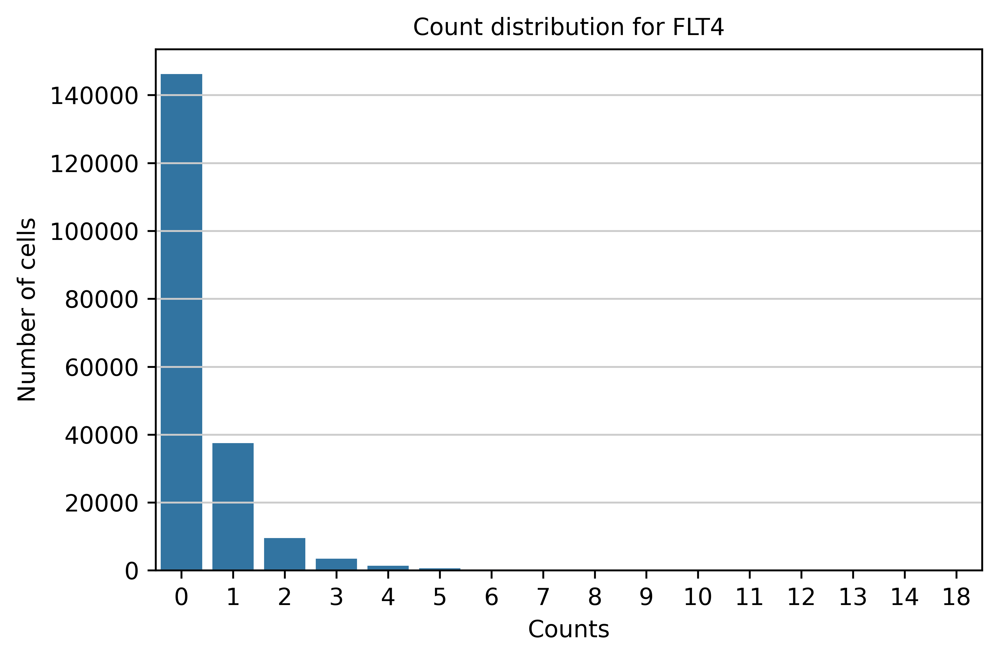

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


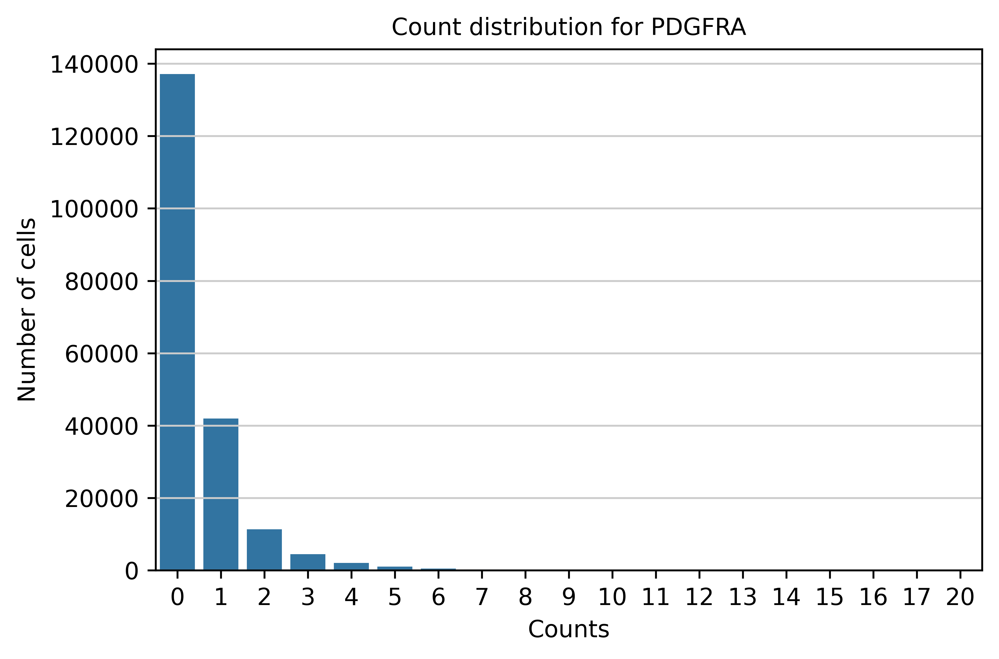

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


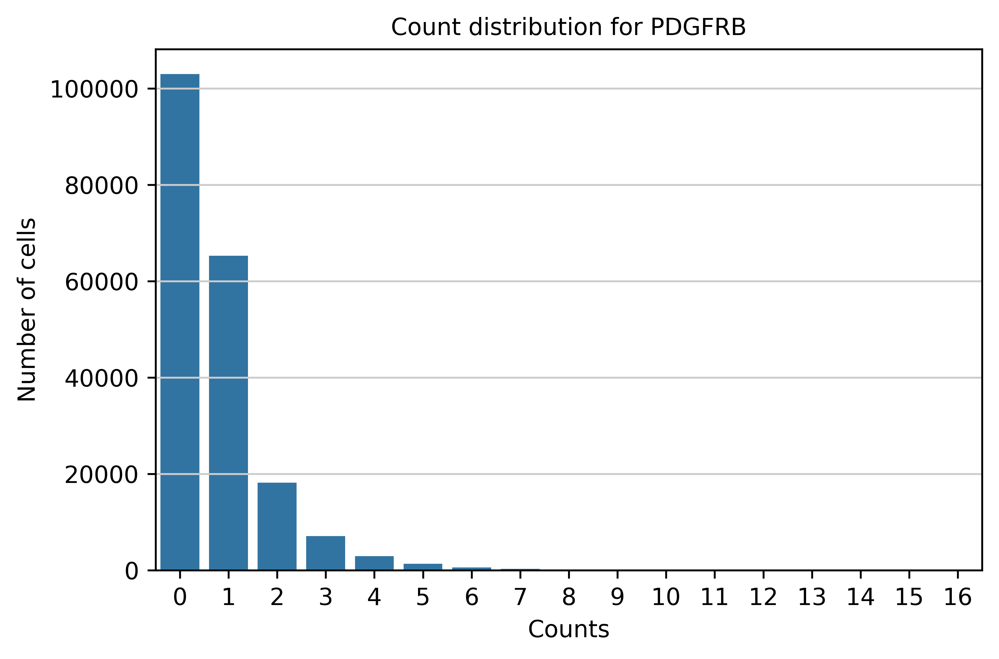

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


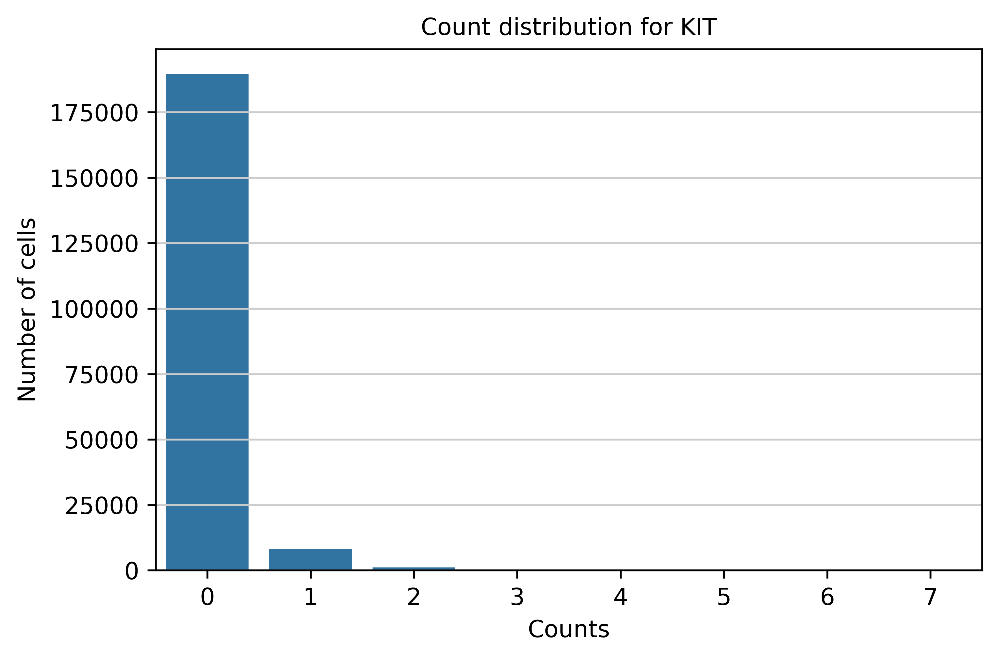

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


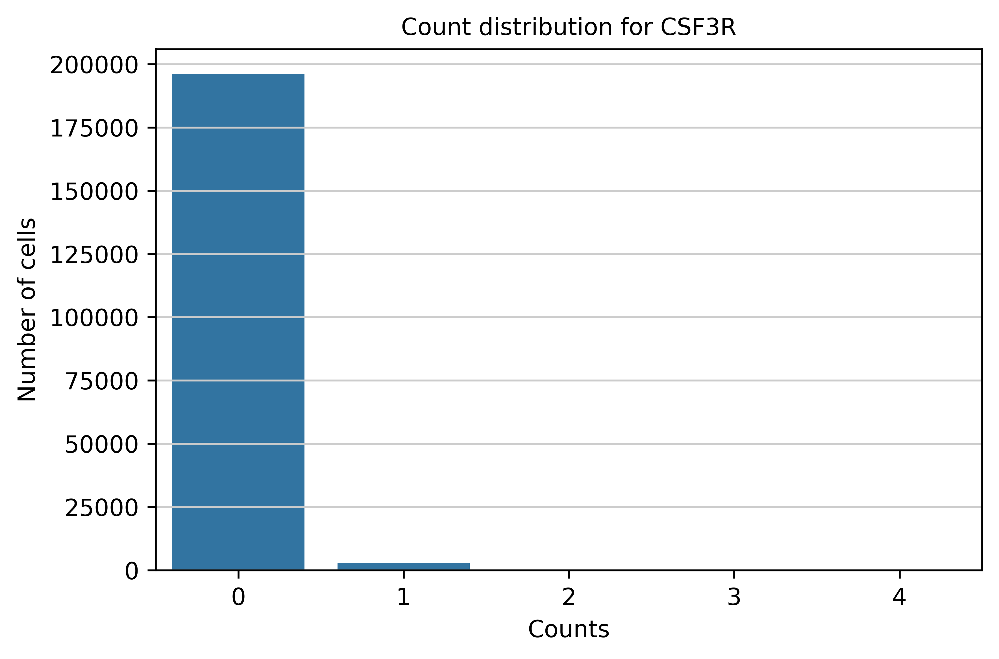

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


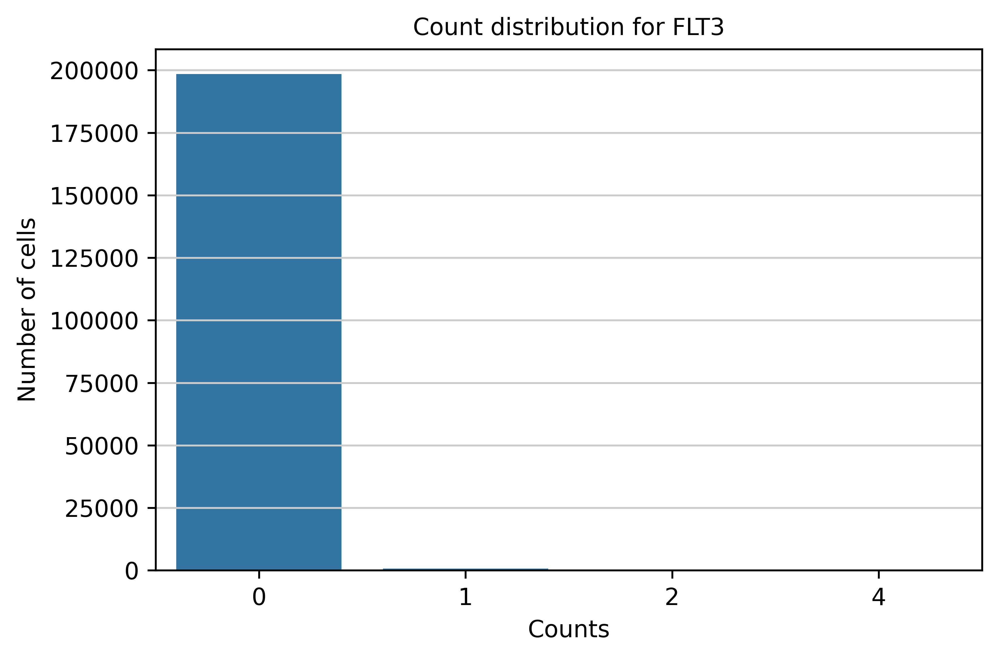

In [185]:
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].X
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

### 2.5.5 Perturbation Case 5

Knockout Perturbation:
- 10 housekeeping genes
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [205]:
pert_genes = [
    "HPRT1",
    "PGK1",
    "TBP",
    "NONO",
    "UBE2I",
    "YWHAZ",
    "SOD1",
    "GUSB",
    "RAN",
    "ATP5F1A",
]

In [206]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

            ensembl_id  highly_variable  highly_variable_rank     means  \
HPRT1  ENSG00000165704            False                   NaN  0.007568   

       variances  variances_norm  
HPRT1   0.007922        0.957873  
           ensembl_id  highly_variable  highly_variable_rank    means  \
PGK1  ENSG00000102144            False                   NaN  0.18462   

      variances  variances_norm  
PGK1   0.249603        0.780754  
          ensembl_id  highly_variable  highly_variable_rank     means  \
TBP  ENSG00000112592            False                   NaN  0.012415   

     variances  variances_norm  
TBP   0.012739        0.937518  
           ensembl_id  highly_variable  highly_variable_rank     means  \
NONO  ENSG00000147140            False                   NaN  0.179486   

      variances  variances_norm  
NONO   0.251883        0.820001  
            ensembl_id  highly_variable  highly_variable_rank     means  \
UBE2I  ENSG00000103275            False                   N

In [207]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case5")

FileNotFoundError: Directory /nfs/team361/sb75/DATASETS/gold/cell-graph-tokenizer/kidney_perturbation/tokenized_data/nemokidneyxeniumatlas_perturbed_case5 not found

#### 2.5.2.1 Cell Perturbations

In [189]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

Filter: 100%|██████████| 737081/737081 [01:57<00:00, 6299.47 examples/s]


In [190]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

196634


In [191]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

0.9973362
0.87521726


(array([1.00000e+00, 1.00000e+00, 4.00000e+00, 7.00000e+00, 1.70000e+01,
        7.30000e+01, 2.48000e+02, 1.23000e+03, 6.82900e+03, 1.88224e+05]),
 array([0.87521726, 0.88769531, 0.90017337, 0.91265142, 0.92512947,
        0.93760753, 0.95008552, 0.96256357, 0.97504163, 0.98751968,
        0.99999774]),
 <BarContainer object of 10 artists>)

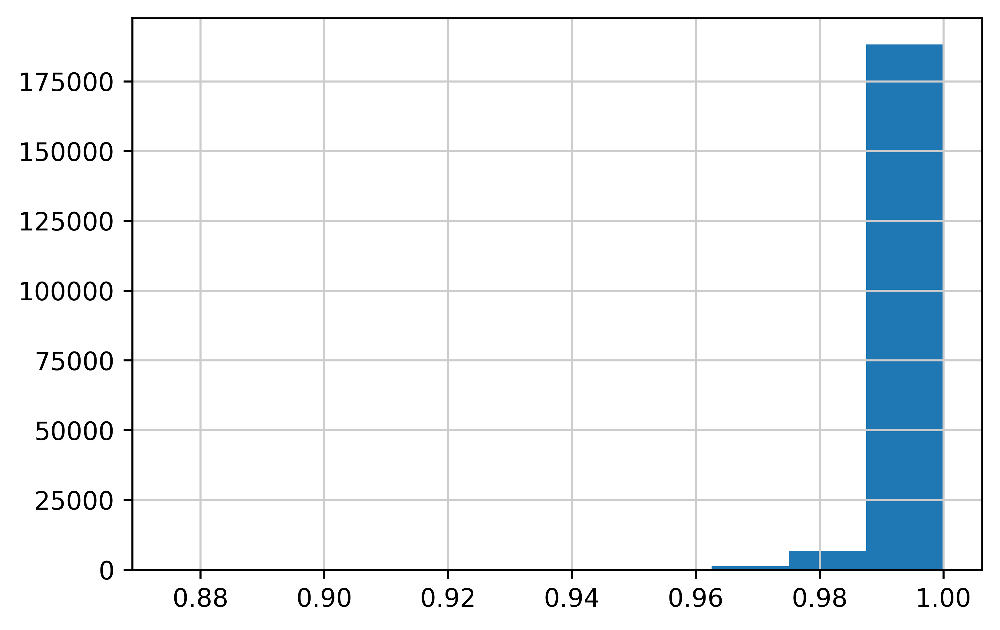

In [192]:
A = adata_sub_cell_pert.obsm['cell_emb']
B = adata_sub_cell_pert.obsm['cell_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(cell_emb_cos_sim))
print(np.min(cell_emb_cos_sim))
plt.hist(cell_emb_cos_sim)

0.9994669
0.98170245


(array([6.00000e+00, 8.00000e+00, 2.30000e+01, 6.70000e+01, 1.85000e+02,
        4.33000e+02, 1.02700e+03, 2.78600e+03, 9.01600e+03, 1.83083e+05]),
 array([0.98170245, 0.98353195, 0.9853614 , 0.9871909 , 0.98902035,
        0.99084985, 0.99267936, 0.9945088 , 0.99633831, 0.99816775,
        0.99999726]),
 <BarContainer object of 10 artists>)

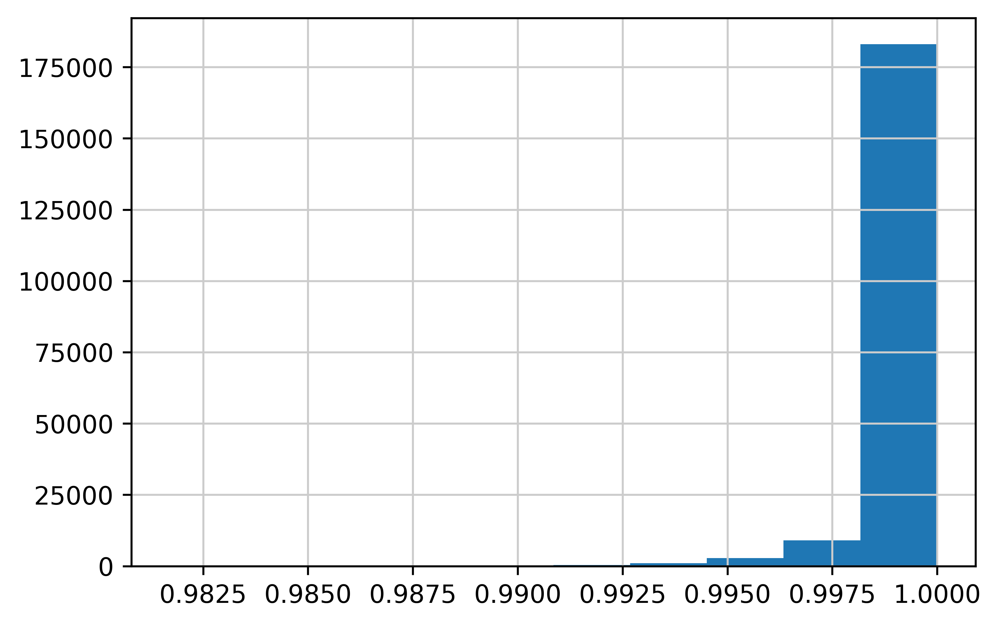

In [193]:
A = adata_sub_cell_pert.obsm['spatial_cell_emb']
B = adata_sub_cell_pert.obsm['spatial_cell_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

spatial_cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(spatial_cell_emb_cos_sim))
print(np.min(spatial_cell_emb_cos_sim))
plt.hist(spatial_cell_emb_cos_sim)

0.9995993
0.98163074


(array([6.00000e+00, 8.00000e+00, 2.30000e+01, 6.50000e+01, 1.58000e+02,
        4.04000e+02, 8.83000e+02, 2.21400e+03, 6.79500e+03, 1.86078e+05]),
 array([0.98163074, 0.98346764, 0.98530459, 0.98714149, 0.98897839,
        0.99081528, 0.99265224, 0.99448913, 0.99632603, 0.99816298,
        0.99999988]),
 <BarContainer object of 10 artists>)

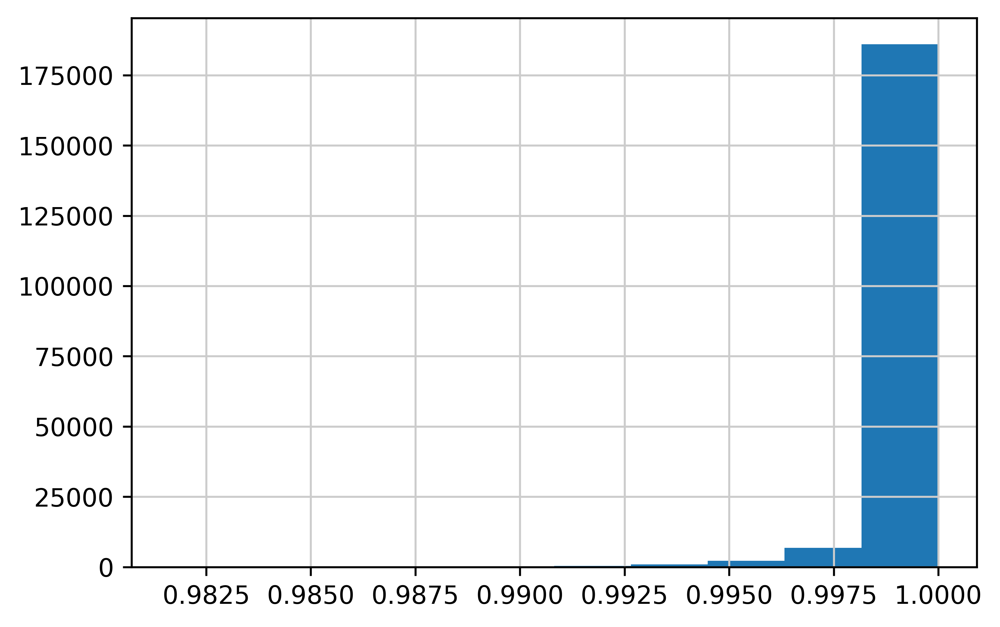

In [194]:
A = adata_sub_cell_pert.obsm['neighborhood_emb']
B = adata_sub_cell_pert.obsm['neighborhood_emb_perturb_case2']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

neighborhood_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(neighborhood_emb_cos_sim))
print(np.min(neighborhood_emb_cos_sim))
plt.hist(neighborhood_emb_cos_sim)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


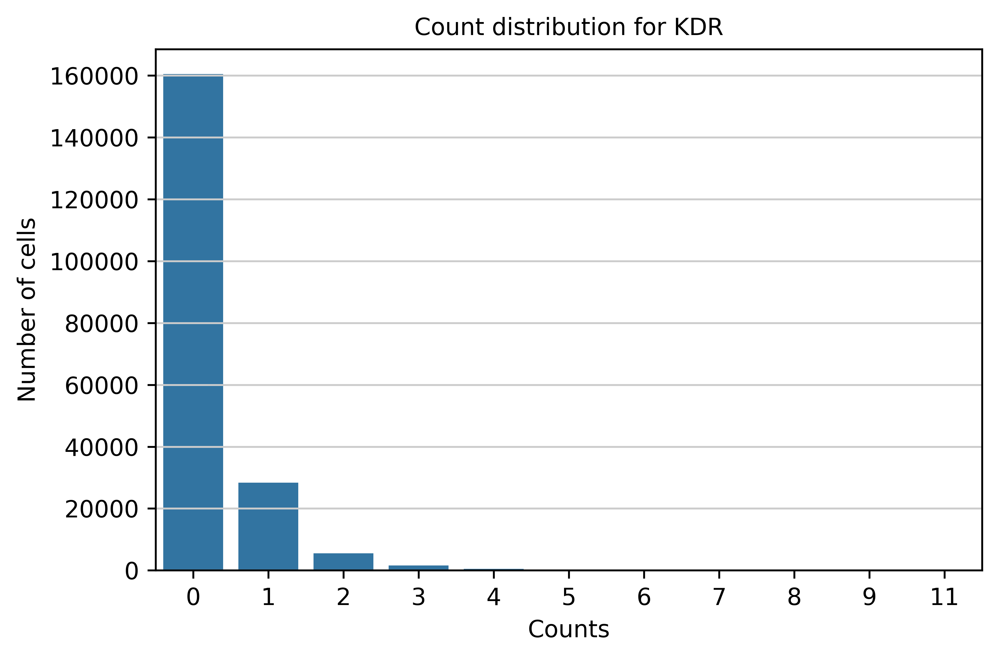

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


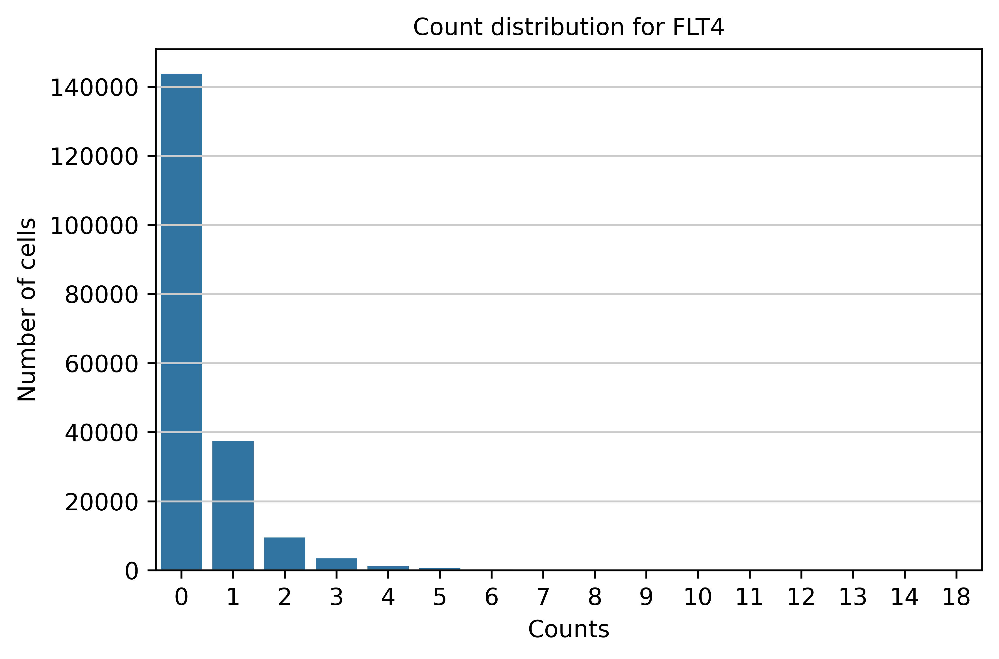

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


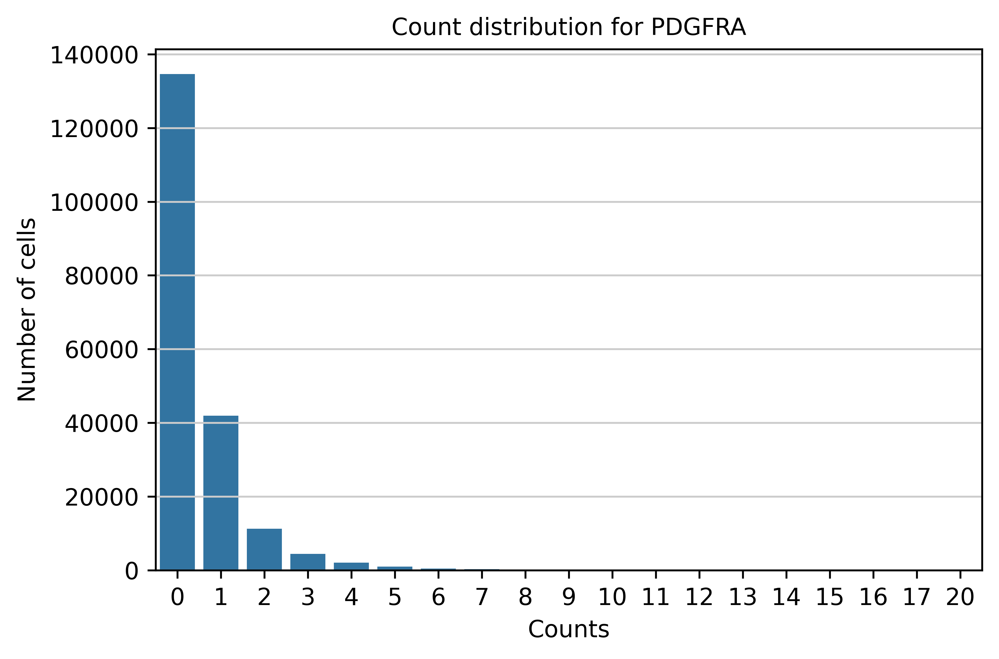

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


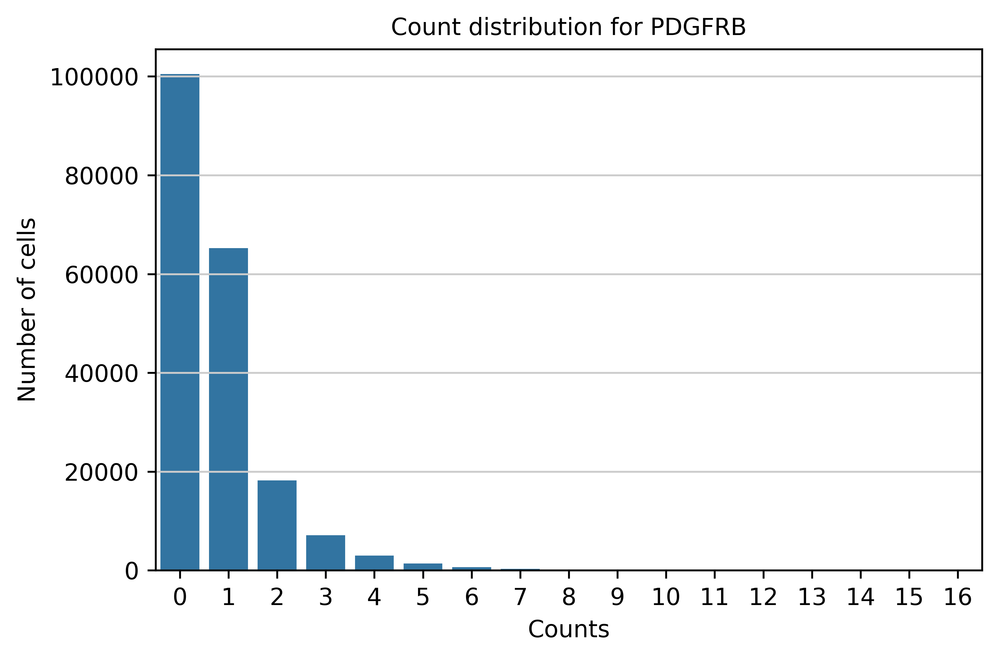

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


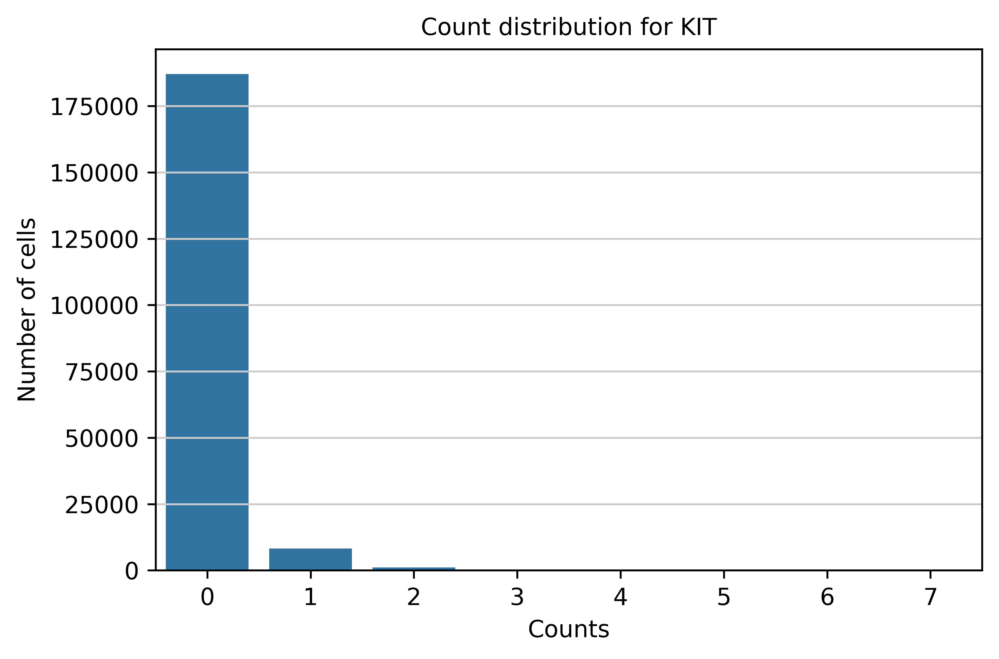

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


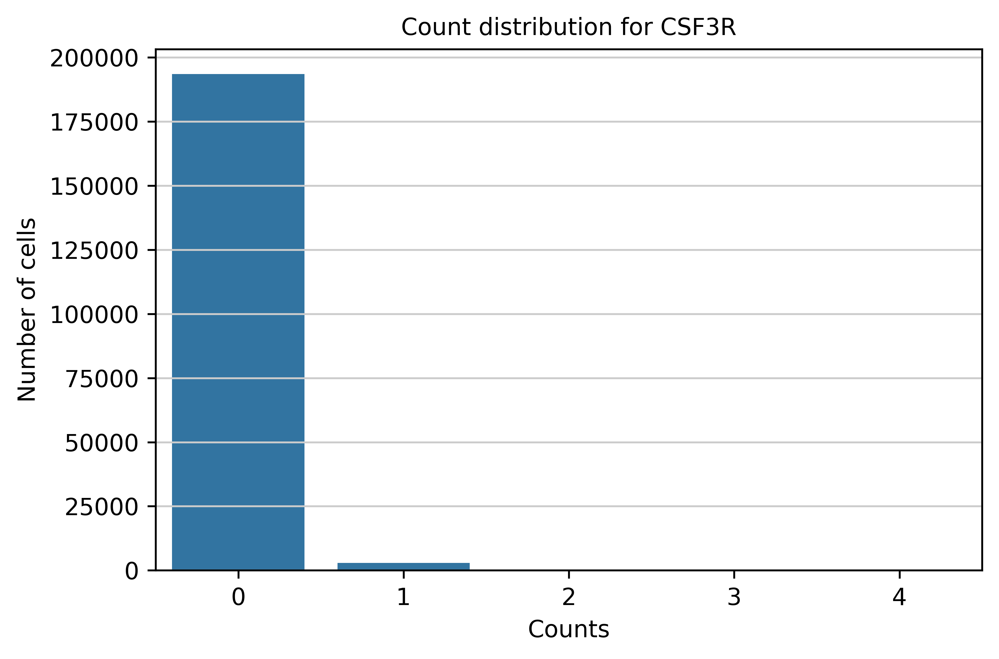

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


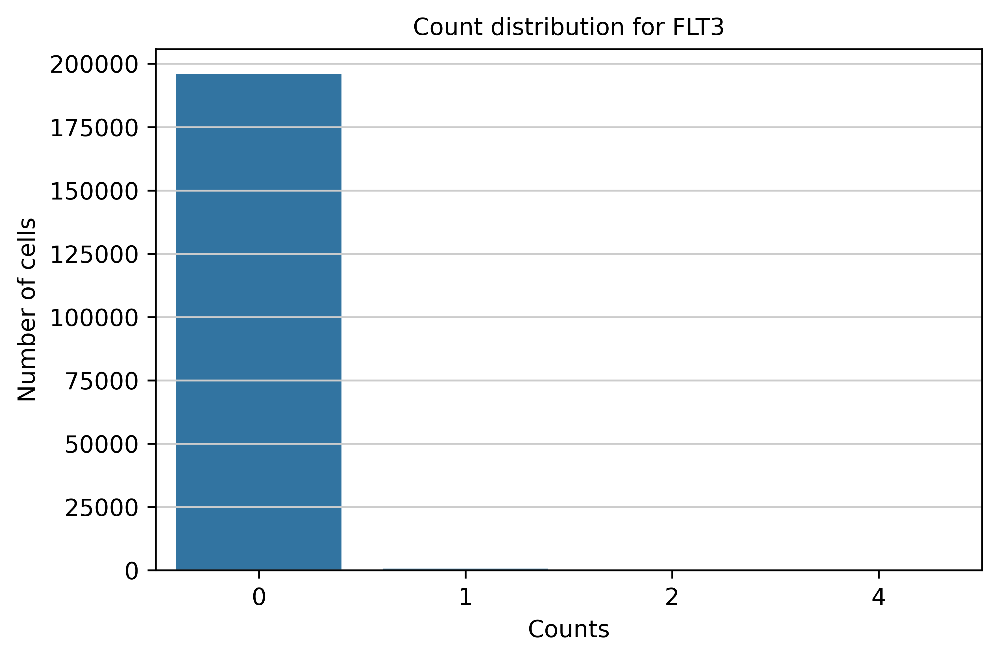

In [195]:
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].X
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

#### 2.5.2.2 Neighborhood Perturbations

In [196]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

Filter: 100%|██████████| 737081/737081 [00:30<00:00, 24352.48 examples/s]


In [197]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

737081


In [198]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

0.99929094
0.87521726


(array([1.00000e+00, 1.00000e+00, 4.00000e+00, 6.00000e+00, 1.70000e+01,
        7.30000e+01, 2.49000e+02, 1.22700e+03, 6.80600e+03, 7.28697e+05]),
 array([0.87521726, 0.88769555, 0.90017384, 0.91265213, 0.92513043,
        0.93760872, 0.95008707, 0.96256536, 0.97504365, 0.98752195,
        1.00000024]),
 <BarContainer object of 10 artists>)

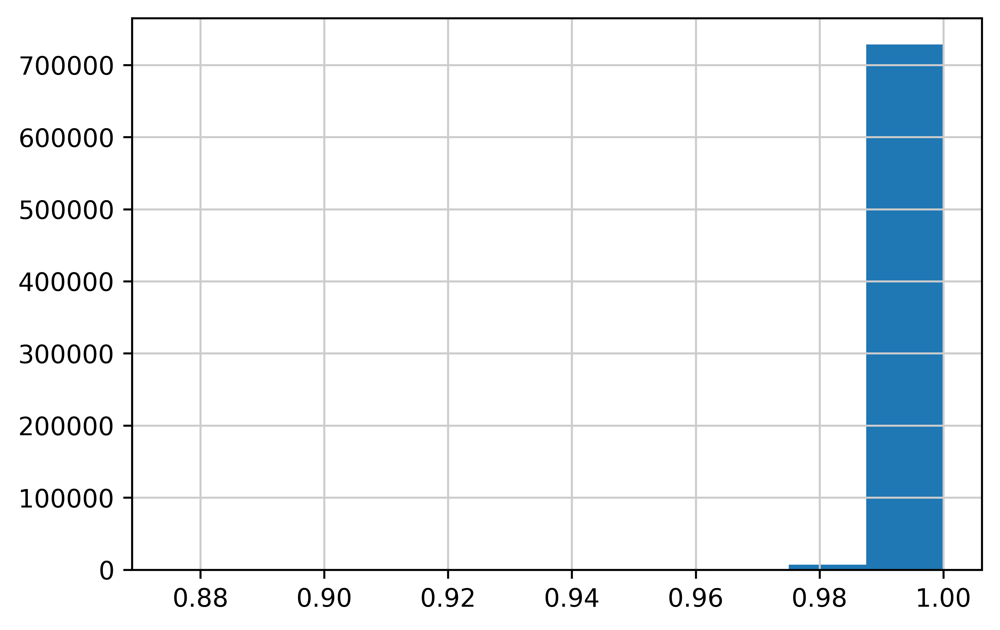

In [199]:
A = adata_sub_pert.obsm['cell_emb']
B = adata_sub_pert.obsm['cell_emb_perturb_case3']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(cell_emb_cos_sim))
print(np.min(cell_emb_cos_sim))
plt.hist(cell_emb_cos_sim)

In [ ]:
A = adata_sub_pert.obsm['spatial_cell_emb']
B = adata_sub_pert.obsm['spatial_cell_emb_perturb_case3']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

spatial_cell_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(spatial_cell_emb_cos_sim))
print(np.min(spatial_cell_emb_cos_sim))
plt.hist(spatial_cell_emb_cos_sim)

In [ ]:
A = adata_sub_pert.obsm['neighborhood_emb']
B = adata_sub_pert.obsm['neighborhood_emb_perturb_case3']

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

neighborhood_emb_cos_sim = np.sum(A_norm * B_norm, axis=1)
print(np.mean(neighborhood_emb_cos_sim))
print(np.min(neighborhood_emb_cos_sim))
plt.hist(neighborhood_emb_cos_sim)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


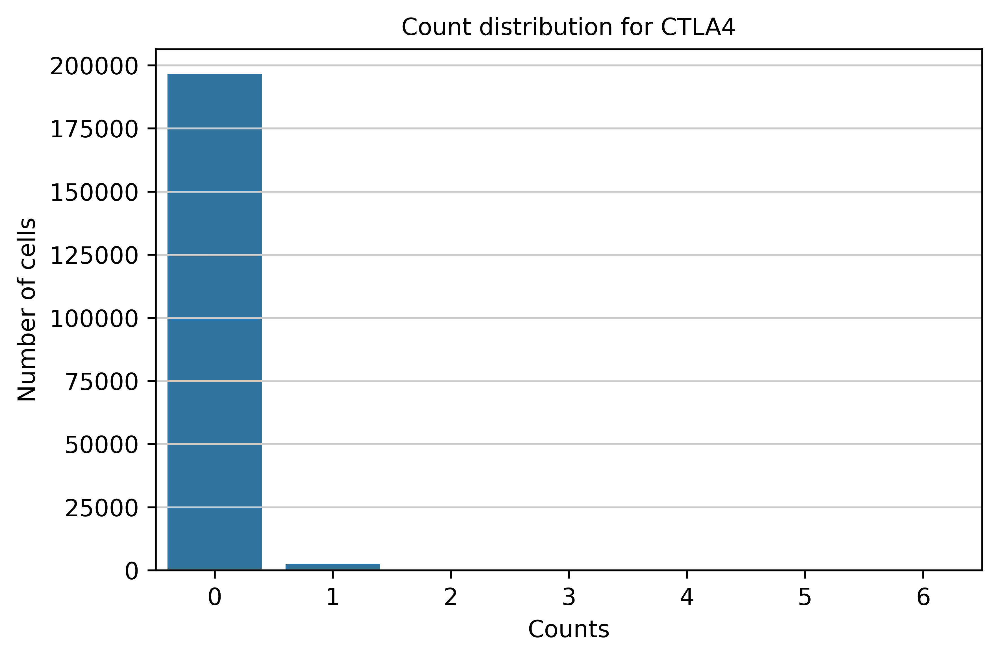

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


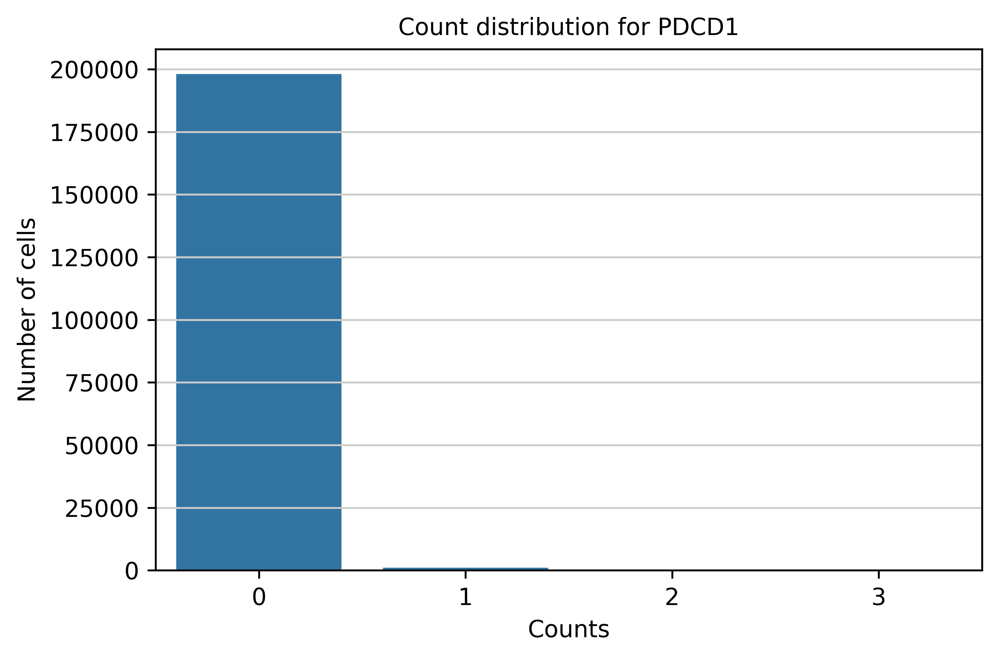

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


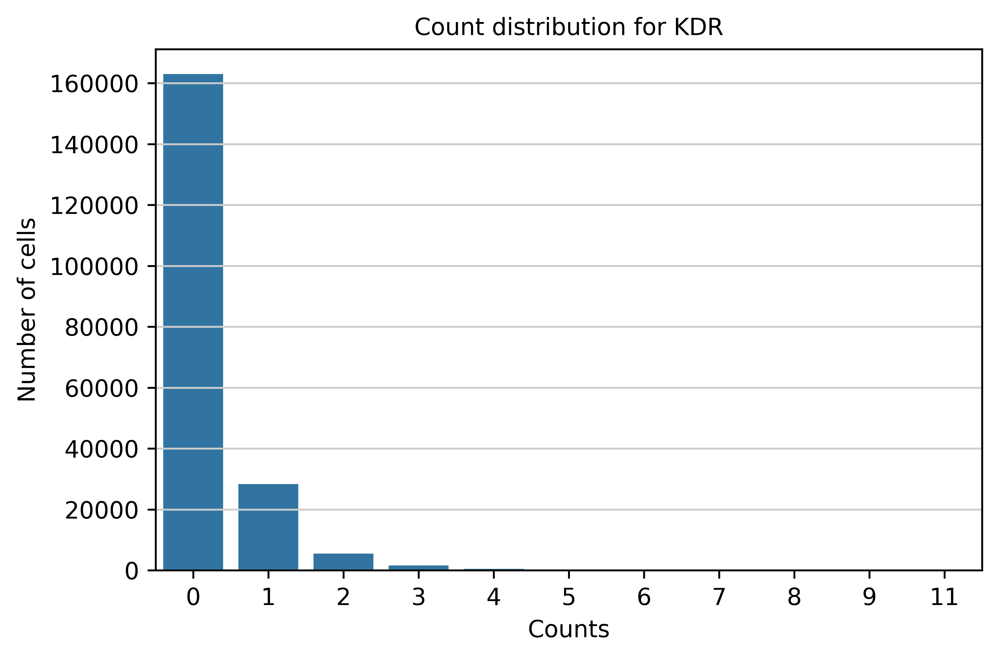

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


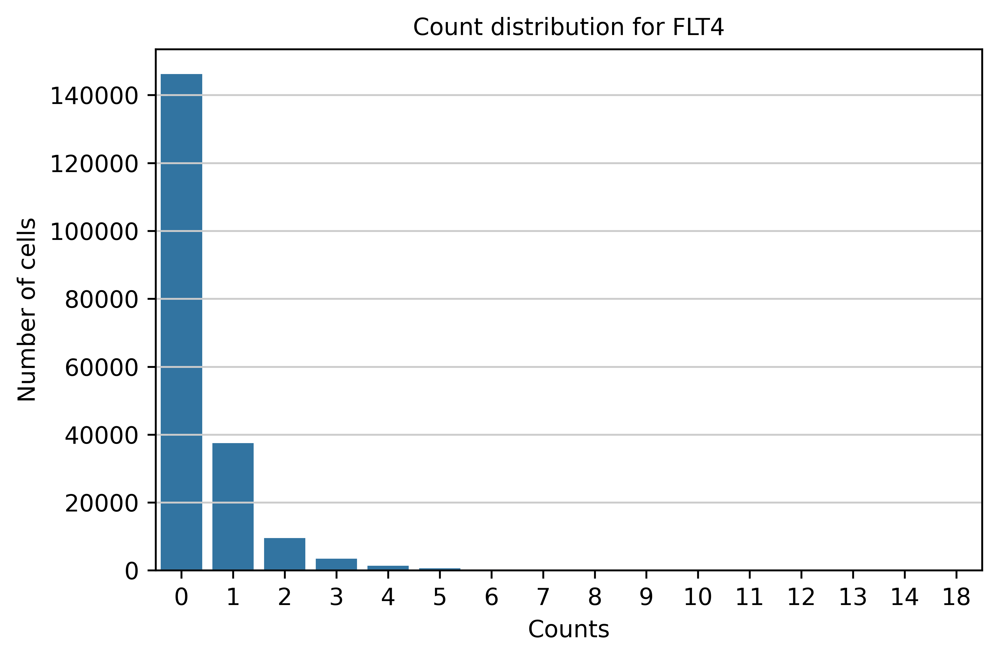

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


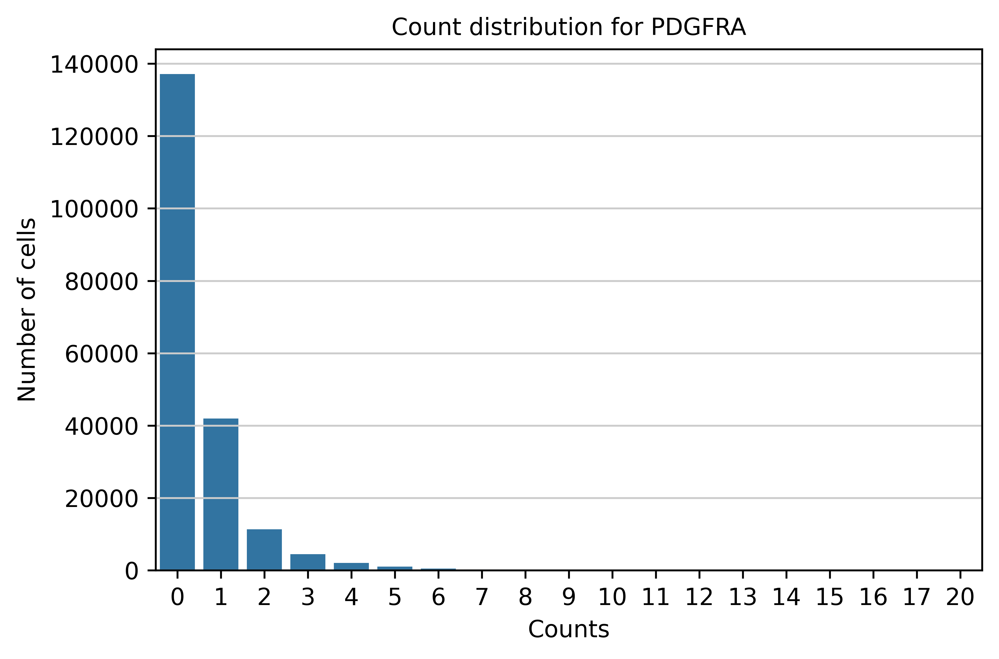

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


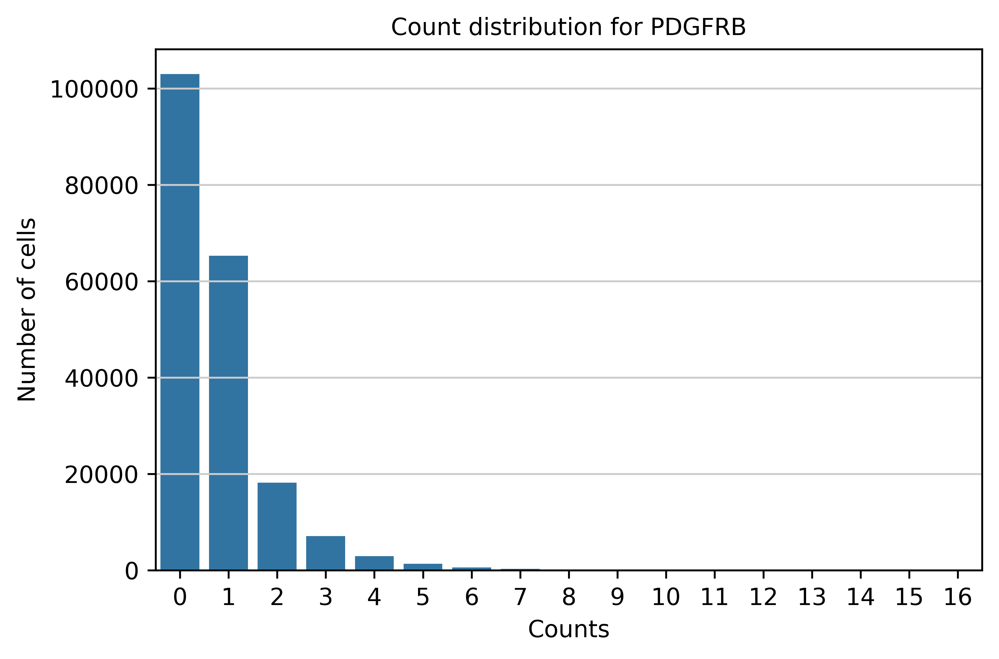

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


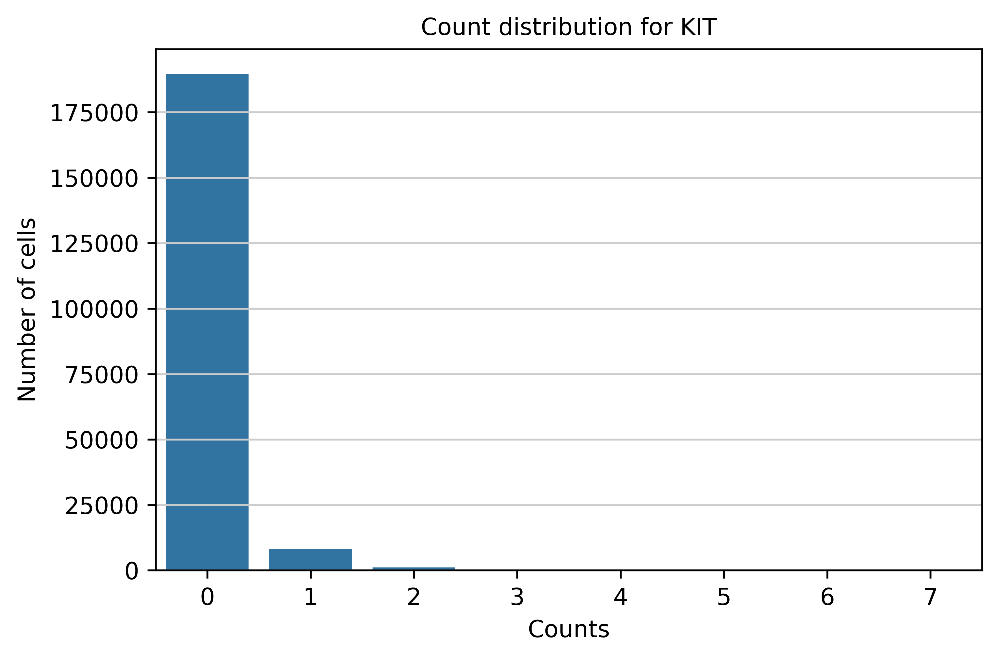

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


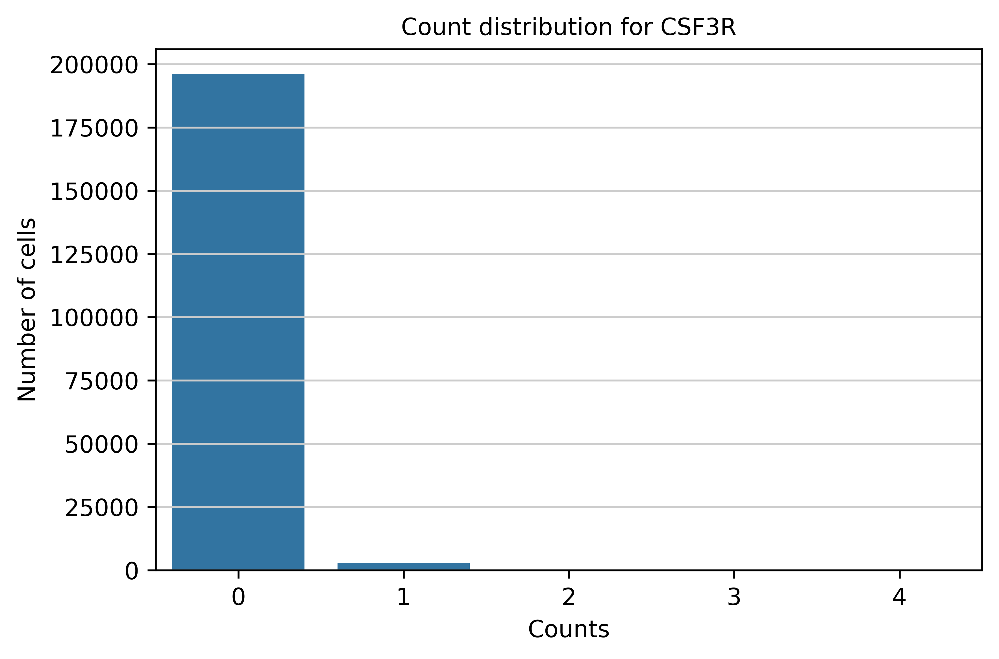

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


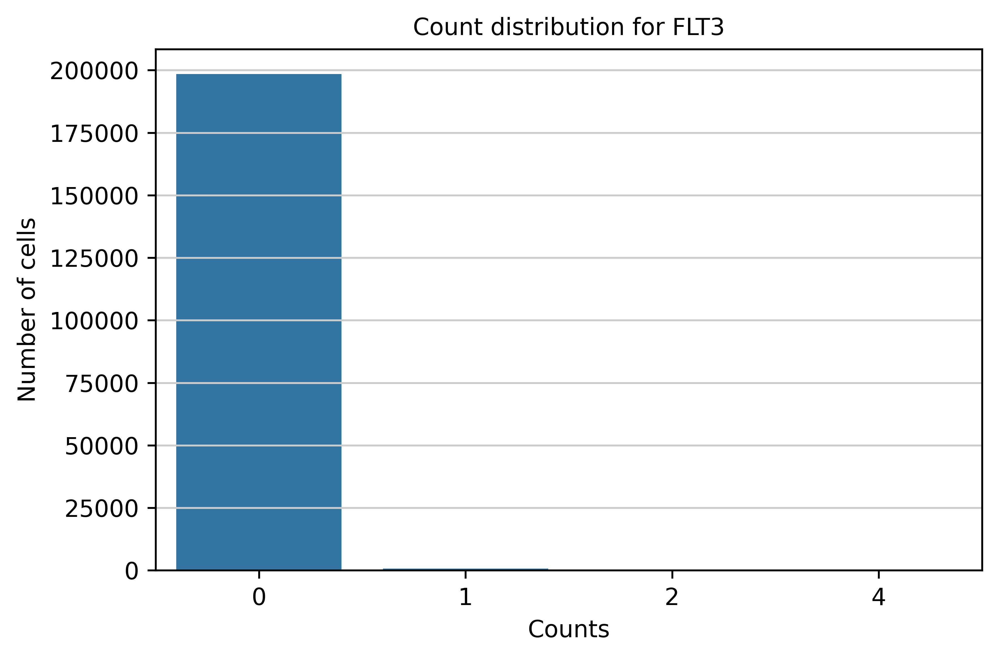

In [185]:
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].X
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

## 2.6 Decode Counts

In [ ]:
import anndata as ad
from app.count_decoder import apply_count_decoder
from app.count_decoder import _spot_level_metrics, _apply_metric_transform, _to_dense
import numpy as np

adata_path = "/nfs/team361/sb75/DATASETS/gold/cell-graph-tokenizer/kidney_perturbation/nemokidneyxeniumatlas_annotated_processed.h5ad"
checkpoint_path = "results/zinb_decoder.pt"  # or a folder with zinb_decoder.pt inside
emb_key = "cell_emb"
checkpoint_path = "results_neb/zinb_decoder.pt"  # or a folder with zinb_decoder.pt inside
emb_key="neighborhood_emb"

adata = ad.read_h5ad(adata_path)

adata = apply_count_decoder(
    adata,
    emb_key=emb_key,
    model_folder_path=checkpoint_path,  # can be folder or exact file
    decoded_counts_layer_key="decoded_counts",
    # optional overrides:
    # loss_type="nb_softplus",
    # device=0,
    # batch_size=1024,
)
 
preds = _to_dense(adata.layers["decoded_counts"])
target = _to_dense(adata.layers["counts"])
target = _to_dense(adata.layers["counts_neighborhood"])

# optional: same transform used in training metrics
preds = _apply_metric_transform(preds, "none")  # or "log1p"
target = _apply_metric_transform(target, "none")

spot_metrics = _spot_level_metrics(preds, target)
print(spot_metrics)

adata.write_h5ad("/path/to/output_with_decoded_counts.h5ad")

In [ ]:
adata = apply_count_decoder(
    adata,
    emb_key='neighborhood_emb',
    model_folder_path='/nfs/team361/mv10/nemo_v6/nichejepa/results_neb/zinb_decoder.pt',
    decoded_counts_layer_key='dec_counts_neighborhood')

In [ ]:
adata = apply_count_decoder(
    adata,
    emb_key='cell_emb',
    model_folder_path='/nfs/team361/mv10/nemo_v6/nichejepa/results/zinb_decoder.pt',
    decoded_counts_layer_key='dec_counts_cell'

In [ ]:
adata = apply_count_decoder(
    adata,
    emb_key='neighborhood_emb_perturb_case1',
    model_folder_path='/nfs/team361/mv10/nemo_v6/nichejepa/results_neb/zinb_decoder.pt',
    decoded_counts_layer_key='dec_counts_perturbed_neighborhood_case1'

In [ ]:
adata = apply_count_decoder(
    adata,
    emb_key='cell_emb_perturb_case1',
    model_folder_path='/nfs/team361/mv10/nemo_v6/nichejepa/results/zinb_decoder.pt',
    decoded_counts_layer_key='dec_counts_perturbed_cell_case1'

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

In [ ]:
diff testing dec_counts_neighborhood <-> dec_counts_perturbed_neighborhood

In [ ]:
# adata.obsm[emb_key] -> adata.layers[decoded_counts_layer_key]

In [ ]:
perturb_df = perturb_df.head(3)

In [ ]:
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    cell_gene_ids=cell_gene_ids,
    neighborhood_gene_ids=neighborhood_gene_ids,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers)

In [ ]:
adata.obsm['perturbed_cell_emb'] = perturbed_output_embed['cell_emb']
adata.obsm['perturbed_neighborhood_emb'] = perturbed_output_embed['neighborhood_emb']

In [ ]:
label = cell_type_key

# Neighborhood embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='perturbed_neighborhood_emb',
                key_added='perturbed_neighborhood')
sc.tl.umap(adata,
           neighbors_key='perturbed_neighborhood',
           key_added='perturbed_neighborhood_umap')
adata.obsm['X_umap'] = adata.obsm['perturbed_neighborhood_umap']
sc.pl.umap(adata,
           neighbors_key='perturbed_neighborhood',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='perturbed_cell_emb',
                key_added='perturbed_cell')
sc.tl.umap(adata,
           neighbors_key='perturbed_cell',
           key_added='perturbed_cell_umap')
adata.obsm['X_umap'] = adata.obsm['perturbed_cell_umap']
sc.pl.umap(adata,
           neighbors_key='perturbed_cell',
           color=label)

In [ ]:
thresh = 0.99
for i, gene in enumerate(pert_genes):
    cell_pert_indices = [i*2]
    
    filtered_dataset = perturbed_dataset.filter(
        lambda x: any(x[f"pert_flag_idx_{i}"] for i in cell_pert_indices)
    )
    
    cell_pert_cell_ids = list(filtered_dataset['cell_id'])
    
    adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]
    
    A = adata_sub_cell_pert.obsm['cell_emb']
    B = adata_sub_cell_pert.obsm['cell_emb_perturb_case2']
    
    A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
    B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)
    
    cos_sim = np.sum(A_norm * B_norm, axis=1)
    print(f"Gene: {gene}")
    print(f"Mean cosine similarity: {np.mean(cos_sim)}")
    print(f"Min cosine similarity: {np.min(cos_sim)}")
    print(f"Smaller than {thresh}: {int((cos_sim < thresh).sum())}/{cos_sim.shape[0]}")